# Quantum Genome Detective — all team work in one notebook

**Run this notebook from top to bottom, section by section.** It is self-contained: every method is defined in
the cells below. It does not use `%run`, repository imports or other notebooks, and it reads no repository files.
The only dependencies are installed Python packages (`requirements.txt`; M3 also needs the optional `mthree`).

| Contributor | Methods in this notebook | Original sources (kept unchanged as the archive) |
|---|---|---|
| **Alexandra Enachescu** | evidence weighting A/B1/B2/C, full-read MEC, tie-aware truth metrics, objective grid, fixed-length and length-dependent-error studies | `docs/Alexandra_Objective_Variants.ipynb`, `docs/objective_study.py`, `docs/fixed_length_experiment.py`, `docs/length_error_experiment.py` (branch `alexandra/objective-variants` @ `bfcb9d4`) |
| **Carla Cotea** | lab tasks A–G, pruning rules and information limits, warm-start and multi-angle QAOA | `docs/Quantum_Genome_Detective_Lab.ipynb`, `docs/Pruning_Track .md` (commit `5be55f9`; branch since deleted) |
| **Tudor-Constantin Pricop** | puzzle generator, referees, local search and annealing, zero-shot QAOA training, simulators, race metrics, plug-in sockets, integration benchmark | `bench/qgd_bench.ipynb`, `bench/tudor_classical_vs_quantum.ipynb`, `bench/plugin_template.ipynb`, `bench/shared_adapters.ipynb` (`6933dde`, `7b147e4`, `bc5c060`) |
| **Alexandru Picioroaga** | shared hardware setup, 11 compilation/mitigation studies, IBM-calibrated local noise option, larger-instance shot-trained QAOA | `docs/hardware_experiments/*` (`bf51921`), Lab sections merged to `main` (`9771f67`) |

**Default run** (a few minutes on a laptop): all definitions, the five-SNP lessons and checks, and the merged benchmark —
one shared input, common full pairwise and full-read MEC references, local training, frozen ideal/noisy replay.
Expensive grids, races and hardware studies are **off** and print their saved original findings instead.
Saved findings are labelled *saved* and come from the contributors' original runs; values printed by this notebook are current
local simulations. **No real QPU job is submitted and no credentials are read unless you enable `RUN_REAL_QPU` or
`RUN_IBM_NOISE_SIM`.** A fake backend is a simulator snapshot, not a device.

**Sections:** 1 Setup · 2 Common input and cost model · 3 Objectives · 4 Pruning and information limits · 5 Classical
comparisons · 6 QAOA variants and frozen training · 7 Ideal and noisy execution · 8 Hardware experiment methods ·
9 Metrics, races and plug-ins · 10 Optional deeper research and scaling · 11 Checks, inventory and conclusions


# 1. Setup and shared controls

Change settings here, then rerun the later sections. `budget(smoke, full)` returns a contributor's original budget only when
`RUN_FULL_STUDIES` is `True`. A larger shared input needs `MAX_EXACT_SNPS` raised deliberately and a backend with enough
qubits; the notebook stops with an explanation instead of trimming reads.


In [1]:
import csv
import importlib.metadata as metadata
import importlib.util
import itertools
import json
import math
import os
import sys
import time
import zlib
from collections import deque
from dataclasses import dataclass, field, replace
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.optimize import OptimizeResult, minimize

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Delay, Parameter, ParameterVector, pauli_twirl_2q_gates
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector
from qiskit.transpiler import PassManager, generate_preset_pass_manager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise.passes import RelaxationNoisePass
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

if sys.version_info < (3, 10):
    raise RuntimeError('Use Python 3.10 or newer.')
print({name: metadata.version(name) for name in
       ('qiskit', 'qiskit-aer', 'qiskit-ibm-runtime', 'numpy', 'scipy', 'pandas')})


{'qiskit': '2.5.0', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.51.0', 'numpy': '2.5.1', 'scipy': '1.18.0', 'pandas': '3.0.3'}


In [2]:
RUN_SHARED_SIZE_STUDY = True  # agreed 8/12-SNP local comparison; no QPU jobs
# ---- what runs ---------------------------------------------------------------------------
RUN_FULL_STUDIES = False      # contributors' grids, sweeps and races at their original budgets (long)
RUN_HARDWARE_STUDIES = False  # Alex's 11 compilation / mitigation studies (FakeManilaV2 + Aer, ~2-3 min)
RUN_SCALING = False           # Tudor's MPS timings and 28-100 SNP race
RUN_KAGGLE_RACE = False       # Tudor's full Kaggle configuration (~43 min on 4 CPUs; original flag BIG)
SLOW_DEMOS = False            # Tudor's slow MPS swap-left timings at 20 and 24 SNPs
RUN_REAL_QPU = False          # submit ONE frozen Lab circuit to IBM hardware (credentials requested only then)
RUN_IBM_NOISE_SIM = False     # fetch IBM calibration data for LOCAL Aer noise; no job is submitted
SAVE_OUTPUTS = False          # write CSV/NPZ/PNG/Markdown study outputs below OUTPUT_DIR
OUTPUT_DIR = Path('all_together_outputs')


def budget(smoke, full):
    """Contributor's original budget when RUN_FULL_STUDIES is True, otherwise the smoke budget."""
    return full if RUN_FULL_STUDIES else smoke


# ---- the shared input and the merged benchmark -----------------------------------------------
READS_OVERRIDE = None         # None = the team's 5-SNP toy; otherwise a reads x SNPs matrix of 0/1/-1
MAX_EXACT_SNPS = 12            # exact enumeration + statevector training guard for the shared input
HARDWARE_BACKEND = FakeManilaV2()   # 5-qubit snapshot; choose a larger fake backend for larger inputs
OBJECTIVE = 'A baseline'      # circuit objective: 'A baseline', 'B1 per-read', 'B2 per-site', 'C deduplicated'
PRUNE_RULE, THRESHOLD = 'mstforest', None   # Carla's rules: none tie net support topk mstforest bridge random strong
P, SHOTS, MAXITER = 1, 512, 60              # merged benchmark depth, shots per mode, COBYLA evaluations
# (COBYLA evaluations, random starts) per circuit. Smoke = previous merged run; full = Carla's Lab budgets (her study used p = 2).
TRAINING_BUDGET = budget({'standard': (MAXITER, 1), 'warm-start': (MAXITER, 1), 'multi-angle': (MAXITER, 1)},
                         {'standard': (100, 5), 'warm-start': (100, 5), 'multi-angle': (500, 5)})

# ---- Tudor's realistic-read generator settings (5% wrong letters, 10% missing) -----------------
REAL = dict(error=0.05, missing=0.1)
quiet = lambda *_: None
pd.set_option('display.precision', 3)


# Shared size study: keep these settings identical across methods.
SHARED_STUDY_SIZES = (8, 12)
SHARED_STUDY_SEEDS = (0, 1, 2)
SHARED_STUDY_DEPTH = 1
SHARED_STUDY_SHOTS = 512
SHARED_STUDY_TRAIN_EVALS = 60
SHARED_STUDY_LOCAL_BUDGET = 128
SHARED_STUDY_LOCAL_RESTARTS = 16
SHARED_STUDY_READS = dict(coverage=6.0, read_len=(2, 4), **REAL)


In [3]:
# IBM access (Alex, main 9771f67). Kept off and credential-free: nothing is read until a toggle is enabled
# and get_ibm_service() is called. The key is never printed or saved.
IBM_BACKEND_NAME = os.environ.get('IBM_BACKEND_NAME', 'ibm_aachen')   # must be authorized for your account
IBM_SERVICE = None


def read_local_env(path):
    values = {}
    if path.is_file():
        for line in path.read_text(encoding='utf-8').splitlines():
            line = line.strip()
            if not line or line.startswith('#') or '=' not in line: continue
            key, value = line.split('=', 1)
            value = value.strip()
            if len(value) >= 2 and value[0] == value[-1] and value[0] in "'\"":
                value = value[1:-1]
            values[key.strip()] = value
    return values


def get_ibm_service():
    global IBM_SERVICE
    if not (RUN_REAL_QPU or RUN_IBM_NOISE_SIM):
        raise RuntimeError('IBM access is off: set RUN_REAL_QPU or RUN_IBM_NOISE_SIM to True first.')
    if IBM_SERVICE is None:
        from qiskit_ibm_runtime import QiskitRuntimeService
        project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                             if (p / '.git').exists() and (p / 'requirements.txt').exists()), Path.cwd())
        local_env = read_local_env(project_root / '.env')
        api_key = (os.environ.get('IBM_API_KEY') or local_env.get('IBM_API_KEY')
                   or getpass('IBM API key (not saved): '))
        instance = (os.environ.get('IBM_INSTANCE_CRN') or os.environ.get('IBM_INSTANCE')
                    or local_env.get('IBM_INSTANCE_CRN') or local_env.get('IBM_INSTANCE', ''))
        options = {'channel': 'ibm_quantum_platform', 'token': api_key}
        if instance:
            options['instance'] = instance
        IBM_SERVICE = QiskitRuntimeService(**options)
    return IBM_SERVICE


# The Lab's Colab setup pinned (and installed) these versions; this notebook only reports them.
PINS = {'qiskit': '2.5.0', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.47.0',
        'numpy': '2.5.1', 'scipy': '1.18.0', 'pandas': '3.0.3',
        'matplotlib': '3.11.0', 'networkx': '3.6.1'}


def installed(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


display(pd.DataFrame([{'package': k, 'installed': installed(k), "Lab pin": v} for k, v in PINS.items()]))
print('IBM access enabled:', RUN_REAL_QPU or RUN_IBM_NOISE_SIM)


,package,installed,Lab pin
0,qiskit,2.5.0,2.5.0
1,qiskit-aer,0.17.2,0.17.2
2,qiskit-ibm-runtime,0.51.0,0.47.0
3,numpy,2.5.1,2.5.1
4,scipy,1.18.0,1.18.0
5,pandas,3.0.3,3.0.3
6,matplotlib,3.11.0,3.11.0
7,networkx,3.6.1,3.6.1


IBM access enabled: False


# 2. Common input and cost model

**Tudor** (engine) and **Carla** (lab tasks A–D). A read is a row of SNP calls: `0`, `1`, or `-1` (not covered).
An answer `x` is copy A with SNP 1 first; `1 - x` is copy B. Spins are `z = 1 - 2x`. `A[i, j]`/`D[i, j]` count same/opposite
votes for `i < j`, and `cost(x) = offset + Σ J_ij z_i z_j` with `J = (D - A) / 2` and `offset = Σ (A + D) / 2`.
Qiskit count keys are reversed: the rightmost character is qubit 0 = SNP 1 (`decode_key`). Truth is used only for grading.


In [4]:
QGD_QUIET = False   # Tudor's flag: False shows the engine's small examples

REGISTRY: dict[str, dict] = globals().get("REGISTRY") or {
    "evidence": {}, "qaoa": {}, "trainer": {}, "postprocess": {}, "backend": {}}


def register(kind, name):
    def deco(fn):
        REGISTRY[kind][name] = fn
        return fn
    return deco


In [5]:
@dataclass
class Instance:
    name: str
    reads: np.ndarray                 # (R, N): 0 / 1, or -1 where the read has no letter
    truth: np.ndarray | None = None   # hidden copy A; only used for reporting, never for solving
    params: dict = field(default_factory=dict)

    @property
    def n(self):
        return self.reads.shape[1]


TOY_READS = np.array([[0, 1, 1, -1, -1], [1, 0, 0, -1, -1], [-1, 1, 1, 0, -1], [-1, 0, 0, 1, -1],
                      [-1, -1, 1, 0, 1], [-1, -1, 0, 1, 0], [0, -1, -1, 0, 1], [1, -1, -1, 1, 0],
                      [0, 0, -1, -1, -1]])


def toy_instance():
    return Instance("toy5", TOY_READS.copy(), np.array([0, 1, 1, 0, 1]), {"source": "notebook"})


def show_reads(reads, truth=None):
    """Print reads as a grid: 0 / 1, '.' where the read has no letter."""
    for r, row in enumerate(np.asarray(reads)):
        print(f"read {r + 1:>2}   " + " ".join("." if v < 0 else str(v) for v in row))
    if truth is not None:
        print("truth     " + " ".join(map(str, truth)) + "   <- copy A (copy B is its mirror)")


if not QGD_QUIET:
    show_reads(TOY_READS, toy_instance().truth)


read  1   0 1 1 . .
read  2   1 0 0 . .
read  3   . 1 1 0 .
read  4   . 0 0 1 .
read  5   . . 1 0 1
read  6   . . 0 1 0
read  7   0 . . 0 1
read  8   1 . . 1 0
read  9   0 0 . . .
truth     0 1 1 0 1   <- copy A (copy B is its mirror)


In [6]:
def make_instance(n, coverage=6.0, read_len=(2, 4), error=0.0, missing=0.0, gaps=0, seed=0):
    """Synthetic reads drawn from a hidden haplotype pair (truth, 1 - truth)."""
    rng = np.random.default_rng(seed)
    truth = rng.integers(0, 2, n)
    hi = min(read_len[1], n)
    lo = max(2, min(read_len[0], hi))
    cuts = sorted(rng.choice(np.arange(1, n), size=min(gaps, n - 1), replace=False).tolist()) if gaps else []
    reads = []

    def add(start, stop, drop=True):
        for c in cuts:                      # a read never crosses a gap
            if start < c < stop:
                stop = c
                break
        if stop - start < 2:
            return
        seg = (truth if rng.random() < 0.5 else 1 - truth)[start:stop].copy()   # copy A or copy B
        seg[rng.random(seg.size) < error] ^= 1                                  # sequencing errors
        if drop and missing:
            seg[rng.random(seg.size) < missing] = -1                            # letters not read
        row = np.full(n, -1)
        row[start:stop] = seg
        reads.append(row)

    for _ in range(max(1, math.ceil(coverage * n / ((lo + hi) / 2)))):
        length = int(rng.integers(lo, hi + 1))
        start = int(rng.integers(0, n - length + 1))
        add(start, start + length)
    # repair: every neighbouring pair inside a block gets at least one vote
    R = np.array(reads) if reads else np.full((0, n), -1)
    linked = ((R[:, :-1] >= 0) & (R[:, 1:] >= 0)).any(axis=0)
    for i in np.flatnonzero(~linked):
        if i + 1 not in cuts:
            add(int(i), int(i) + 2, drop=False)
    params = dict(coverage=coverage, read_len=f"{lo}-{hi}", error=error, missing=missing, gaps=gaps, seed=seed)
    return Instance(f"n{n}-s{seed}", np.array(reads), truth, params)


if not QGD_QUIET:
    demo = make_instance(10, error=0.05, missing=0.1, seed=1)
    show_reads(demo.reads, demo.truth)


read  1   . . 0 0 0 1 . . . .
read  2   . . . . 0 0 . . . .
read  3   . . 1 1 . . . . . .
read  4   . 1 1 1 . . . . . .
read  5   . . . 1 0 0 1 . . .
read  6   . . . . . 0 1 . 0 .
read  7   . . . . . . 0 0 0 1
read  8   . . . . 1 1 . 0 . .
read  9   . . . . . . . 0 1 1
read 10   1 0 . . . . . . . .
read 11   . 0 1 1 0 . . . . .
read 12   . . . 0 1 . . . . .
read 13   . 0 0 0 1 . . . . .
read 14   . . . 0 1 . . . . .
read 15   . . 1 1 0 . . . . .
read 16   . . . . 1 1 0 . . .
read 17   . . . . 0 0 . . . .
read 18   . . . . . 1 0 0 1 .
read 19   . . 1 1 0 0 . . . .
read 20   . . . . . . 1 1 0 .
truth     0 1 1 1 0 0 1 1 0 0   <- copy A (copy B is its mirror)


**Shared reads.** Every method below that works on "the input" uses `READS`. Lessons and studies that generate their own
synthetic data (Alexandra's grid, Carla's sweep, Tudor's races, Alex's larger instances) say so explicitly.


In [7]:
# The team's toy: nine reads over five SNPs; the last fragment contradicts the SNP 1-2 evidence.
READS = TOY_READS.copy() if READS_OVERRIDE is None else np.asarray(READS_OVERRIDE).copy()
if READS.ndim != 2 or READS.shape[0] == 0 or not np.isin(READS, [-1, 0, 1]).all():
    raise ValueError('READS must be a non-empty 2-D matrix of 0, 1 and -1 (missing).')
N = READS.shape[1]
if not 1 <= N <= MAX_EXACT_SNPS:
    raise ValueError(f'The exact shared benchmark supports 1-{MAX_EXACT_SNPS} SNPs; got {N}. '
                     'Use section 10 for larger inputs or raise MAX_EXACT_SNPS deliberately.')
show_reads(READS, toy_instance().truth if np.array_equal(READS, TOY_READS) else None)


read  1   0 1 1 . .
read  2   1 0 0 . .
read  3   . 1 1 0 .
read  4   . 0 0 1 .
read  5   . . 1 0 1
read  6   . . 0 1 0
read  7   0 . . 0 1
read  8   1 . . 1 0
read  9   0 0 . . .
truth     0 1 1 0 1   <- copy A (copy B is its mirror)


### Votes, costs and bit order (Tudor's vectorized engine)


In [8]:
@register("evidence", "pairwise")
def pairwise_evidence(reads):
    """Vectorised build_evidence from the notebook: upper-triangular same / opposite vote counts."""
    R = np.asarray(reads)
    one = (R == 1).astype(float)    # float, not int: numpy only has the fast (BLAS) matrix product for floats;
    zero = (R == 0).astype(float)   # vote counts are small whole numbers, so floats hold them exactly
    same = (one.T @ one + zero.T @ zero).astype(np.int64)
    opposite = (one.T @ zero + zero.T @ one).astype(np.int64)
    return np.triu(same, 1), np.triu(opposite, 1)


In [9]:
def ising(A, D):
    A, D = np.triu(np.asarray(A, float), 1), np.triu(np.asarray(D, float), 1)
    return (D - A) / 2, float((A + D).sum() / 2)


def costs(X, J, offset):
    """Cost of each row of X (0/1, SNP 1 first)."""
    Z = 1.0 - 2.0 * np.asarray(X, float)
    return offset + ((Z @ J) * Z).sum(axis=1)


def bits(k, n):
    """Basis indices -> 0/1 rows; bit i of k is SNP i + 1 (Qiskit qubit i)."""
    return ((np.asarray(k, np.int64)[:, None] >> np.arange(n)) & 1).astype(np.int8)


def decode_key(key, n):
    """Qiskit count key -> bit array with SNP 1 first (same as the notebook)."""
    s = str(key).replace(" ", "")
    if len(s) != n or set(s) - {"0", "1"}:
        raise ValueError("Expected n measured binary bits.")
    return np.array([int(b) for b in s[::-1]], dtype=np.int8)


if not QGD_QUIET:
    A, D = pairwise_evidence(TOY_READS)
    J, offset = ising(A, D)
    print("toy: A[SNP1, SNP2] =", A[0, 1], " D[SNP1, SNP2] =", D[0, 1], " J[SNP1, SNP2] =", J[0, 1])
    print("offset (notebook c0) =", offset)
    for label, x in [("truth 01101", [0, 1, 1, 0, 1]), ("mirror 10010", [1, 0, 0, 1, 0]), ("all zeros", [0] * 5)]:
        print(f"cost({label}) = {costs([x], J, offset)[0]:g}")


toy: A[SNP1, SNP2] = 1  D[SNP1, SNP2] = 2  J[SNP1, SNP2] = 0.5
offset (notebook c0) = 12.5
cost(truth 01101) = 1
cost(mirror 10010) = 1
cost(all zeros) = 16


### The lab foundation (Carla's implementations of tasks A–D)
The picture reveals the synthetic teaching pair for intuition only; it is drawn only for the toy input.
Carla's `decode_key` is identical to the engine's and is not redefined; its bit-order assert is kept.


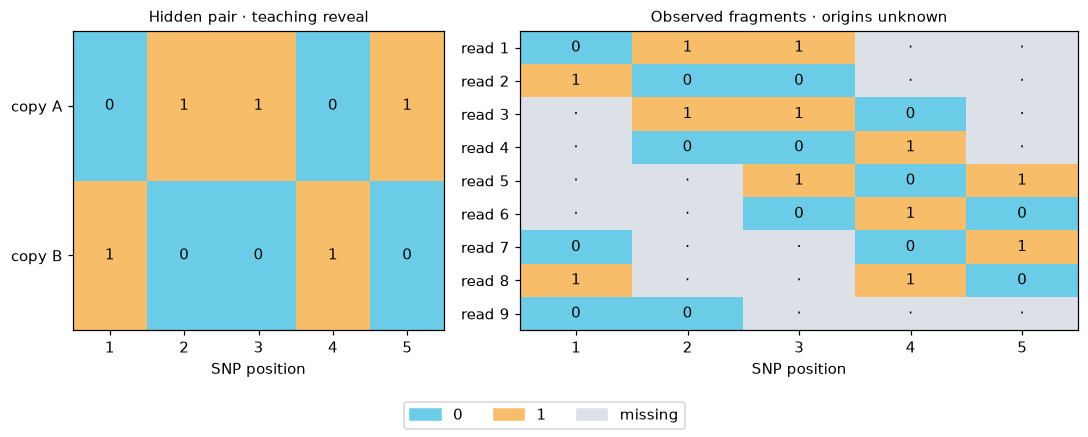

In [10]:
# Truth is for this teaching picture only; no scoring/training function receives it.
TEACHING_PAIR = np.array([[0,1,1,0,1], [1,0,0,1,0]])
CYAN, GOLD, GREY = '#6ACCE6', '#F7BD69', '#DCE1E8'
plt.rcParams.update({'figure.dpi':110, 'font.size':10})
def show_reads_figure():
    fig, axes = plt.subplots(1,2,figsize=(10,4),gridspec_kw={'width_ratios':[1,1.5]})
    for ax, data, title, labels in zip(axes, [TEACHING_PAIR,READS],
            ['Hidden pair · teaching reveal','Observed fragments · origins unknown'],
            [['copy A','copy B'], [f'read {i+1}' for i in range(len(READS))]]):
        ax.imshow(data+1,cmap=ListedColormap([GREY,CYAN,GOLD]),vmin=0,vmax=2,aspect='auto')
        ax.set_xticks(range(N),[str(i+1) for i in range(N)]);ax.set_xlabel('SNP position')
        ax.set_yticks(range(len(data)),labels);ax.set_title(title,fontsize=10)
        for (r,c),v in np.ndenumerate(data): ax.text(c,r,'·' if v<0 else str(v),ha='center',va='center')
    fig.legend(handles=[Patch(color=CYAN,label='0'),Patch(color=GOLD,label='1'),
                        Patch(color=GREY,label='missing')],loc='lower center',ncol=3)
    fig.tight_layout(rect=(0,.09,1,1));plt.show()
def show_graph(a,d):
    g=nx.Graph();g.add_nodes_from(range(len(a)))
    fig,ax=plt.subplots(figsize=(6,4));pos=nx.circular_layout(g)
    nx.draw_networkx_nodes(g,pos,ax=ax,node_color=GREY,node_size=650)
    nx.draw_networkx_labels(g,pos,labels={i:str(i+1) for i in g},ax=ax)
    labels={}
    for i,j in itertools.combinations(g,2):
        if a[i,j]+d[i,j]==0: continue
        net=a[i,j]-d[i,j]
        nx.draw_networkx_edges(g,pos,edgelist=[(i,j)],ax=ax,
            edge_color=CYAN if net>0 else GOLD if net<0 else GREY,
            style='solid' if net>0 else 'dashed' if net<0 else 'dotted',
            width=1+abs(net))
        labels[i,j]=f'{int(a[i,j])}/{int(d[i,j])}'
    nx.draw_networkx_edge_labels(g,pos,edge_labels=labels,font_size=8,ax=ax)
    ax.set_title('Same / opposite votes · width = net strength')
    ax.legend(handles=[Patch(color=CYAN,label='same'),Patch(color=GOLD,label='opposite'),
                       Patch(color=GREY,label='tie')],loc='lower center',ncol=3,bbox_to_anchor=(.5,-.12))
    ax.axis('off');fig.tight_layout();plt.show()
def text(x): return ''.join(map(str,x))  # SNP 1 first, unlike a Qiskit key
# Qiskit displays qubit 0 on the RIGHT; never reverse a physical layout again.
assert np.array_equal(decode_key('00101',5),[1,0,1,0,0])
if np.array_equal(READS, TOY_READS):
    show_reads_figure()


**Task A** — same/opposite vote counts for all co-observed pairs (upper triangle).


In [11]:
def build_evidence(reads):
    n = len(reads[0])
    a = np.zeros((n, n), dtype=int)
    d = np.zeros((n, n), dtype=int)

    for read in reads:
        observed = []
        for i in range(len(read)):
            if read[i] != -1:
                observed.append(i)

        for p in range(len(observed)):
            for q in range(p + 1, len(observed)):
                i = observed[p]
                j = observed[q]

                if read[i] == read[j]:
                    a[i, j] += 1
                else:
                    d[i, j] += 1

    return a, d


Evidence checks passed. Labels are same/opposite counts, not probability of truth.


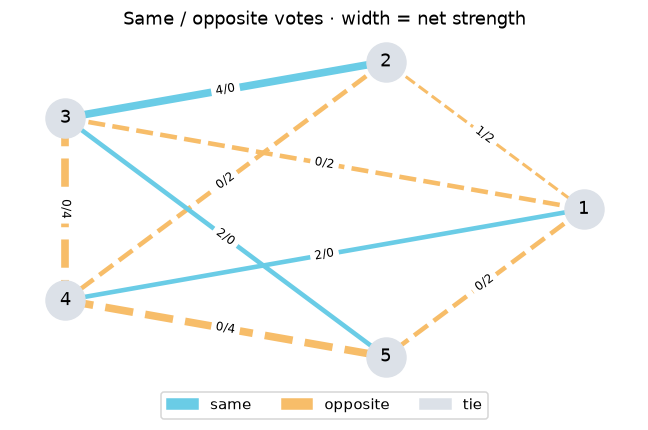

In [12]:
tiny=np.array([[0,1,1],[1,0,0],[0,0,-1]])
ta,td=build_evidence(tiny)
assert np.array_equal(ta,[[0,1,0],[0,0,2],[0,0,0]]), 'Check same votes and upper triangle.'
assert np.array_equal(td,[[0,2,2],[0,0,0],[0,0,0]]), 'Count all observed pairs, skipping missing calls.'
LAB_A,LAB_D=build_evidence(READS)
assert LAB_A.shape==LAB_D.shape==(N,N)
assert np.all(np.tril(LAB_A)==0) and np.all(np.tril(LAB_D)==0)
print('Evidence checks passed. Labels are same/opposite counts, not probability of truth.')
show_graph(LAB_A,LAB_D)


**Task B** — pairwise cost: pay one penalty for each pair vote the candidate contradicts.


In [13]:
def pairwise_cost(x, a, d):
    cost = 0
    for j in range(len(x)):
        for i in range(j):
            if x[i] != x[j]:
                cost += a[i, j]
            else:
                cost += d[i, j]
    return cost


In [14]:
assert pairwise_cost([0,1,1],ta,td)==1, 'Compare each pair against its votes.'
assert pairwise_cost([0,0,1],ta,td)==4, 'Count the minority votes too.'
for x in itertools.product([0,1],repeat=N):
    assert pairwise_cost(x,LAB_A,LAB_D)==pairwise_cost(1-np.array(x),LAB_A,LAB_D), 'Copy names must not matter.'
print('Manual-score and complement-symmetry checks passed.')


Manual-score and complement-symmetry checks passed.


**Task C** — exact reference by enumerating all `2**N` labels (complements kept).


In [15]:
def exact_reference(a, d):
    states = np.array(list(itertools.product([0, 1], repeat=len(a))), dtype=int)
    costs = np.array([pairwise_cost(x, a, d) for x in states], dtype=float)
    return states, costs


In [16]:
LAB_STATES,LAB_COSTS=exact_reference(LAB_A,LAB_D)
assert LAB_STATES.shape==(2**N,N) and LAB_COSTS.shape==(2**N,), 'Return all states and one cost per row.'
assert set(map(tuple,LAB_STATES))==set(itertools.product([0,1],repeat=N)), 'Missing or repeated states.'
assert np.allclose(LAB_COSTS,[pairwise_cost(x,LAB_A,LAB_D) for x in LAB_STATES]), 'Costs must match states.'
LAB_OPTIMUM=float(LAB_COSTS.min())
display(pd.DataFrame({'candidate (SNP 1 first)':[text(x) for x in LAB_STATES], 'cost':LAB_COSTS})
        .sort_values('cost',kind='stable').reset_index(drop=True))
print('Exact minimum:',LAB_OPTIMUM,'| optimal labels:',sum(np.isclose(LAB_COSTS,LAB_OPTIMUM)))


,candidate (SNP 1 first),cost
0,01101,1.0
1,10010,1.0
2,00010,8.0
3,00101,8.0
4,11010,8.0
5,11101,8.0
6,01100,9.0
7,10011,9.0
8,00001,12.0
9,00011,12.0


Exact minimum: 1.0 | optimal labels: 2


**Task D** — the same graph as an Ising Hamiltonian; checked on every state.


In [17]:
def ising_from_evidence(a, d):
    couplings = (d - a) / 2
    offset = 0
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            offset += (a[i, j] + d[i, j]) / 2
    return couplings, offset


def ising_energy(x, couplings, offset):
    z = 1 - 2 * np.asarray(x)
    energy = offset

    for i in range(len(x)):
        for j in range(i + 1, len(x)):
            energy += couplings[i, j] * z[i] * z[j]

    return energy


In [18]:
LAB_J,LAB_OFFSET=ising_from_evidence(LAB_A,LAB_D)
assert np.allclose(LAB_J,(LAB_D-LAB_A)/2), 'Negative coupling favors same; use upper triangle only.'
assert np.isclose(LAB_OFFSET,(LAB_A+LAB_D).sum()/2), 'Keep the constant for reported energies.'
assert all(np.isclose(ising_energy(x,LAB_J,LAB_OFFSET),c) for x,c in zip(LAB_STATES,LAB_COSTS)), 'Check spin conversion and pair counting.'
print('Ising equals graph cost on all',2**N,'states. Couplings:')
display(pd.DataFrame(LAB_J,index=range(1,N+1),columns=range(1,N+1)))


Ising equals graph cost on all 32 states. Couplings:


,1,2,3,4,5
1,0.0,0.5,1.0,-1.0,1.0
2,0.0,0.0,-2.0,1.0,0.0
3,0.0,0.0,0.0,2.0,-1.0
4,0.0,0.0,0.0,0.0,2.0
5,0.0,0.0,0.0,0.0,0.0


### Exact referees (Tudor)
`diag_energies` lists all `2^N` Ising energies by doubling (brute force up to ~24 SNPs); `banded_exact` is a band dynamic
program that is linear in N for short reads.


In [19]:
def diag_energies(J):
    """sum_{i<j} J_ij z_i z_j for every basis index (bit i = qubit i), built by doubling in O(2^n)."""
    E = np.zeros(1)
    for q in range(len(J)):
        f = np.zeros(1)
        for m in range(q):
            f = np.concatenate([f + J[m, q], f - J[m, q]])
        E = np.concatenate([E + f, E - f])
    return E


In [20]:
def bandwidth(J):
    i, j = np.nonzero(np.triu(J, 1))
    return int((j - i).max()) if len(i) else 0


def banded_exact(J, offset, max_band=16):
    """Exact optimum by dynamic programming over a sliding window of the last w SNPs, O(N * 2^w).

    Returns None if the band is wider than max_band.
    """
    n, w = len(J), bandwidth(J)
    if w == 0:
        return offset
    if w > max_band:
        return None
    s = np.arange(2 ** w)
    Zs = 1.0 - 2.0 * ((s[:, None] >> np.arange(w)) & 1)   # bit t of the state = SNP (i - 1 - t)
    V = np.zeros(2 ** w)
    for i in range(n):
        col = np.array([J[i - 1 - t, i] if i - 1 - t >= 0 else 0.0 for t in range(w)])
        lin = Zs @ col                                     # coupling of SNP i to each window state
        new = np.empty_like(V)
        for b, zb in ((0, 1.0), (1, -1.0)):
            cand = (V + zb * lin).reshape(2, -1).min(axis=0)   # drop the oldest bit
            new[(np.arange(2 ** (w - 1)) << 1) | b] = cand
        V = new
    return offset + float(V.min())


if not QGD_QUIET:
    demo = make_instance(14, error=0.05, missing=0.1, seed=2)
    J, offset = ising(*pairwise_evidence(demo.reads))
    print("14 SNPs, band", bandwidth(J), "| brute force:", offset + diag_energies(J).min(), "| band DP:", banded_exact(J, offset))
    big = make_instance(1000, error=0.05, missing=0.1, seed=2)
    J, offset = ising(*pairwise_evidence(big.reads))
    t = time.time()
    best = banded_exact(J, offset)
    print(f"1000 SNPs: exact optimum {best:g} in {time.time() - t:.3f} s (2^1000 answers)")


14 SNPs, band 3 | brute force: 6.0 | band DP: 6.0


1000 SNPs: exact optimum 490 in 0.034 s (2^1000 answers)


# 3. Objectives and evidence weighting (Alexandra)

**Question:** does pair-vote expansion overcount long reads, and does normalization improve phasing recovery?
Variants: **A** baseline (weight 1 per pair), **B1** per-read `2/(L(L-1))`, **B2** per-site `1/(L-1)`, **C** exact-row
deduplication, **D** full-read MEC (classical reference only, never a pairwise RZZ Hamiltonian). Controls: identical reads and
seeds across variants, exact enumeration, uniform tie policy (never choose a minimizer with truth). Native costs have different
units; compare variants only after rescoring on common references. Prepared with AI assistance (author's disclosure).


In [21]:
# objective_study.py: weights, graphs, pairwise and MEC scores, tie-aware metrics
VARIANTS = ('A baseline', 'B1 per-read', 'B2 per-site', 'C deduplicated', 'D MEC')
LENGTHS = {'short': (0.7, 0.3, 0.0, 0.0),
           'mixed': (0.25, 0.25, 0.25, 0.25),
           'long': (0.0, 0.0, 0.3, 0.7)}


def baseline_weight(length):
    return 1.0


def per_read_weight(length):
    return 2.0 / (length * (length - 1)) if length >= 2 else 0.0


def per_site_weight(length):
    return 1.0 / (length - 1) if length >= 2 else 0.0


def build_graph(reads, weight_fn=baseline_weight):
    """Return upper-triangular A, D, J and constant offset; preserve floats."""
    reads = np.asarray(reads)
    a = np.zeros((reads.shape[1], reads.shape[1]), dtype=float)
    d = np.zeros_like(a)
    for read in reads:
        observed = np.flatnonzero(read != -1)
        weight = weight_fn(len(observed)) if len(observed) >= 2 else 0.0
        for i, j in itertools.combinations(observed, 2):
            if read[i] == read[j]:
                a[i, j] += weight
            else:
                d[i, j] += weight
    return a, d, (d - a) / 2, float((a + d).sum() / 2)


def all_states(n):
    return np.array(list(itertools.product((0, 1), repeat=n)), dtype=int)


def pairwise_scores(states, a, d):
    scores = np.zeros(len(states), dtype=float)
    for i, j in itertools.combinations(range(states.shape[1]), 2):
        scores += np.where(states[:, i] == states[:, j], d[i, j], a[i, j])
    return scores


def mec_scores(states, reads):
    """Per read, choose its closest copy. Ignore missing calls, including empty reads."""
    scores = np.zeros(len(states), dtype=float)
    for read in reads:
        observed = read != -1
        mismatches = np.sum(states[:, observed] != read[observed], axis=1)
        scores += np.minimum(mismatches, observed.sum() - mismatches)
    return scores


def objective_scores(reads, states):
    graphs = {
        VARIANTS[0]: build_graph(reads),
        VARIANTS[1]: build_graph(reads, per_read_weight),
        VARIANTS[2]: build_graph(reads, per_site_weight),
        VARIANTS[3]: build_graph(np.unique(reads, axis=0)),
    }
    scores = {name: pairwise_scores(states, graph[0], graph[1])
              for name, graph in graphs.items()}
    scores[VARIANTS[4]] = mec_scores(states, reads)
    return scores, graphs


def evaluate(candidate, truth):
    distance = int(np.count_nonzero(np.asarray(candidate) != truth))
    errors = min(distance, len(truth) - distance)
    return {'hamming_errors': errors, 'exact_match': int(errors == 0)}


def optimal_mask(scores):
    return np.isclose(scores, np.min(scores), rtol=0, atol=1e-9)


def score_metrics(states, scores, truth):
    """Uniform tie policy: never select a minimizer using hidden truth.

    Average metrics over ALL minimizing labels, equivalent to uniform tie breaking.
    Complementary labels count as one biological phasing.
    """
    winners = optimal_mask(scores)
    distances = np.count_nonzero(states != truth, axis=1)
    errors = np.minimum(distances, len(truth) - distances)
    truth_index = np.flatnonzero(np.all(states == truth, axis=1))[0]
    truth_cost = scores[truth_index]
    return {
        'mean_hamming': float(errors[winners].mean()),
        'recovery': float(np.mean(errors[winners] == 0)),
        'truth_is_optimal': int(winners[truth_index]),
        'unique_truth': int(winners[truth_index] and winners.sum() == 2),
        'tied_labels': int(winners.sum()),
        'tied_phasings': int(winners.sum() // 2),
        'truth_rank': 1 + int(np.sum(scores < truth_cost - 1e-9)) // 2,
        'minimum': float(scores.min()),
    }


In [22]:
# objective_study.py: generator, study runner, summaries, CSV and plots (plots display inline; files only with SAVE_OUTPUTS)
def generate_reads(truth, n_reads, length_mode, error_rate, missing_rate, seed):
    """IID reads: random copy, contiguous interval length 2..5, then missingness/errors.

    Length mode refers to interval length BEFORE independent missing calls.
    Identical rows arise naturally; no PCR-duplication model is assumed.
    """
    rng = np.random.default_rng(seed)
    n = len(truth)
    if n != 5:
        raise ValueError('This experiment defines length distributions for exactly 5 SNPs.')
    reads = np.full((n_reads, n), -1, dtype=int)
    for row in reads:
        length = int(rng.choice([2, 3, 4, 5], p=LENGTHS[length_mode]))
        start = int(rng.integers(n - length + 1))
        positions = np.arange(start, start + length)
        copy = truth if rng.integers(2) == 0 else 1 - truth
        calls = copy[positions].copy()
        calls ^= (rng.random(length) < error_rate).astype(int)
        calls[rng.random(length) < missing_rate] = -1
        row[positions] = calls
    return reads


def make_manifest(repeats=200):
    settings = [dict(length_mode=mode, error_rate=error, missing_rate=missing,
                     n_reads=count)
                for mode in LENGTHS for error in (0.0, 0.02, 0.05, 0.1)
                for missing in (0.0, 0.25) for count in (6, 12, 24)]
    return {'n_snps': 5, 'repeats': repeats,
            'truth_seed_base': 100_000, 'read_seed_base': 200_000,
            'seeds': [dict(replicate=i, truth_seed=100_000+i, read_seed=200_000+i)
                      for i in range(repeats)],
            'seed_policy': 'Seed bases + replicate index; same seeds across settings.',
            'settings': settings,
            'tie_policy': 'Uniform over all exact minimizing labels; no truth selection.',
            'generator': 'Contiguous intervals; IID errors and missing calls; random copy.',
            'metrics': 'Truth rank and ties count complementary labels as one phasing.'}


def run_study(manifest, output_dir=None):
    states = all_states(manifest['n_snps'])
    rows, cases, datasets = [], [], {}
    seeds = manifest['seeds']
    if len(seeds) != manifest['repeats']:
        raise ValueError('Seed list must match the requested number of replicates.')
    for setting_id, setting in enumerate(manifest['settings']):
        setting_reads, setting_truths = [], []
        for replicate, seed_pair in enumerate(seeds):
            truth_seed, read_seed = seed_pair['truth_seed'], seed_pair['read_seed']
            truth = np.random.default_rng(truth_seed).integers(2, size=manifest['n_snps'])
            reads = generate_reads(truth, seed=read_seed, **setting)
            setting_reads.append(reads)
            setting_truths.append(truth)
            scores, _ = objective_scores(reads, states)
            baseline_winners = optimal_mask(scores[VARIANTS[0]])
            lengths = np.sum(reads != -1, axis=1)
            for name, costs in scores.items():
                row = dict(setting_id=setting_id, replicate=replicate,
                           truth_seed=truth_seed, read_seed=read_seed, **setting,
                           variant=name, observed_mean_length=float(lengths.mean()),
                           **score_metrics(states, costs, truth))
                row['disagrees_baseline'] = int(not np.array_equal(
                    baseline_winners, optimal_mask(costs)))
                rows.append(row)
            if len(cases) < 12 and not np.array_equal(
                    baseline_winners, optimal_mask(scores[VARIANTS[1]])):
                cases.append(dict(setting_id=setting_id, replicate=replicate,
                                  **setting, truth=truth.tolist(), reads=reads.tolist(),
                                  candidates=states.tolist(),
                                  scores={k: v.tolist() for k, v in scores.items()},
                                  optima={k: states[optimal_mask(v)].tolist()
                                          for k, v in scores.items()}))
        datasets[f'reads_{setting_id}'] = np.array(setting_reads)
        datasets[f'truth_{setting_id}'] = np.array(setting_truths)
    if output_dir is not None:
        np.savez_compressed(Path(output_dir) / 'datasets.npz', **datasets)
    return rows, cases


def mean_ci(values):
    """Approximate 95% normal CI for a mean of independent replicate-level metrics."""
    values = np.asarray(values, dtype=float)
    mean = float(values.mean())
    se = float(values.std(ddof=1) / np.sqrt(len(values))) if len(values) > 1 else 0.0
    return mean, mean - 1.96 * se, mean + 1.96 * se


def summarize_objectives(rows):
    groups = {}
    for row in rows:
        groups.setdefault((row['setting_id'], row['variant']), []).append(row)
    summaries = []
    for (_, variant), group in groups.items():
        first = group[0]
        out = {key: first[key] for key in
               ('setting_id', 'length_mode', 'error_rate', 'missing_rate', 'n_reads')}
        out.update(variant=variant, replicates=len(group))
        for metric in ('recovery', 'mean_hamming', 'truth_is_optimal', 'unique_truth',
                       'tied_phasings', 'truth_rank', 'observed_mean_length',
                       'disagrees_baseline'):
            mean, low, high = mean_ci([r[metric] for r in group])
            if metric == 'recovery':
                low, high = max(0.0, low), min(1.0, high)
            elif metric in ('truth_is_optimal', 'unique_truth', 'disagrees_baseline'):
                # Wilson interval for binary indicators; recovery can be fractional.
                z, n = 1.96, len(group)
                center = (mean + z*z/(2*n))/(1 + z*z/n)
                half = z * np.sqrt(mean*(1-mean)/n + z*z/(4*n*n))/(1+z*z/n)
                low, high = center-half, center+half
            out[metric] = mean
            out[metric + '_ci_low'], out[metric + '_ci_high'] = low, high
        summaries.append(out)
    return summaries


def write_csv(path, rows):
    with Path(path).open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def plot_results(summary, output_dir):
    import matplotlib.pyplot as plt
    output_dir = None if output_dir is None else Path(output_dir)
    # Hold missingness and coverage fixed; never pool different conditions.
    fixed = [r for r in summary if r['missing_rate'] == 0 and r['n_reads'] == 12]
    repeats = fixed[0]['replicates']
    plots = [
        ('length', 'error_rate', (0, 0.02, 0.05, 0.1),
         'observed_mean_length', 'Mean observed read length'),
        ('error', 'length_mode', tuple(LENGTHS),
         'error_rate', 'Per-call error probability'),
    ]
    for filename, panel_key, panels, x_key, xlabel in plots:
        fig, axes = plt.subplots(1, len(panels), figsize=(4.5*len(panels), 4), sharey=True)
        for ax, panel in zip(axes, panels):
            for name in VARIANTS:
                points = sorted([r for r in fixed if r[panel_key] == panel and
                                 r['variant'] == name], key=lambda r: r[x_key])
                ax.errorbar([r[x_key] for r in points], [r['recovery'] for r in points],
                            yerr=[[r['recovery']-r['recovery_ci_low'] for r in points],
                                  [r['recovery_ci_high']-r['recovery'] for r in points]],
                            marker='o', capsize=2, label=name)
            title = f'Error rate {panel:.0%}' if panel_key == 'error_rate' else panel
            ax.set(title=title, xlabel=xlabel, ylim=(-0.03, 1.03))
        axes[0].set_ylabel('Exact recovery (uniform tie policy)')
        axes[-1].legend(fontsize=8)
        fig.suptitle(f'12 reads; no missing calls; {repeats} replicates per setting; 95% mean CIs')
        fig.tight_layout()
        if output_dir is not None:
            fig.savefig(output_dir / f'accuracy_vs_{filename}.png', dpi=160)
        display(fig)
        plt.close(fig)


In [23]:
OBJECTIVE_OUT = OUTPUT_DIR / 'objective_results'
if SAVE_OUTPUTS:
    OBJECTIVE_OUT.mkdir(parents=True, exist_ok=True)
STATES5 = all_states(5)       # the five-SNP synthetic studies
OBJ_STATES = all_states(N)    # the shared input (product order: SNP 1 is the most significant bit)
print("Python:", sys.version.split()[0])


Python: 3.13.17


Variants **A, B1, B2, C, D** on the shared reads (Alexandra's notebook cells A–D).


In [24]:
A, D, J, c0 = build_graph(READS, baseline_weight)
print("A (same):\n", A)
print("D (opposite):\n", D)
A1, D1, J1, c1 = build_graph(READS, per_read_weight)
print("B1 pair weight for L=3:", per_read_weight(3))
A2, D2, J2, c2 = build_graph(READS, per_site_weight)
print("B2 pair weight for L=3:", per_site_weight(3))
unique_reads = np.unique(READS, axis=0)
Ac, Dc, Jc, cc = build_graph(unique_reads)
print("Original / unique read counts:", len(READS), len(unique_reads))
mec = mec_scores(OBJ_STATES, READS)
print("Minimum MEC:", mec.min())


A (same):
 [[0. 1. 0. 2. 0.]
 [0. 0. 4. 0. 0.]
 [0. 0. 0. 0. 2.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
D (opposite):
 [[0. 2. 2. 0. 2.]
 [0. 0. 0. 2. 0.]
 [0. 0. 0. 4. 0.]
 [0. 0. 0. 0. 4.]
 [0. 0. 0. 0. 0.]]
B1 pair weight for L=3: 0.3333333333333333
B2 pair weight for L=3: 0.5
Original / unique read counts: 9 9
Minimum MEC: 1.0


**Checks:** manual weights, per-read scoring, complement symmetry, Ising equality, tie policy, noiseless truth.


In [25]:
tiny = np.array([[0, 1, 1], [0, 0, -1], [-1, -1, 0]])
ta, td, _, _ = build_graph(tiny, per_read_weight)
assert np.isclose(ta[0, 1], 1)
assert np.isclose(ta[1, 2], 1/3)
assert np.isclose(td[0, 1], 1/3)
assert np.isclose(td[0, 2], 1/3)
assert np.isclose((ta + td).sum(), 2)
for weight in (baseline_weight, per_read_weight, per_site_weight):
    for length in (2, 3, 4, 5):
        read = np.zeros((1, length), dtype=int)
        a, d, _, _ = build_graph(read, weight)
        expected = length*(length-1)/2 * weight(length)
        assert np.isclose((a+d).sum(), expected)

rng = np.random.default_rng(104)
check_reads = rng.integers(-1, 2, size=(12, 5))
scores, graphs = objective_scores(check_reads, STATES5)
for name, graph in graphs.items():
    a, d, j, offset = graph
    z = 1 - 2*STATES5
    ising_values = offset + sum(j[i,k]*z[:,i]*z[:,k]
                         for i in range(5) for k in range(i+1,5))
    assert np.allclose(ising_values, scores[name])
    assert np.allclose(scores[name], scores[name][::-1])
for candidate, actual_pairwise, actual_mec in zip(STATES5, scores[VARIANTS[0]], scores[VARIANTS[4]]):
    expected_pairwise = expected_mec = 0
    for read in check_reads:
        observed = read != -1
        length = int(observed.sum())
        mismatches = int(np.sum(candidate[observed] != read[observed]))
        expected_pairwise += mismatches*(length-mismatches)
        expected_mec += min(mismatches, length-mismatches)
    assert np.isclose(actual_pairwise, expected_pairwise)
    assert np.isclose(actual_mec, expected_mec)
truth = np.array([0,1,1,0,1])
empty_scores, _ = objective_scores(np.full((2,5), -1), STATES5)
for variant_costs in empty_scores.values():
    metrics = score_metrics(STATES5, variant_costs, truth)
    assert metrics['tied_phasings'] == 16
    assert np.isclose(metrics['recovery'], 1/16)
    assert metrics['truth_is_optimal'] == 1 and metrics['unique_truth'] == 0
for seed in range(5):
    noiseless_reads = generate_reads(truth, 12, 'mixed', 0.0, 0.25, seed)
    for variant_costs in objective_scores(noiseless_reads, STATES5)[0].values():
        assert score_metrics(STATES5, variant_costs, truth)['truth_is_optimal'] == 1
assert evaluate(truth, truth)['hamming_errors'] == 0
assert evaluate(1-truth, truth)['hamming_errors'] == 0
assert np.array_equal(generate_reads(truth, 12, 'mixed', 0.1, 0.25, 17),
                      generate_reads(truth, 12, 'mixed', 0.1, 0.25, 17))
assert np.allclose(objective_scores(check_reads, STATES5)[0][VARIANTS[3]],
                   objective_scores(np.concatenate([check_reads, check_reads]), STATES5)[0][VARIANTS[3]])
print("All checks passed.")


All checks passed.


**Exact comparison on the shared reads.** Raw cost magnitudes are not comparable between objectives.


In [26]:
supplied_scores, _ = objective_scores(READS, OBJ_STATES)
for name, variant_costs in supplied_scores.items():
    winners = OBJ_STATES[optimal_mask(variant_costs)]
    print(name, "| minimum:", round(float(variant_costs.min()), 6),
          "| candidates:", ["".join(map(str,x)) for x in winners])


A baseline | minimum: 1.0 | candidates: ['01101', '10010']
B1 per-read | minimum: 1.0 | candidates: ['01101', '10010']
B2 per-site | minimum: 1.0 | candidates: ['01101', '10010']
C deduplicated | minimum: 1.0 | candidates: ['01101', '10010']
D MEC | minimum: 1.0 | candidates: ['01101', '10010']


### Common references for every method (integration)
All candidates are rescored on the **full unpruned baseline pairwise cost** and **full-read MEC**. Labels below use Qiskit
little-endian order (`bits`): bit i of a basis index is SNP i + 1.


In [27]:
STATES = bits(np.arange(2 ** N), N)
SCORES, GRAPHS = objective_scores(READS, STATES)
FULL, MEC = SCORES['A baseline'], SCORES['D MEC']
FULL_OPT, MEC_OPT = FULL.min(), MEC.min()
FULL_A, FULL_D, J_FULL, FULL_OFFSET = GRAPHS['A baseline']
assert np.allclose(costs(STATES, J_FULL, FULL_OFFSET), FULL)
assert np.allclose(build_evidence(READS), (FULL_A, FULL_D))
assert np.array_equal(decode_key('10110', 5), [0, 1, 1, 0, 1])
if np.array_equal(READS, TOY_READS):
    assert FULL_OPT == 1
    assert {'01101', '10010'} == {''.join(map(str, x)) for x in STATES[np.isclose(FULL, FULL_OPT)]}
OBJECTIVE_ROWS = []
for name, native in SCORES.items():
    winners = optimal_mask(native)
    OBJECTIVE_ROWS.append(dict(objective=name, native_min=native.min(), tied_labels=int(winners.sum()),
        full_mean=float(FULL[winners].mean()), full_optimum_rate=float(np.isclose(FULL[winners], FULL_OPT).mean()),
        mec_mean=float(MEC[winners].mean()), mec_optimum_rate=float(np.isclose(MEC[winners], MEC_OPT).mean())))
display(pd.DataFrame(OBJECTIVE_ROWS))
print('Full pairwise optimum:', FULL_OPT, '| full-read MEC optimum:', MEC_OPT)


,objective,native_min,tied_labels,full_mean,full_optimum_rate,mec_mean,mec_optimum_rate
0,A baseline,1.0,2,1.0,1.0,1.0,1.0
1,B1 per-read,1.0,2,1.0,1.0,1.0,1.0
2,B2 per-site,1.0,2,1.0,1.0,1.0,1.0
3,C deduplicated,1.0,2,1.0,1.0,1.0,1.0
4,D MEC,1.0,2,1.0,1.0,1.0,1.0


Full pairwise optimum: 1.0 | full-read MEC optimum: 1.0


### Experiment grid (off by default)
3 length distributions × 4 error rates (0, 2, 5, 10%) × 2 missing rates (0, 25%) × 3 read counts (6, 12, 24); identical
replicate seeds across settings. Original: **200 replicates** (14,400 datasets, ~40 s). Enable `RUN_FULL_STUDIES`.

**Saved original finding** (`objective_results/conclusion.md` @ `bfcb9d4`; mixed lengths, 10% error, no missing, 12 reads):
recovery A 0.943 [0.912, 0.973], B1 0.890 [0.847, 0.933], B2 0.925 [0.890, 0.960], C 0.922 [0.888, 0.957], MEC 0.940
[0.911, 0.969]. Optimal-set disagreements with A over the grid: B1 700/14400, B2 602, C 407, MEC 668. Normalization did not
consistently improve recovery; long reads carry information that down-weighting also suppresses.


In [28]:
if RUN_FULL_STUDIES:
    OBJ_MANIFEST = make_manifest(repeats=200)
    if SAVE_OUTPUTS:
        (OBJECTIVE_OUT / "manifest.json").write_text(json.dumps(OBJ_MANIFEST, indent=2) + "\n", encoding="utf-8")
    OBJ_ROWS, OBJ_DISAGREEMENTS = run_study(OBJ_MANIFEST, output_dir=OBJECTIVE_OUT if SAVE_OUTPUTS else None)
    OBJ_SUMMARY = summarize_objectives(OBJ_ROWS)
    if SAVE_OUTPUTS:
        write_csv(OBJECTIVE_OUT / "replicate_metrics.csv", OBJ_ROWS)
        write_csv(OBJECTIVE_OUT / "variant_summary.csv", OBJ_SUMMARY)
        (OBJECTIVE_OUT / "disagreements.json").write_text(json.dumps(OBJ_DISAGREEMENTS, indent=2) + "\n", encoding="utf-8")
        versions = {name: metadata.version(name) for name in ("numpy", "matplotlib", "ipykernel")}
        (OBJECTIVE_OUT / "environment.json").write_text(json.dumps({"python": sys.version, **versions}, indent=2) + "\n", encoding="utf-8")
    print("Datasets:", len(OBJ_MANIFEST["settings"]) * OBJ_MANIFEST["repeats"])
    print("Method evaluations:", len(OBJ_ROWS))
    plot_results(OBJ_SUMMARY, OBJECTIVE_OUT if SAVE_OUTPUTS else None)
    if OBJ_DISAGREEMENTS:
        case = OBJ_DISAGREEMENTS[0]
        print("Setting:", case["setting_id"], "replicate:", case["replicate"])
        print("Truth:", case["truth"])
        print("Reads:\n", np.array(case["reads"]))
        for name, winners in case["optima"].items():
            variant_costs = np.array(case["scores"][name])
            metrics = score_metrics(STATES5, variant_costs, np.array(case["truth"]))
            print(name, "| optima:", winners, "| expected Hamming:", metrics["mean_hamming"])
        # Deterministic representatives, chosen without looking at truth.
        chosen = {name: np.array(case["optima"][name][0]) for name in VARIANTS[:2]}
        print("Per-read contributions: row, L, A(xA), A(xB1), B1(xA), B1(xB1)")
        for index, read in enumerate(np.array(case["reads"])):
            observed = read != -1
            length = int(observed.sum())
            penalties = []
            for candidate in chosen.values():
                d = int(np.sum(candidate[observed] != read[observed]))
                penalties.append(d*(length-d))
            print(index + 1, length, *penalties,
                  *[round(value * per_read_weight(length), 3) for value in penalties])

    else:
        print("No A/B1 disagreements in this grid.")
else:
    print('Objective grid skipped (RUN_FULL_STUDIES = False); saved finding above.')


Objective grid skipped (RUN_FULL_STUDIES = False); saved finding above.


### Fixed read length 3 vs 5 (`fixed_length_experiment.py`, off by default)
16 settings × 1,000 replicates; no missing calls; same read count (12) and same observed-call budget (60) controls. With equal
observed lengths B1 = A·2/[L(L-1)] and B2 = A/(L-1), so their minimizers are identical (asserted per dataset).

**Saved original finding** (`fixed_length_results/report.md` @ `bfcb9d4`): at 10% error, 12 reads gave recovery 85.0% at L=3 vs
99.7% at L=5; with 60 observed calls, 95.6% (L=3, 20 reads) vs 99.7% (L=5). This measures available information, not a
normalization advantage.


In [29]:
FIXED_LENGTH_OUT = OUTPUT_DIR / 'fixed_length_results'


def generate_fixed(truth, length, n_reads, error_rate, seed):
    rng = np.random.default_rng(seed)
    origins = rng.integers(2, size=n_reads)
    starts = np.floor(rng.random(n_reads) * (6-length)).astype(int)
    error_uniforms = rng.random((n_reads, 5))
    reads = np.full((n_reads, 5), -1, dtype=int)
    for i, (origin, start) in enumerate(zip(origins, starts)):
        positions = np.arange(start, start+length)
        copy = truth if origin == 0 else 1-truth
        reads[i, positions] = copy[positions] ^ (error_uniforms[i, positions] < error_rate)
    return reads


def run_fixed_length(repeats, out=None):
    if out is not None:
        out.mkdir(parents=True, exist_ok=True)
    states = all_states(5)
    settings = []
    for budget in ('12 reads', '60 observed calls'):
        for length in (3, 5):
            for error in (0, 0.05, 0.1, 0.15):
                settings.append(dict(budget=budget, length=length,
                                     n_reads=12 if budget=='12 reads' else 60//length,
                                     error_rate=error))
    manifest = dict(repeats=repeats, n_snps=5, missing_rate=0, settings=settings,
                    truth_seeds=list(range(510_000, 510_000+repeats)),
                    read_seeds=list(range(610_000, 610_000+repeats)),
                    model='Contiguous fixed-length reads; IID per-call errors; random copy',
                    tie_policy='Uniform over all exact minimizing labels; modulo complement',
                    controls='Same read count vs same total observed-call count',
                    note='Overlapping settings across protocols are deliberately identical; not independent evidence')
    if out is not None:
        (out/'manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
    rows, summary, datasets = [], [], {}
    for sid, setting in enumerate(settings):
        group, saved_reads, saved_truths = [], [], []
        for rep in range(repeats):
            truth = np.random.default_rng(510_000+rep).integers(2, size=5)
            reads = generate_fixed(truth, setting['length'], setting['n_reads'],
                                   setting['error_rate'], 610_000+rep)
            length = setting['length']
            assert np.all(np.sum(reads != -1, axis=1) == length)
            a, d, _, _ = build_graph(reads)
            costs = pairwise_scores(states, a, d)
            for weight in (per_read_weight, per_site_weight):
                aw, dw, _, _ = build_graph(reads, weight)
                weighted = pairwise_scores(states, aw, dw)
                assert np.allclose(weighted, costs * weight(length))
                assert np.array_equal(optimal_mask(costs), optimal_mask(weighted))
            if setting['error_rate'] == 0:
                assert score_metrics(states, costs, truth)['truth_is_optimal']
            row = dict(setting_id=sid, replicate=rep, **setting,
                       observed_calls=setting['n_reads']*length,
                       variant='A = B1 = B2 (verified)',
                       **score_metrics(states, costs, truth))
            rows.append(row)
            group.append(row)
            saved_reads.append(reads)
            saved_truths.append(truth)
        datasets[f'reads_{sid}'] = np.array(saved_reads)
        datasets[f'truth_{sid}'] = np.array(saved_truths)
        result = dict(setting_id=sid, **setting, observed_calls=setting['n_reads']*setting['length'],
                      replicates=repeats)
        for metric in ('recovery', 'mean_hamming', 'truth_is_optimal', 'tied_phasings'):
            mean, low, high = mean_ci([r[metric] for r in group])
            if metric in ('recovery', 'truth_is_optimal'):
                low, high = max(0, low), min(1, high)
            result.update({metric:mean, metric+'_ci_low':low, metric+'_ci_high':high})
        summary.append(result)
        print(f'Setting {sid+1}/{len(settings)}: {setting}', flush=True)
    if out is not None:
        write_csv(out/'replicate_metrics.csv', rows)
        write_csv(out/'summary.csv', summary)
        np.savez_compressed(out/'datasets.npz', **datasets)
    plot_fixed_length(summary, repeats, out)
    display(Markdown(report_fixed_length(summary, repeats, out)))
    return rows, summary


def plot_fixed_length(summary, repeats, out=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
    for ax, budget in zip(axes, ('12 reads', '60 observed calls')):
        for length in (3, 5):
            points = [r for r in summary if r['budget']==budget and r['length']==length]
            ax.errorbar([r['error_rate'] for r in points], [r['recovery'] for r in points],
                        yerr=[[r['recovery']-r['recovery_ci_low'] for r in points],
                              [r['recovery_ci_high']-r['recovery'] for r in points]],
                        label=f'L={length}; {points[0]["n_reads"]} reads', marker='o', capsize=3)
        ax.set(title=f'Fixed budget: {budget}', xlabel='Per-call error probability', ylim=(0,1.03))
        ax.legend()
        ax.grid(alpha=0.2)
    axes[0].set_ylabel('Exact recovery (uniform tie policy)')
    fig.suptitle(f'5 SNPs; no missing calls; {repeats} replicates; A, B1, B2 have identical optima')
    fig.tight_layout()
    if out is not None:
        fig.savefig(out/'length_3_vs_5.png', dpi=160)
    display(fig)
    plt.close(fig)


def report_fixed_length(summary, repeats, out=None):
    text = ['# Fixed length 3 versus 5', '',
            f'16 settings x {repeats} replicates. Five SNPs, contiguous reads, IID errors, '
            'no missing calls. Shared replicate seeds across conditions; repeated settings '
            'between budget protocols are identical, not independent evidence.', '',
            '## Exact property verified', '',
            'For every dataset and all 32 candidates: B1 cost = A cost * 2/[L(L-1)] '
            'and B2 cost = A cost/(L-1). Positive scaling preserves every minimizer. '
            'Recovery therefore coincides for A, B1, B2. A single row per dataset '
            'records their common metrics rather than triplicating identical results.', '',
            '## Budget controls', '',
            '- Same read count: 12 reads of L=3 give 36 observed calls; L=5 gives 60.',
            '- Same observed-call count: 20 reads of L=3 and 12 of L=5 both give 60 calls.',
            '- Equal call count does not equalize linkage/connectivity: L=5 reads span '
            'the entire five-site problem. Do not generalize to larger genomes.', '',
            '| Budget | L | Reads | Error | Recovery | Approx. 95% CI |',
            '|---|---:|---:|---:|---:|---|']
    for r in summary:
        text.append(f'| {r["budget"]} | {r["length"]} | {r["n_reads"]} | {r["error_rate"]:.0%} | '
                    f'{r["recovery"]:.1%} | [{r["recovery_ci_low"]:.1%}, {r["recovery_ci_high"]:.1%}] |')
    text += ['', '## Meaning', '',
             'This tests information available at different read lengths. It cannot '
             'distinguish normalization performance when all observed lengths are equal. '
             'Mixed lengths are required for A/B1/B2 to change candidate rankings. '
             'No QAOA run or quantum advantage is tested. Intervals are approximate '
             'replicate-level mean intervals; they are not multiple-comparison-adjusted. '
             'Original experiments remain unchanged.', '',
             'Reproduce: `python docs/fixed_length_experiment.py --repeats 1000`.']
    content = '\n'.join(text)+'\n'
    if out is not None:
        (out/'report.md').write_text(content, encoding='utf-8')
    return content


In [30]:
if RUN_FULL_STUDIES:

    FIXED_LENGTH_REPEATS = 1000   # the script's --repeats default
    FIXED_ROWS, FIXED_SUMMARY = run_fixed_length(FIXED_LENGTH_REPEATS, FIXED_LENGTH_OUT if SAVE_OUTPUTS else None)
else:
    print('Fixed-length study skipped (RUN_FULL_STUDIES = False); saved finding above.')


Fixed-length study skipped (RUN_FULL_STUDIES = False); saved finding above.


### Length-dependent errors (`length_error_experiment.py`)
Does normalization help when longer reads are less reliable? `p(L) = base + strength·base/(27/7 − 2)·(L − 27/7)` keeps the
expected per-call error at `base`; strength 0 is the IID control. 10 settings × 1,000 paired replicates (off by default);
the generator checks always run.

**Saved original finding** (`length_error_results/report.md` @ `bfcb9d4`): base 15%, IID: A 84.3%, B1 77.8% (−6.58 pp);
strength 1: A 75.3%, B1 88.8% (+13.45 pp, 95% CI [+11.25, +15.65]). A conditional benefit under this artificial reliability
model, not a universal one.


In [31]:
LENGTH_ERROR_OUT = OUTPUT_DIR / 'length_error_results'
N_READS = 12
# For uniform L in {2,3,4,5}, E[L^2]/E[L] = 27/7.
# Centering here keeps expected error probability per observed call at base_error.
CALL_WEIGHTED_LENGTH = 27 / 7


def error_probability(length, base_error, strength):
    """strength 0 -> IID control; 1 -> p(error|L=2)=0, no clipping needed."""
    slope = strength * base_error / (CALL_WEIGHTED_LENGTH - 2)
    return base_error + slope * (np.asarray(length) - CALL_WEIGHTED_LENGTH)


def latent_dataset(replicate):
    """Same truth, intervals, copy origins and error uniforms across settings."""
    truth_seed, read_seed = 310_000 + replicate, 410_000 + replicate
    truth = np.random.default_rng(truth_seed).integers(2, size=5)
    rng = np.random.default_rng(read_seed)
    clean = np.full((N_READS, 5), -1, dtype=int)
    lengths = rng.integers(2, 6, size=N_READS)
    for row, length in zip(clean, lengths):
        start = int(rng.integers(6 - length))
        copy = truth if rng.integers(2) == 0 else 1 - truth
        row[start:start+length] = copy[start:start+length]
    uniforms = rng.random(clean.shape)
    return truth, clean, lengths, uniforms


def observed_reads(clean, lengths, uniforms, base_error, strength):
    probabilities = error_probability(lengths, base_error, strength)
    flipped = (clean != -1) & (uniforms < probabilities[:, None])
    reads = clean.copy()
    reads[flipped] = 1 - reads[flipped]
    return reads, flipped


def validate_length_error():
    lengths = np.arange(2, 6)
    for base in (0.1, 0.15):
        for strength in (0, 0.25, 0.5, 0.75, 1):
            p = error_probability(lengths, base, strength)
            assert np.all(p >= -1e-12) and np.all(p <= 1)
            assert np.isclose(np.average(p, weights=lengths), base)
            assert np.all(np.diff(p) >= -1e-12)
            if strength == 0:
                assert np.allclose(p, base)
    truth, clean, lengths, uniforms = latent_dataset(0)
    reads, flips = observed_reads(clean, lengths, uniforms, 0, 0)
    assert np.array_equal(reads, clean) and not flips.any()
    assert np.array_equal(clean != -1, observed_reads(clean, lengths, uniforms, 0.15, 1)[0] != -1)
    assert np.array_equal(latent_dataset(0)[1], clean)
    states = all_states(5)
    for costs in objective_scores(clean, states)[0].values():
        assert score_metrics(states, costs, truth)['truth_is_optimal']


def run_length_error(repeats, out=None):
    if out is not None:
        out.mkdir(parents=True, exist_ok=True)
    settings = [dict(base_error=base, strength=strength)
                for base in (0.1, 0.15) for strength in (0, 0.25, 0.5, 0.75, 1)]
    manifest = dict(repeats=repeats, n_snps=5, n_reads=N_READS,
                    length_distribution='Uniform L=2,3,4,5; contiguous intervals; no missing calls',
                    settings=settings, truth_seeds=list(range(310_000, 310_000+repeats)),
                    read_seeds=list(range(410_000, 410_000+repeats)),
                    error_rule='p(L)=base + strength*base/(27/7-2)*(L-27/7)',
                    control='Expected error per observed call fixed at base; strength=0 is IID',
                    pairing='Shared truth, intervals, origins and error uniforms across settings',
                    tie_policy='Uniform over all exact minimizers, modulo complement',
                    limitation='Artificial reliability model; not evidence about actual sequencing')
    if out is not None:
        (out/'manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
    states = all_states(5)
    rows, datasets, summary = [], {}, []
    for setting_id, setting in enumerate(settings):
        setting_rows, saved_reads, saved_truth = [], [], []
        for replicate in range(repeats):
            truth, clean, lengths, uniforms = latent_dataset(replicate)
            reads, flips = observed_reads(clean, lengths, uniforms, **setting)
            saved_reads.append(reads)
            saved_truth.append(truth)
            scores, _ = objective_scores(reads, states)
            for variant, costs in scores.items():
                row = dict(setting_id=setting_id, replicate=replicate, **setting,
                           variant=variant, actual_error_rate=float(flips.sum()/(clean != -1).sum()),
                           **score_metrics(states, costs, truth))
                rows.append(row)
                setting_rows.append(row)
        datasets[f'reads_{setting_id}'] = np.array(saved_reads)
        datasets[f'truth_{setting_id}'] = np.array(saved_truth)
        baseline = [r for r in setting_rows if r['variant'] == VARIANTS[0]]
        for variant in VARIANTS:
            group = [r for r in setting_rows if r['variant'] == variant]
            delta = np.array([r['recovery']-b['recovery'] for r, b in zip(group, baseline)])
            mean, low, high = mean_ci(delta)
            recovery, rlow, rhigh = mean_ci([r['recovery'] for r in group])
            summary.append(dict(setting_id=setting_id, **setting, variant=variant,
                                replicates=repeats, recovery=recovery,
                                recovery_ci_low=max(0, rlow), recovery_ci_high=min(1, rhigh),
                                paired_delta=mean, delta_ci_low=low, delta_ci_high=high,
                                wins=int(np.sum(delta>1e-9)), ties=int(np.sum(np.abs(delta)<=1e-9)),
                                losses=int(np.sum(delta < -1e-9)),
                                mean_hamming=float(np.mean([r['mean_hamming'] for r in group])),
                                actual_error_rate=float(np.mean([r['actual_error_rate'] for r in group]))))
        print(f'Setting {setting_id+1}/{len(settings)} complete: {setting}', flush=True)
    if out is not None:
        write_csv(out/'replicate_metrics.csv', rows)
        write_csv(out/'paired_summary.csv', summary)
        np.savez_compressed(out/'datasets.npz', **datasets)
    plot_length_error(summary, out)
    display(Markdown(report_length_error(summary, repeats, out)))
    return rows, summary


def plot_length_error(summary, out=None):
    import matplotlib.pyplot as plt
    colors = dict(zip(VARIANTS, ('tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple')))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for col, base in enumerate((0.1, 0.15)):
        for variant in VARIANTS:
            points = [r for r in summary if r['base_error']==base and r['variant']==variant]
            x = [r['strength'] for r in points]
            axes[0,col].plot(x, [r['recovery'] for r in points], marker='o', label=variant,
                             color=colors[variant])
            if variant in VARIANTS[1:3]:
                axes[1,col].errorbar(x, [100*r['paired_delta'] for r in points],
                    yerr=[[100*(r['paired_delta']-r['delta_ci_low']) for r in points],
                          [100*(r['delta_ci_high']-r['paired_delta']) for r in points]],
                    marker='o', capsize=3, label=variant, color=colors[variant])
        axes[0,col].set(title=f'Expected per-call error fixed at {base:.0%}', ylim=(0,1.02), ylabel='Exact recovery')
        axes[1,col].axhline(0, color='gray', linestyle='--')
        axes[1,col].set(xlabel='Length-error dependence (0 = IID control)', ylabel='Recovery minus baseline (percentage points)')
        for ax in axes[:,col]:
            ax.legend(fontsize=8)
            ax.grid(alpha=0.2)
    fig.suptitle('5 SNPs; 12 reads; mixed lengths; paired replicates; approximate 95% delta CIs')
    fig.tight_layout()
    if out is not None:
        fig.savefig(out/'length_error_comparison.png', dpi=160)
    display(fig)
    plt.close(fig)


def report_length_error(summary, repeats, out=None):
    lines = ['# Length-dependent error experiment', '',
             '**Question:** Does normalization help when longer reads have higher per-call error rates?', '',
             f'10 settings, {repeats} paired replicates per setting. Five SNPs, 12 reads, '
             'uniform interval lengths 2-5, no missing calls. All methods see identical observations. '
             'The expected error per observed call is held at 10% or 15%; only its allocation '
             'across lengths changes. Actual error fractions fluctuate.', '',
             'p(L) = base + strength * base / (27/7 - 2) * (L - 27/7). '
             'The center 27/7 is E[L^2]/E[L], ensuring equal expected per-call error budget. '
             'At strength=0, errors are IID. At strength=1, length-2 reads are error-free, '
             'while length-5 errors are about 1.615 times base.', '',
             'Recovery uses uniform tie breaking over exact minimizers. Differences below '
             'are paired per dataset; intervals are approximate 95% mean CIs. Wins/ties/losses '
             'compare replicate recovery probabilities, not individual quantum shots.', '',
             '| Base error | Strength | Method | Recovery | Delta vs A (pp) | 95% delta CI (pp) | Wins/ties/losses |',
             '|---|---|---|---:|---:|---|---|']
    for r in summary:
        if r['variant'] in VARIANTS[:3]:
            lines.append(f'| {r["base_error"]:.0%} | {r["strength"]:.2f} | {r["variant"]} | '
                         f'{r["recovery"]:.1%} | {100*r["paired_delta"]:+.2f} | '
                         f'[{100*r["delta_ci_low"]:+.2f}, {100*r["delta_ci_high"]:+.2f}] | '
                         f'{r["wins"]}/{r["ties"]}/{r["losses"]} |')
    lines += ['', '## Observed findings', '']
    for base in (0.1, 0.15):
        for strength in (0, 1):
            a = next(r for r in summary if r['base_error']==base and
                     r['strength']==strength and r['variant']==VARIANTS[0])
            b = next(r for r in summary if r['base_error']==base and
                     r['strength']==strength and r['variant']==VARIANTS[1])
            lines.append(f'- Base {base:.0%}, strength {strength}: A recovery '
                         f'{a["recovery"]:.2%}, B1 {b["recovery"]:.2%}; '
                         f'paired difference {100*b["paired_delta"]:+.2f} percentage points.')
    lines += ['', 'B1 changes from lower recovery in the IID controls to higher recovery '
              'under strong length-dependent errors in this simulation. This supports a '
              'conditional benefit, not a universal benefit or a claim about real sequencing. '
              'Quality can act as a confounder in the comparison of read lengths.', '',
              '## Interpretation', '',
              'Read the paired deltas: positive means higher recovery than baseline in that '
              'setting; negative means lower. An interval crossing zero does not establish '
              'a directional difference. Exploratory intervals are not adjusted for multiple '
              'comparisons. No outcome was used to tune the predeclared settings.', '',
              'This is a synthetic sensitivity study, not proof that real long reads are '
              'less reliable. No quality-aware optimal weighting or QAOA/hardware advantage '
              'is tested. Normalization depends only on length, so benefit is not guaranteed.', '',
              'Original results in objective_results are unchanged. Reproduce with '
              '`python docs/length_error_experiment.py --repeats 1000`. '
              'Prepared with AI assistance.']
    content = '\n'.join(lines)+'\n'
    if out is not None:
        (out/'report.md').write_text(content, encoding='utf-8')
    return content


In [32]:
validate_length_error()
print('Generator and fixed-error-budget checks passed.', flush=True)
if RUN_FULL_STUDIES:

    LENGTH_ERROR_REPEATS = 1000   # the script's --repeats default
    LENGTH_ERROR_ROWS, LENGTH_ERROR_SUMMARY = run_length_error(LENGTH_ERROR_REPEATS, LENGTH_ERROR_OUT if SAVE_OUTPUTS else None)
else:
    print('Length-error study skipped (RUN_FULL_STUDIES = False); saved finding above.')


Generator and fixed-error-budget checks passed.


Length-error study skipped (RUN_FULL_STUDIES = False); saved finding above.


**Alexandra's conclusion (saved):** weighting can change the optimal reconstruction, but normalization does not consistently
improve recovery; B1 helps only when long reads are systematically less reliable in the simulation. With equal observed lengths
A/B1/B2 have identical minimizers. Choose weights from the observation model. Hand-off: `build_graph(reads, weight_fn)` feeds
the circuits below; MEC stays classical; recompute exact references and retrain after changing evidence.


# 4. Pruning and information limits (Carla)

**Question:** does dropping weak or suspicious edges improve phasing, or destroy information? Once the active coupling graph
splits into k components, at least `2^(k-1)` relative orientations tie. Every pruned candidate is rescored on the **full** model;
ties score `1/|set|`, never a free win. Rules: `net |A−D| < t`, `support A+D < m`, `tie A == D`, `topk`, `bridge`, connectivity-
preserving `mstforest`; controls `random` and `strong`. Weighted evidence stays floating point (integration fix).


In [33]:
def edge_table(a, d):
    n = len(a)
    edges = []
    for i, j in itertools.combinations(range(n), 2):
        total = float(a[i, j] + d[i, j])
        if total:
            edges.append({'i': i, 'j': j, 'A': float(a[i, j]), 'D': float(d[i, j]),
                          'net': float(a[i, j] - d[i, j]), 'total': total})
    edges.sort(key=lambda e: abs(e['net']), reverse=True)
    return edges

# A tie edge (A==D, net==0) carries zero coupling (its Ising weight (D-A)/2 is 0),
# so it can neither hold two SNPs in a relative orientation nor split the graph.
# Connectivity is a property of the COUPLING graph, so we count active edges only.
# Otherwise a tie looks like it "connects" in the baseline and "disconnects" the
# moment it is pruned, inflating k and the disconnected fraction for no reason.
def active_edges(edges):
    return [e for e in edges if e['net'] != 0]

#nr componente conexe (pe graful activ) si nodurile izolate
def components(n, edges, active_only=True):
    use = active_edges(edges) if active_only else edges
    adj = [set() for _ in range(n)]
    for e in use:
        adj[e['i']].add(e['j'])
        adj[e['j']].add(e['i'])

    seen = [False]*n
    k = 0
    for s in range(n):
        if seen[s] or not adj[s]:
            continue
        k += 1
        seen[s] = True
        q = deque([s])
        while q:
            u = q.popleft()
            for v in adj[u]:
                if not seen[v]:
                    seen[v] = True
                    q.append(v)

    isolated = [v for v in range(n) if not adj[v]]
    return k, isolated

#nr blocuri conexe (pe graful activ), numarand si nodurile izolate
def n_blocks(n, edges):
    use = active_edges(edges)
    adj = [set() for _ in range(n)]
    for e in use:
        adj[e['i']].add(e['j'])
        adj[e['j']].add(e['i'])

    seen = [False]*n
    blocks = 0
    for s in range(n):
        if seen[s]:
            continue
        blocks += 1
        seen[s] = True
        q = deque([s])
        while q:
            u = q.popleft()
            for v in adj[u]:
                if not seen[v]:
                    seen[v] = True
                    q.append(v)
    return blocks

# fiecare regula -> (kept, dropped), threshold t/m/k
# random + strong sanity checks (random da drop la n muchii random, strong da drop la cele mai strong k muchii)
# mstforest = padure de acoperire de greutate maxima pe |A-D| (pastreaza conectivitatea)
def prune(a, d, rule, threshold=None, rng=None):
    edges = edge_table(a, d); n = len(a)
    if rule == 'none':
        return list(edges), []
    if rule == 'net':
        return ([e for e in edges if abs(e['net']) >= threshold],
                [e for e in edges if abs(e['net']) <  threshold])
    if rule == 'support':
        return ([e for e in edges if e['total'] >= threshold],
                [e for e in edges if e['total'] <  threshold])
    if rule == 'tie':
        return ([e for e in edges if e['A'] != e['D']],
                [e for e in edges if e['A'] == e['D']])
    if rule == 'topk':
        return edges[:threshold], edges[threshold:]
    if rule == 'mstforest':
        # Kruskal pe muchiile active (deja sortate desc dupa |net|): adaug muchia
        # cea mai puternica care uneste doua componente diferite. Pastreaza cel
        # mult n-1 muchii, fara cicluri, si exact conectivitatea grafului activ.
        parent = list(range(n))
        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]; x = parent[x]
            return x
        keep = []
        for e in active_edges(edges):
            ri, rj = find(e['i']), find(e['j'])
            if ri != rj:
                parent[ri] = rj; keep.append(e)
        kept_ids = {id(e) for e in keep}
        drop = [e for e in edges if id(e) not in kept_ids]
        return keep, drop
    if rule == 'bridge':
        keep, drop = [], []
        for e in edges:
            without = [x for x in edges if x is not e]
            (drop if n_blocks(n, without) > n_blocks(n, edges) else keep).append(e)
        return keep, drop
    if rule == 'random':
        idx = set(rng.permutation(len(edges))[:int(threshold)].tolist())
        return ([e for i, e in enumerate(edges) if i not in idx],
                [e for i, e in enumerate(edges) if i in idx])
    if rule == 'strong':
        k = int(threshold); return edges[k:], edges[:k]
    raise ValueError(rule)

#din dict inapoi in matrice
def matrices_from_edges(n, edges):
    a = np.zeros((n, n), dtype=float)
    d = np.zeros((n, n), dtype=float)
    for e in edges:
        a[e['i'], e['j']] = e['A']
        d[e['i'], e['j']] = e['D']
    return a, d


def hamming_phased(x, truth):
    x = np.asarray(x)
    truth = np.asarray(truth)
    dd = int(np.sum(x != truth))
    return min(dd, len(x) - dd)

# minimele modelului (mod complement), plus costurile exacte pentru rescoring
def minima_reps(a, d):
    states, costs = exact_reference(a, d)
    opt = float(costs.min())
    reps = set()
    for s in states[np.isclose(costs, opt)]:
        s = s if s[0] == 0 else 1 - s
        reps.add(tuple(int(b) for b in s))
    return sorted(reps), opt

def random_pick_accuracy(reps, truth):
    m = sum(hamming_phased(r, truth) == 0 for r in reps)
    return m / len(reps) if reps else 0.0

# un candidat pruned e "corect fata de modelul complet" daca minimul lui ramane
# minim al modelului complet -- il reevaluam pe modelul COMPLET, nu pe cel pruned
def pruned_min_is_full_min(a_full, d_full, reps_pruned):
    states, costs = exact_reference(a_full, d_full)
    opt = float(costs.min())
    full_min = {tuple(int(b) for b in (s if s[0] == 0 else 1 - s))
                for s in states[np.isclose(costs, opt)]}
    return set(reps_pruned).issubset(full_min)


### The motivating case (illustrative numbers)

| Pair | A | D | net A−D | Kept at t=2? |
|------|---|---|---------|--------------|
| 1-2 | 4 | 0 | 4 | Yes |
| 2-3 | 3 | 1 | 2 | Yes |
| 3-4 | 1 | 0 | 1 | No |
| 4-5 | 3 | 1 | 2 | Yes |

Pruning at t=2 removes only edge 3-4. The graph splits into {1,2,3} and {4,5}, so
k=2 and at least 2^(2−1)=2 orientations tie. Edge 3-4 had just one vote so it
looked weak — but it was the only bridge. The cell below reproduces this exactly.


In [34]:
ex_a = np.zeros((5, 5), dtype=int)
ex_d = np.zeros((5, 5), dtype=int)
for (i, j, A, D) in [(0,1,4,0), (1,2,3,1), (2,3,1,0), (3,4,3,1)]:
    ex_a[i, j] = A
    ex_d[i, j] = D

kept, dropped = prune(ex_a, ex_d, 'net', 2)
k, isolated = components(5, kept)
print('dropped at t=2:', [(e['i']+1, e['j']+1) for e in dropped])
print('components k =', k, '| tie bound 2**(k-1) =', 2**(k-1))
reps, opt = minima_reps(*matrices_from_edges(5, kept))
print('tied minima mod complement:', len(reps), '(>=', 2**(k-1), ')')
assert [(e['i']+1, e['j']+1) for e in dropped] == [(3, 4)]
assert k == 2 and len(reps) >= 2
print('OK — t=2 drops only the bridge 3-4, splitting {1,2,3} | {4,5}.')


dropped at t=2: [(3, 4)]
components k = 2 | tie bound 2**(k-1) = 2
tied minima mod complement: 2 (>= 2 )
OK — t=2 drops only the bridge 3-4, splitting {1,2,3} | {4,5}.


### Sweep over synthetic datasets (off by default)
5 error rates × 5 (read length, coverage) strata × 20 datasets per cell × seeds 1–5 (62,550 records, ~1 min). Enable
`RUN_FULL_STUDIES`.

**Saved original finding** (`docs/Pruning_Track .md`): net threshold t = 0/1/2/3 → accuracy 0.696/0.696/0.547/0.359, mean
components 1.28/1.28/2.01/2.98; the unconditioned support-rule gain is negative at every error rate (−0.567 at 2% … −0.186 at
20%); `mstforest` keeps 3.72 edges with accuracy 0.688 and full-minimum preservation 0.98, while `topk` (k = 4) disconnects 78%.
Pruning weak edges does not improve phasing; its repeatable effect is harm unless connectivity is preserved.


In [35]:
if RUN_FULL_STUDIES:
    # Synthetic data generator
    def make_dataset(n, read_len, coverage, error_rate, rng):
        truth = rng.integers(0, 2, size=n); truth[0] = 0
        comp = 1 - truth
        n_reads = max(4, round(coverage * n / max(read_len, 1)))
        length = min(read_len, n)
        reads = np.full((n_reads, n), -1, dtype=int)
        for r in range(n_reads):
            copy = truth if rng.random() < 0.5 else comp
            start = int(rng.integers(0, n - length + 1))
            for pos in range(start, start + length):
                allele = int(copy[pos])
                if rng.random() < error_rate:
                    allele ^= 1
                reads[r, pos] = allele
        a, d = build_evidence(reads)
        return {'truth': truth, 'A': a, 'D': d, 'n': n, 'error_rate': error_rate,
                'read_len': read_len, 'coverage': coverage}

    ERROR_RATES = [0.02, 0.05, 0.10, 0.15, 0.20]
    STRATA = [(3, 3.0), (2, 4.0), (4, 2.5), (5, 8.0), (3, 5.0)] #(read_len, coverage)
    SEEDS = [1, 2, 3, 4, 5]
    PER_CELL = 20   # datasets per (error rate x stratum)

    def evaluate_pruning(ds, rule, threshold, rng=None):
        #minimul si acc modelului inainte de prunning
        a, d, truth, n = ds['A'], ds['D'], ds['truth'], ds['n']
        full_reps, _ = minima_reps(a, d)
        full_acc = random_pick_accuracy(full_reps, truth)
        #prunning
        kept, dropped = prune(a, d, rule, threshold, rng=rng)
        k, isolated = components(n, kept)
        #cate blocuri izolate exista (cele k dropped cu componentele conexe ce erau deja izolate)
        free = k + len(isolated)
        # reconstruieste matricele doar din muchiile pastrate, gaseste minimele modelului dupe prunning, masoara acc fata de truth
        a_p, d_p = matrices_from_edges(n, kept)
        reps, _ = minima_reps(a_p, d_p)
        acc = random_pick_accuracy(reps, truth)
        # rescoring pe modelul COMPLET: candidatul pruned nu e judecat de propriul sau
        # cost (mereu mai mic), ci verificam daca minimul lui ramane minim al modelului complet
        is_full_min = pruned_min_is_full_min(a, d, reps)

        return {'rule': rule, 'threshold': threshold, 'error_rate': ds['error_rate'],
                'n_edges_kept': len(kept), 'n_dropped': len(dropped),
                'free_components': free, 'disconnected': free > 1,
                'tie_bound': 2**max(free-1, 0), 'n_tied': len(reps),
                'pruned_acc': acc, 'full_acc': full_acc, 'gain': acc - full_acc,
                'pruned_min_is_full_min': is_full_min}

    rows = []
    #seed -> rata de eroare -> strat -> repetitii
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        for er in ERROR_RATES:
            for read_len, cov in STRATA:
                for _ in range(PER_CELL):
                    ds = make_dataset(5, read_len, cov, er, rng)
                    for t in [0, 1, 2, 3]:
                        rec = evaluate_pruning(ds, 'net', t)
                        rec['seed'] = seed
                        rows.append(rec)
                        #daca net a aruncat muchii, ruleaz controalele aruncand acelasi numar de muchii (verific daca regula adauga ceva peste aruncarea aleatoare si daca muchiile puternice chiar conteaza)
                        if rec['n_dropped']:
                            for ctrl in ['random', 'strong']:
                                rc = evaluate_pruning(ds, ctrl, rec['n_dropped'], rng=rng)
                                rc['rule'] = ctrl + '@net'
                                rc['threshold'] = t
                                rc['seed'] = seed; rows.append(rc)
                    for m in [1, 2, 3, 4]:
                        rec = evaluate_pruning(ds, 'support', m); rec['seed'] = seed; rows.append(rec)
                    for kk in range(0, 11):
                        rec = evaluate_pruning(ds, 'topk', kk); rec['seed'] = seed; rows.append(rec)
                    for rule in ['tie', 'bridge', 'mstforest']:
                        rec = evaluate_pruning(ds, rule, None); rec['seed'] = seed; rows.append(rec)

    res = pd.DataFrame(rows)
    print(f'{len(res)} records over {len(SEEDS)} seeds, '
          f'{len(ERROR_RATES)*len(STRATA)*PER_CELL} datasets each.')

    def seed_avg(sub, col):
        #media mediilor per seed :)) si std per seed
        per_seed = sub.groupby('seed')[col].mean()
        return per_seed.mean(), per_seed.std(ddof=1)

    net = res[res['rule'] == 'net']
    print('t |  accuracy  | mean k | frac disconnected')
    for t in [0, 1, 2, 3]:
        cell = net[net['threshold'] == t]
        acc_m, acc_s = seed_avg(cell, 'pruned_acc')
        k_m, _ = seed_avg(cell, 'free_components')
        disc_m, _ = seed_avg(cell, 'disconnected')
        print(f'{t} | {acc_m:.3f}±{acc_s:.3f} | {k_m:.2f} | {disc_m:.2f}')

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                                   gridspec_kw={'height_ratios': [2, 1]})
    for er in ERROR_RATES:
        xs, ys, ks = [], [], []
        for t in [0, 1, 2, 3]:
            cell = net[(net['threshold'] == t) & (net['error_rate'] == er)]
            xs.append(t); ys.append(seed_avg(cell, 'pruned_acc')[0])
            ks.append(seed_avg(cell, 'free_components')[0])
        ax1.plot(xs, ys, '-o', label=f'{er:.0%}')
        ax2.plot(xs, ks, '-o')
    ax1.set_ylabel('accuracy (1/|set|)'); ax1.legend(title='error', fontsize=8)
    ax1.set_title('Accuracy vs net threshold'); ax1.grid(alpha=.3)
    ax2.axhline(1, color='#14243A', ls='--', lw=.8)
    ax2.set_ylabel('mean free comps k'); ax2.set_xlabel('net threshold t')
    ax2.set_title('Component count vs threshold'); ax2.grid(alpha=.3)
    ax2.set_xticks([0, 1, 2, 3]); fig.tight_layout(); plt.show()

    # Edges-kept vs accuracy, one line per rule (mstforest included).
    fig, ax = plt.subplots(figsize=(7, 4))
    for rule in ['topk', 'net', 'support', 'mstforest']:
        sub = res[res['rule'] == rule]
        g = sub.groupby('n_edges_kept')['pruned_acc'].mean()
        ax.plot(g.index, g.values, 'o-', label=rule, alpha=.85)
    ax.set_xlabel('edges kept'); ax.set_ylabel('accuracy (1/|set|)')
    ax.set_title('Edges kept vs accuracy (hand-off to Person 4)')
    ax.legend(); ax.grid(alpha=.3); fig.tight_layout(); plt.show()

    # Does support pruning help? The HEADLINE is the unconditioned paired gain over
    # EVERY dataset -- conditioning on "stayed connected" is selection bias, because
    # the survivors are exactly the cases pruning could not hurt. We still print the
    # connected-only number, but only as a diagnostic alongside the honest one.
    print('\nSupport-rule gain (pruned - full), seed-averaged:')
    print('  error |   unconditioned (headline)   | connected-only (diagnostic)')
    sup_all = res[(res['rule'] == 'support') & (res['n_dropped'] > 0)]
    sup_conn = sup_all[~sup_all['disconnected']]
    for er in ERROR_RATES:
        cell_all = sup_all[sup_all['error_rate'] == er]
        cell_conn = sup_conn[sup_conn['error_rate'] == er]
        if len(cell_all):
            m, s = seed_avg(cell_all, 'gain')
            if m > s and m > 0:
                verdict = 'helps (clears std)'
            elif m < -s:
                verdict = 'hurts (clears std)'
            else:
                verdict = 'within noise'
            if len(cell_conn):
                mc, sc = seed_avg(cell_conn, 'gain')
                conn_str = f'{mc:+.3f} +/- {sc:.3f}'
            else:
                conn_str = 'n/a'
            print(f'  {er:5.0%} | {m:+.3f} +/- {s:.3f}  ({verdict:12s}) | {conn_str}')

    print('\nAmbiguity without disconnection: fraction of CONNECTED prunes that still tie =',
          round((res[~res["disconnected"]]["n_tied"] > 1).mean(), 3))

    # Sanity check on the fix: net t=0 and t=1 differ only by tie edges (net==0),
    # which carry no coupling, so k and the disconnected fraction must now match.
    net = res[res['rule'] == 'net']
    k0, _ = seed_avg(net[net['threshold'] == 0], 'free_components')
    k1, _ = seed_avg(net[net['threshold'] == 1], 'free_components')
    print(f'\nTie-edge fix check: mean free comps at t=0 ({k0:.3f}) == t=1 ({k1:.3f}) ->',
          np.isclose(k0, k1))
else:
    print('Pruning sweep skipped (RUN_FULL_STUDIES = False); saved finding above.')


Pruning sweep skipped (RUN_FULL_STUDIES = False); saved finding above.


### Evidence and pruning choice for the merged benchmark
Select a pairwise `OBJECTIVE` (A, B1, B2 or C) and any pruning rule in Setup; MEC is reference-only. Default forest pruning is
illustrative: it shrinks the circuit while preserving connectivity, but is not claimed to improve accuracy.


In [36]:
if OBJECTIVE not in GRAPHS:
    raise ValueError('Choose a pairwise graph; full-read MEC is reference-only.')
SELECTED_A, SELECTED_D, _, _ = GRAPHS[OBJECTIVE]
KEPT_EDGES, DROPPED_EDGES = prune(SELECTED_A, SELECTED_D, PRUNE_RULE, THRESHOLD, np.random.default_rng(7))
PRUNED_A, PRUNED_D = matrices_from_edges(N, KEPT_EDGES)
J_NATIVE, OFFSET_NATIVE = ising(PRUNED_A, PRUNED_D)
NATIVE = costs(STATES, J_NATIVE, OFFSET_NATIVE)
NATIVE_OPT = NATIVE.min()
NATIVE_REPS, _ = minima_reps(PRUNED_A, PRUNED_D)
print('Selected:', OBJECTIVE, PRUNE_RULE, '| active edges:', np.count_nonzero(J_NATIVE),
      '| dropped:', len(DROPPED_EDGES), '| active blocks:', n_blocks(N, KEPT_EDGES))
print('Every pruned minimizer remains a full minimizer:', pruned_min_is_full_min(FULL_A, FULL_D, NATIVE_REPS))
display(pd.DataFrame([dict(edge=f"{e['i']+1}-{e['j']+1}", net=e['net'], support=e['total']) for e in KEPT_EDGES]))


Selected: A baseline mstforest | active edges: 4 | dropped: 5 | active blocks: 1
Every pruned minimizer remains a full minimizer: True


,edge,net,support
0,2-3,4.0,4.0
1,3-4,-4.0,4.0
2,4-5,-4.0,4.0
3,1-3,-2.0,2.0


# 5. Classical comparisons (Tudor)

One try is one random answer, one cost evaluation (local search) or one proposed flip (annealing). Both local methods use the
local-field trick `ΔE = −2 z_i h_i` and run many chains as numpy arrays. Greedy start + steepest one-flip descent restarts when
stuck; simulated annealing cools geometrically from hot to cold.


In [37]:
def _sym(J):
    return J + J.T


In [38]:
def simulated_annealing(J, offset, budget, runs, rng, target=-math.inf):
    """Single-flip Metropolis on `runs` independent chains; each proposal is one evaluation."""
    n, W = len(J), _sym(J)
    nz = np.abs(W[W != 0])
    t_hot = float(np.abs(W).sum(axis=1).max()) or 1.0
    t_cold = 0.05 * float(nz.min()) if nz.size else 1.0
    Z = rng.choice([-1.0, 1.0], size=(runs, n))
    h = Z @ W
    E = offset + 0.5 * (Z * h).sum(axis=1)
    best, bestZ = E.copy(), Z.copy()
    hit = np.where(E <= target + 1e-9, 1.0, np.inf)
    ar = np.arange(runs)
    temps = np.geomspace(t_hot, t_cold, budget - 1) if budget > 1 else []
    for step, T in enumerate(temps):
        i = rng.integers(0, n, runs)                       # one random SNP per chain
        dE = -2.0 * Z[ar, i] * h[ar, i]
        ok = (dE <= 0) | (rng.random(runs) < np.exp(-np.maximum(dE, 0) / T))
        idx, ii = ar[ok], i[ok]
        z_old = Z[idx, ii].copy()
        Z[idx, ii] = -z_old
        h[idx] -= 2.0 * z_old[:, None] * W[ii]             # local fields after the flip
        E[idx] += dE[ok]
        better = E < best - 1e-12
        best[better], bestZ[better] = E[better], Z[better]
        hit[(E <= target + 1e-9) & np.isinf(hit)] = step + 2
    return best, ((1 - bestZ) / 2).astype(np.int8), np.full(runs, budget), hit


In [39]:
def _greedy(W, k, rng):
    """Randomised greedy: visit SNPs in random order, give each the letter that best fits so far."""
    n = len(W)
    order = np.argsort(rng.random((k, n)), axis=1)
    Z, ar = np.zeros((k, n)), np.arange(k)
    for t in range(n):
        i = order[:, t]
        fld = (W[i] * Z).sum(axis=1)
        tie = rng.choice([-1.0, 1.0], size=k)
        Z[ar, i] = np.where(fld > 0, -1.0, np.where(fld < 0, 1.0, tie))
    return Z


def greedy_local_search(J, offset, budget, runs, rng, target=-math.inf):
    """Greedy start + steepest 1-flip descent, restarting when stuck, until the budget is spent."""
    n, W = len(J), _sym(J)
    ar = np.arange(runs)
    Z = _greedy(W, runs, rng)
    used = np.full(runs, 2 * n)
    h = Z @ W
    E = offset + 0.5 * (Z * h).sum(axis=1)
    best, bestZ = E.copy(), Z.copy()
    hit = np.where(E <= target + 1e-9, used.astype(float), np.inf)
    while True:
        active = used + n <= budget
        if not active.any():
            break
        dE = -2.0 * Z * h                                  # cost change of every single flip
        j = dE.argmin(axis=1)
        m = dE[ar, j]
        used[active] += n
        imp = active & (m < -1e-12)
        if imp.any():
            idx, jj = ar[imp], j[imp]
            z_old = Z[idx, jj].copy()
            Z[idx, jj] = -z_old
            h[idx] -= 2.0 * z_old[:, None] * W[jj]
            E[imp] += m[imp]
        stuck = active & ~imp
        restart = stuck & (used + 2 * n <= budget)
        if restart.any():
            Z[restart] = _greedy(W, int(restart.sum()), rng)
            used[restart] += 2 * n
            h[restart] = Z[restart] @ W
            E[restart] = offset + 0.5 * (Z[restart] * h[restart]).sum(axis=1)
        newly = (E <= target + 1e-9) & np.isinf(hit)
        hit[newly] = used[newly]
        used[stuck & ~restart] = budget
        better = E < best - 1e-12
        best[better], bestZ[better] = E[better], Z[better]
    return best, ((1 - bestZ) / 2).astype(np.int8), np.minimum(used, budget), hit


if not QGD_QUIET:
    demo = make_instance(16, error=0.05, missing=0.1, seed=0)
    J, offset = ising(*pairwise_evidence(demo.reads))
    opt = banded_exact(J, offset)
    for name, solver in (("local search", greedy_local_search), ("annealing", simulated_annealing)):
        best, *_ = solver(J, offset, 2048, 64, np.random.default_rng(0), target=opt)
        print(f"{name:>12}: {np.mean(best <= opt + 1e-9):.0%} of 64 chains found the optimum ({opt:g}) within 2048 tries")


local search: 100% of 64 chains found the optimum (7) within 2048 tries

   annealing: 73% of 64 chains found the optimum (7) within 2048 tries


### The toy, reproduced — and why it is too easy (Tudor's experiment notebook)


In [40]:
show_reads(TOY_READS)
TOY_A, TOY_D = pairwise_evidence(TOY_READS)
TOY_J, TOY_OFFSET = ising(TOY_A, TOY_D)
TOY_E = diag_energies(TOY_J)                       # cost - offset for all 2^5 = 32 answers
TOY_OPT = TOY_OFFSET + TOY_E.min()
TOY_WINNERS = ["".join(map(str, x)) for x in bits(np.flatnonzero(np.isclose(TOY_E, TOY_E.min())), 5)]
print(f"offset c0 = {TOY_OFFSET}, best cost = {TOY_OPT}, best answers = {TOY_WINNERS}")
print(f"random guess: {len(TOY_WINNERS)} of {2 ** 5} answers are optimal -> {len(TOY_WINNERS) / 2 ** 5:.1%} per guess")


read  1   0 1 1 . .
read  2   1 0 0 . .
read  3   . 1 1 0 .
read  4   . 0 0 1 .
read  5   . . 1 0 1
read  6   . . 0 1 0
read  7   0 . . 0 1
read  8   1 . . 1 0
read  9   0 0 . . .
offset c0 = 12.5, best cost = 1.0, best answers = ['10010', '01101']
random guess: 2 of 32 answers are optimal -> 6.2% per guess


In [41]:
ns = [5, 8, 12, 16, 20, 26, 32, 64, 100]
pd.DataFrame({"N SNPs": ns, "answers 2^N": [f"{2.0 ** n:.3g}" for n in ns],
              "one guess": [f"{2 / 2 ** n:.2e}" for n in ns],
              "2048 guesses": [f"{1 - (1 - 2 / 2 ** n) ** 2048:.1%}" for n in ns]})


,N SNPs,answers 2^N,one guess,2048 guesses
0,5,32,6.25e-02,100.0%
1,8,256,7.81e-03,100.0%
2,12,4.1e+03,4.88e-04,63.2%
3,16,6.55e+04,3.05e-05,6.1%
4,20,1.05e+06,1.91e-06,0.4%
5,26,6.71e+07,2.98e-08,0.0%
6,32,4.29e+09,4.66e-10,0.0%
7,64,1.84e+19,1.08e-19,0.0%
8,100,1.27e+30,1.58e-30,0.0%


At 5 SNPs, 2048 random guesses are almost certain to hit; at 20 SNPs they almost never do. Larger puzzles separate methods that all succeed on the toy at this budget, which is why the race uses a puzzle generator.

Bigger puzzles come from `make_instance` (hidden truth used only for grading):


In [42]:
demo = make_instance(12, seed=0, **REAL)
show_reads(demo.reads, demo.truth)
Jd, offd = ising(*pairwise_evidence(demo.reads))
print(f"{len(demo.reads)} reads, {np.count_nonzero(Jd)} linked pairs, band width {bandwidth(Jd)}, "
      f"truth cost {costs(demo.truth[None], Jd, offd)[0]:g}, best cost {banded_exact(Jd, offd):g}")


read  1   . . . . . . . 1 . . . .
read  2   . . . . . . . 0 0 1 . .
read  3   . . . . . . 0 0 . . . .
read  4   . . . . . . 0 0 0 1 . .
read  5   . . . . . 0 0 . 0 . . .
read  6   . . . . . . . 0 0 1 . .
read  7   . . 1 0 0 0 . . . . . .
read  8   . . . . 0 0 . . . . . .
read  9   . . . . . 0 0 . . . . .
read 10   . . . . . . 0 0 0 1 . .
read 11   . . . . . . . . 0 0 0 0
read 12   . . . . . 0 0 . . . . .
read 13   . . . . . 1 . . . . . .
read 14   . . . . . . . . 1 . . .
read 15   . . . 0 0 0 . . . . . .
read 16   . 1 1 . . . . . . . . .
read 17   . . 1 0 0 . . . . . . .
read 18   . . . . . . . . . . 1 .
read 19   . . . 0 1 1 1 . . . . .
read 20   . . . . . . . . . 1 1 .
read 21   . . . . . . 0 0 0 1 . .
read 22   . . . . . . . . . 0 0 .
read 23   . . . . . . . . 0 1 1 .
read 24   . . . . . . 1 1 . . . .
read 25   1 1 . . . . . . . . . .
truth     1 1 1 0 0 0 0 0 0 1 1 1   <- copy A (copy B is its mirror)
25 reads, 22 linked pairs, band width 3, truth cost 6, best cost 6


Short reads make `J` a band of width 3, so the band DP finds exact optima for thousands of SNPs:


In [43]:
dp = []
for n_snps in (100, 300, 1000, 2000):
    inst = make_instance(n_snps, seed=1, **REAL)
    Jn, offn = ising(*pairwise_evidence(inst.reads))
    t = time.time()
    best = banded_exact(Jn, offn)
    dp.append(dict(N=n_snps, band=bandwidth(Jn), exact_best=best, seconds=round(time.time() - t, 4), answers=f"2^{n_snps}"))
pd.DataFrame(dp)


,N,band,exact_best,seconds,answers
0,100,3,55.0,0.002,2^100
1,300,3,164.0,0.012,2^300
2,1000,3,459.0,0.044,2^1000
3,2000,3,984.0,0.163,2^2000


### Classical opponent for the merged benchmark
Local search runs on the **selected native graph** (16 restarts × 128 work units). Its first returned candidate seeds warm start;
no exact winner or hidden truth seeds it.


In [44]:
LOCAL_BEST, LOCAL_X, LOCAL_USED, LOCAL_HIT = greedy_local_search(
    J_NATIVE, OFFSET_NATIVE, 128, 16, np.random.default_rng(17), target=NATIVE_OPT)
LOCAL_SEED = LOCAL_X[0].astype(float)
print('Local search best native cost:', LOCAL_BEST.min(), '| warm-start seed:', LOCAL_SEED.astype(int))


Local search best native cost: 0.0 | warm-start seed: [1 0 0 1 0]


# 6. QAOA variants and locally frozen training

`|+⟩` initialization → cost layer `RZZ(2γ J_ij / scale)` on active pairs → mixer `RX(2β)` → repeat p times. Training uses
exact local statevectors (no shots); angles are frozen before any sampling. `scale = max(1, max|J|)` rescales angles, not costs.


In [45]:
def qaoa_scale(J):
    return float(max(1, np.max(np.abs(J))))


@register("qaoa", "baseline")
def make_qaoa(J, p=1):
    """Same circuit as the notebook's make_qaoa: H, then per layer RZZ on active pairs and RX."""
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector

    J = np.asarray(J, float)
    n = J.shape[0]
    scale = qaoa_scale(J)
    theta = ParameterVector("theta", 2 * p)
    gammas, betas = theta[:p], theta[p:]
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        for a in range(n):
            for b in range(a + 1, n):
                if J[a, b] != 0:
                    qc.rzz(2 * gammas[layer] * J[a, b] / scale, a, b)
        for q in range(n):
            qc.rx(2 * betas[layer], q)
    return qc, theta, scale


**Task E/F (Carla's lab, p = 2):** the same circuit built by hand, then trained on exact probabilities.


In [46]:
def lab_make_qaoa(j, p=1):
    J = np.asarray(j, dtype=float)
    n = J.shape[0]
    scale = float(max(1, np.max(np.abs(J))))

    theta = ParameterVector("theta", 2 * p)
    #primele p val gamma, urmatoarele p theta
    gammas, betas = theta[:p], theta[p:]

    qc = QuantumCircuit(n)
    # + state
    qc.h(range(n))

    #p layers
    for layer in range(p):
        # pe toate perechile a b, a<b, unde J(a,b)!=0 pun poarta rzz
        for a in range(n):
            for b in range(a + 1, n):     
                w = J[a, b]
                if w != 0:
                    qc.rzz(2 * gammas[layer] * w / scale, a, b)
        for q in range(n):
        # pun rx pe toti qubitii
            qc.rx(2 * betas[layer], q)

    return qc, theta, scale


In [47]:
LAB_P=2
ansatz,theta,lab_scale=lab_make_qaoa(LAB_J,LAB_P)
assert ansatz.num_qubits==N and ansatz.num_clbits==0, 'Return an unmeasured circuit.'
assert len(theta)==2*LAB_P and ansatz.num_parameters==2*LAB_P
assert ansatz.count_ops().get('rzz',0)==LAB_P*np.count_nonzero(LAB_J), 'One RZZ per active pair per layer.'
assert ansatz.count_ops().get('rx',0)==LAB_P*N and ansatz.count_ops().get('h',0)==N
assert np.isclose(lab_scale,max(1,np.abs(LAB_J).max()))


def bind(values): return ansatz.assign_parameters(dict(zip(theta,values)))

def probabilities(values): return Statevector.from_instruction(bind(values)).probabilities()

# Statevector index k uses qubit i = (k >> i) & 1; enumeration above has a different row order.
basis_states=np.array([[(k>>i)&1 for i in range(N)] for k in range(2**N)])

energy_array=np.array([ising_energy(x,LAB_J,LAB_OFFSET) for x in basis_states])

assert np.allclose(probabilities(np.zeros(2*LAB_P)),1/2**N), 'H initialization should be uniform.'
print(ansatz.draw(output='text'))

probe = np.array([0.3, 0.7, 1.1, 0.2])[:2 * LAB_P]
engine_qc, engine_theta, _ = make_qaoa(LAB_J, LAB_P)
assert np.allclose(probabilities(probe),
                   Statevector(engine_qc.assign_parameters(dict(zip(engine_theta, probe)))).probabilities())
print("Carla's make_qaoa and Tudor's engine make_qaoa give identical states.")


     ┌───┐                                                        »
q_0: ┤ H ├─■──────────────────■────────────────■──────────────────»
     ├───┤ │ZZ(0.5*theta[0])  │                │                  »
q_1: ┤ H ├─■──────────────────┼────────────────┼──────────────────»
     ├───┤                    │ZZ(1*theta[0])  │                  »
q_2: ┤ H ├────────────────────■────────────────┼──────────────────»
     ├───┤                                     │ZZ((-1)*theta[0]) »
q_3: ┤ H ├─────────────────────────────────────■──────────────────»
     ├───┤                                                        »
q_4: ┤ H ├────────────────────────────────────────────────────────»
     └───┘                                                        »
«                                          ┌────────────────┐                  »
«q_0: ─────────────────────■───────────────┤ Rx(2*theta[2]) ├──────────────────»
«                          │               └────────────────┘┌────────────────┐»
«q_1: ─■─

In [48]:
def expected_energy(values):
    return float(probabilities(values) @ energy_array)


In [49]:
#@title Supplied optimizer and fresh final sampling · no training shots
assert np.isclose(expected_energy(np.zeros(2*LAB_P)),energy_array.mean()), 'Uniform mean must average all states.'
rng=np.random.default_rng(71)
starts=[rng.uniform(0,np.pi,2*LAB_P) for _ in range(2)]
trials=[minimize(expected_energy,start,method='COBYLA',options={'maxiter':90}) for start in starts]
trained=min(trials,key=lambda result:result.fun)
fixed=bind(trained.x)
lab_measured=fixed.copy();lab_measured.measure_all()
LAB_SHOTS=2048
ideal_counts=AerSimulator(max_parallel_threads=1).run(lab_measured,shots=LAB_SHOTS,seed_simulator=72).result().get_counts()
assert sum(ideal_counts.values())==LAB_SHOTS
print('Statevector evaluations:',sum(t.nfev for t in trials),'| final expectation:',round(trained.fun,3))
print('Best state observed is a selection from samples; exact enumeration certifies the model minimum.')


Statevector evaluations: 180 | final expectation: 2.482
Best state observed is a selection from samples; exact enumeration certifies the model minimum.


In [50]:
#@title Supplied display helpers · you choose the comparison below

def sample_summary(name,counts,depth):
    scored=[(pairwise_cost(decode_key(k,N),LAB_A,LAB_D),k,v) for k,v in counts.items()]
    best_cost,best_key,_=min(scored)
    shots=sum(counts.values())
    return {'method':name, 'selected candidate':text(decode_key(best_key,N)),
            'best cost':best_cost, 'mean cost':sum(c*v for c,k,v in scored)/shots,
            'optimum frequency':sum(v for c,k,v in scored if np.isclose(c,LAB_OPTIMUM))/shots,
            'shots':shots, 'depth':depth}
def show_comparison(counts,metric='mean cost'):
    if metric not in ['mean cost','optimum frequency']: raise ValueError('Choose mean cost or optimum frequency.')
    rows=[{'method':'exact (all states)','selected candidate':text(LAB_STATES[np.argmin(LAB_COSTS)]),
           'best cost':LAB_OPTIMUM,'mean cost':np.nan,'optimum frequency':np.nan,'shots':0,'depth':0},
          sample_summary('QAOA',counts,lab_measured.depth())]
    display(pd.DataFrame(rows).round(3))
    uniform=float(LAB_COSTS.mean()) if metric=='mean cost' else float(np.mean(np.isclose(LAB_COSTS,LAB_OPTIMUM)))
    fig,axes=plt.subplots(1,2,figsize=(10,3.4))
    vals=[uniform,rows[1][metric]]
    bars=axes[0].bar(['uniform (exact)','QAOA samples'],vals,color=[GREY,CYAN])
    axes[0].bar_label(bars,fmt='%.3f',padding=3);axes[0].set_title(metric)
    axes[0].set_ylim(0,max(vals)*1.25+.05)
    sampled_costs=[pairwise_cost(decode_key(k,N),LAB_A,LAB_D) for k in counts]
    axes[1].hist(sampled_costs,weights=list(counts.values()),bins=np.arange(LAB_COSTS.min()-.5,LAB_COSTS.max()+1.5),color=CYAN)
    axes[1].axvline(LAB_OPTIMUM,color='#14243A',linestyle='--',label='exact minimum')
    axes[1].set(xlabel='graph cost',ylabel='shots',title='Whole final distribution');axes[1].legend()
    fig.tight_layout();plt.show()


**Task G (team's interpretation of the original run, saved):** optimum frequency was chosen because exact enumeration already
certifies the model minimum; QAOA concentrated probability on low-cost states (0.893 at p = 2, 0.55 at p = 3 in the saved runs).
One tiny instance and one sample set only show that the pipeline works; not biological accuracy, generalization or advantage.


,method,selected candidate,best cost,mean cost,optimum frequency,shots,depth
0,exact (all states),01101,1.0,NaN,NaN,0,0
1,QAOA,10010,1.0,2.434,0.893,2048,16


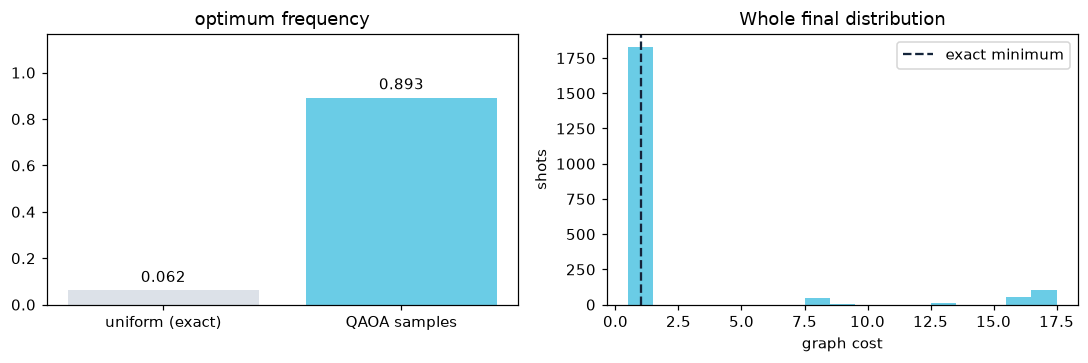

In [51]:
# Choose the metric and call show_comparison, then write your interpretation above.
show_comparison(ideal_counts, metric='optimum frequency')
#0.893 p=2
#0.55 p=3


### Zero-shot training (Tudor)
An exact numpy simulator (`qaoa_state`), the p = 1 closed form `E(γ, β)` with the best β in closed form (`train_p1`), INTERP
growth and median transfer from small puzzles for p ≥ 2 (`train_transfer`), and two trainer sockets (`baseline` = 0 shots,
`cobyla` = sampled mean cost, every shot billed).


In [52]:
def qaoa_state(J, angles, E=None):
    """Exact ideal QAOA statevector for the baseline ansatz (numpy, no Qiskit), 16 * 2^N bytes."""
    n, p = len(J), len(angles) // 2
    scale = qaoa_scale(J)
    E = diag_energies(J) if E is None else E
    psi = np.full(2 ** n, 2 ** (-n / 2), dtype=np.complex128)
    for g, b in zip(angles[:p], angles[p:]):
        psi *= np.exp(-1j * (g / scale) * E)               # every RZZ of the layer at once
        c, s = math.cos(b), -1j * math.sin(b)
        for q in range(n):                                 # RX(2b) on qubit q
            v = psi.reshape(-1, 2, 2 ** q)
            a0 = v[:, 0, :].copy()
            v[:, 0, :] = c * a0 + s * v[:, 1, :]
            v[:, 1, :] = s * a0 + c * v[:, 1, :]
    return psi


In [53]:
def p1_terms(J, gamma):
    """T1, T2 with E(gamma, beta) = offset + sin(4b)/2 * T1 - sin^2(2b)/2 * T2 for p = 1.

    gamma here is the physical phase (exp(-i gamma sum J Z Z)), i.e. notebook gamma / scale.
    """
    W, n = _sym(J), len(J)
    g = np.atleast_1d(np.asarray(gamma, float))[:, None]
    T1, T2 = np.zeros(g.shape[0]), np.zeros(g.shape[0])
    for u, v in zip(*np.nonzero(np.triu(J, 1))):
        rest = np.ones(n, bool)
        rest[[u, v]] = False
        Ju, Jv = W[u, rest], W[v, rest]
        Pu, Pv = np.cos(2 * g * Ju).prod(axis=1), np.cos(2 * g * Jv).prod(axis=1)
        Pp, Pm = np.cos(2 * g * (Ju + Jv)).prod(axis=1), np.cos(2 * g * (Ju - Jv)).prod(axis=1)
        T1 += J[u, v] * np.sin(2 * g[:, 0] * J[u, v]) * (Pu + Pv)
        T2 += J[u, v] * (Pp - Pm)
    return T1, T2


def p1_energy(J, offset, gamma_nb, beta):
    T1, T2 = p1_terms(J, np.asarray(gamma_nb, float) / qaoa_scale(J))
    return offset + np.sin(4 * beta) / 2 * T1 - np.sin(2 * beta) ** 2 / 2 * T2


def canonical_beta(beta):
    """Each beta only matters modulo pi/2 (a global bit flip leaves every cost unchanged): map to (-pi/4, pi/4]."""
    return -(np.mod(-np.asarray(beta, float) + np.pi / 4, np.pi / 2) - np.pi / 4)


def train_p1(J, offset, grid=256):
    """Best p = 1 angles (notebook units) from the closed form.

    Returns (angles [gamma, beta], predicted expected cost, classical evaluations). No shots needed.
    """
    from scipy.optimize import minimize_scalar

    scale = qaoa_scale(J)

    def best_beta(gnb):
        T1, T2 = p1_terms(J, np.atleast_1d(gnb) / scale)
        beta = 0.25 * np.arctan2(-2 * T1, -T2)
        return offset - np.sqrt(T1 ** 2 / 4 + T2 ** 2 / 16) - T2 / 4, canonical_beta(beta)

    gs = np.linspace(0, np.pi, grid + 1)[1:]
    vals, _ = best_beta(gs)
    k = int(vals.argmin())
    lo, hi = gs[max(k - 1, 0)], gs[min(k + 1, grid - 1)]
    res = minimize_scalar(lambda x: float(best_beta(x)[0][0]), bounds=(lo, hi), method="bounded")
    g = float(res.x) if res.fun < vals[k] else float(gs[k])
    e, b = best_beta(g)
    return np.array([g, float(b[0])]), float(e[0]), grid + int(res.nfev)


In [54]:
def interp(angles):
    """INTERP initialisation (Zhou et al. 2020): angles for depth p -> starting angles for depth p + 1."""
    p = len(angles) // 2
    out = []
    for x in (np.r_[0.0, angles[:p], 0.0], np.r_[0.0, angles[p:], 0.0]):
        out += [(i - 1) / p * x[i - 1] + (p - i + 1) / p * x[i] for i in range(1, p + 2)]
    return np.array(out)


def train_transfer(p, pre_ns=(8, 10, 12), per_n=3, gen=None, seed=10_000):
    """Angles for p >= 2: train on small instances (exact, COBYLA), take the median, reuse at any N.

    Returns (angles, total classical evaluations spent on pre-training).
    """
    from scipy.optimize import minimize

    found, evals = [], 0
    for n in pre_ns:
        for k in range(per_n):
            inst = make_instance(n, seed=seed + 97 * n + k, **(gen or {}))
            J, off = ising(*pairwise_evidence(inst.reads))
            E = diag_energies(J)
            a, _, e1 = train_p1(J, off)
            evals += e1

            def f(x):
                return float(np.abs(qaoa_state(J, x, E)) ** 2 @ E) + off

            for depth in range(2, p + 1):
                r = minimize(f, interp(a), method="COBYLA", options={"maxiter": 150 * depth})
                evals += r.nfev
                a = np.r_[r.x[:depth], canonical_beta(r.x[depth:])]
            found.append(a)
    return np.median(np.array(found), axis=0), evals


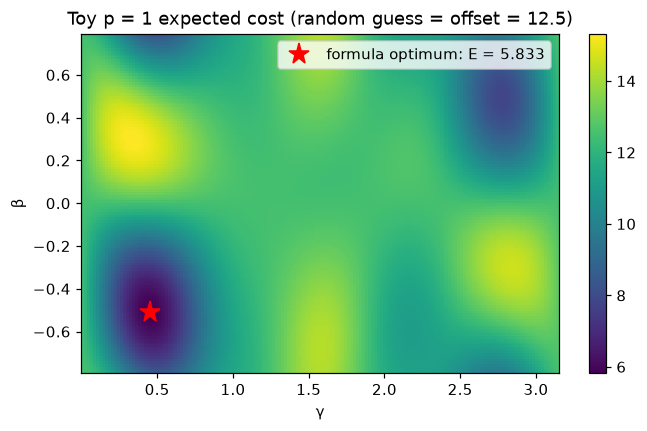

In [55]:
gs = np.linspace(0.01, np.pi, 160)
bs = np.linspace(-np.pi / 4, np.pi / 4, 120)
land = np.array([p1_energy(TOY_J, TOY_OFFSET, gs, b) for b in bs])
(g1, b1), e1, _ = train_p1(TOY_J, TOY_OFFSET)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.pcolormesh(gs, bs, land, cmap="viridis", shading="auto")
ax.plot(g1, b1, "r*", ms=14, label=f"formula optimum: E = {e1:.3f}")
ax.set(xlabel="γ", ylabel="β", title=f"Toy p = 1 expected cost (random guess = offset = {TOY_OFFSET:g})")
fig.colorbar(im, ax=ax)
ax.legend(loc="upper right")
plt.show()


Transfer and concentration (off by default; ~20 s): **saved finding** — transferred p = 2/3 angles keep about 95% of per-puzzle
tuned quality on four unseen 14-SNP puzzles (0.637 vs 0.664 at p = 2; 0.703 vs 0.738 at p = 3).


In [56]:
if RUN_FULL_STUDIES:
    t = time.time()
    transfer = {p: train_transfer(p, gen=REAL)[0] for p in (2, 3)}
    print(f"trained in {time.time() - t:.1f} s")
    kaggle = {2: [0.4638, 0.6379, -0.5934, -0.3042], 3: [0.3872, 0.5905, 0.6692, -0.6394, -0.4468, -0.2430]}
    display(pd.DataFrame([dict(p=p, angles=np.round(a, 4), **{"same as the Kaggle run": np.allclose(a, kaggle[p], atol=1e-3)})
                  for p, a in transfer.items()]))

    rows = []
    for k in range(4):
        inst = make_instance(14, seed=500 + k, **REAL)
        Jk, offk = ising(*pairwise_evidence(inst.reads))
        Ek = diag_energies(Jk)
        gap = -Ek.min()
        quality = lambda e: (offk - e) / gap
        f = lambda x: float(np.abs(qaoa_state(Jk, x, Ek)) ** 2 @ Ek) + offk
        rows.append(dict(puzzle=k, p=1, transferred=np.nan, tuned=quality(train_p1(Jk, offk)[1])))
        for p in (2, 3):
            tuned = minimize(f, transfer[p], method="COBYLA", options={"maxiter": 400}).fun
            rows.append(dict(puzzle=k, p=p, transferred=quality(f(transfer[p])), tuned=quality(tuned)))
    conc = pd.DataFrame(rows)
    display(conc.groupby("p")[["transferred", "tuned"]].mean())
else:
    print('Transfer/concentration skipped (RUN_FULL_STUDIES = False); saved finding above.')


Transfer/concentration skipped (RUN_FULL_STUDIES = False); saved finding above.


In [57]:
@register("trainer", "baseline")
def baseline_trainer(J, offset, p, builder, ctx):
    """Zero shots: p = 1 closed form on this instance; p >= 2 angles pre-trained once on small instances and reused."""
    if builder != "baseline":
        raise ValueError(f"the baseline trainer only fits the baseline circuit, not '{builder}'; use trainer='cobyla'")
    if p == 1:
        angles, e_pred, evals = train_p1(J, offset)
        return angles, 0, dict(train="closed-form", train_evals=evals, e_pred=e_pred)
    key = ("transfer", p)
    if key not in ctx["cache"]:
        ctx["cache"][key], evals = train_transfer(p, gen=ctx["gen"])
        ctx["log"](f"pre-trained p={p} angles on small instances ({evals} classical evaluations): {np.round(ctx['cache'][key], 4)}")
    return ctx["cache"][key], 0, dict(train="transfer", train_evals=0)


@register("trainer", "cobyla")
def cobyla_trainer(J, offset, p, builder, ctx):
    """Any circuit: COBYLA on the sampled mean cost; every evaluation runs the circuit and its shots are counted."""
    from scipy.optimize import minimize

    shots, used = ctx["train_shots"], 0
    if builder == 'baseline':
        start, _, _ = train_p1(J, offset)
        for _ in range(p - 1):
            start = interp(start)
    else:
        start = np.random.default_rng(ctx.get('seed', 0)).uniform(
            0, np.pi, ctx['parameter_count'])

    def f(x):
        nonlocal used
        used += shots
        return float(costs(ctx["sample"](x, shots), J, offset).mean())

    r = minimize(f, start, method="COBYLA", options={"maxiter": ctx["train_iters"] or 30 * p, "rhobeg": 0.1})
    return np.asarray(r.x, float), used, dict(train="cobyla", train_evals=int(r.nfev))


### Warm-start and multi-angle QAOA (Carla, p = 2, original budgets)
**Warm start** (Egger–Mareček–Woerner): biased product state `∏ RY(θ_i)|0⟩` from a relaxed candidate and the matching
RY-conjugated mixer, 100 COBYLA iterations × 5 starts. **Multi-angle** (Herrman et al.): same gates as vanilla, one angle per
RZZ and RX, 500 × 5. *As in Carla's original study, this lesson seeds warm start from an exact minimizer (an oracle seed);
the merged benchmark below seeds it from local search instead.* `train_ansatz` gained an optional `energy_values` argument so
callers can pass their own energy array instead of overwriting the lab's global (default behaviour unchanged).


,method,budget (iter x starts),params,nfev,optimum frequency,mean cost,depth,two-qubit gates,final expectation
0,vanilla p=2,100 x 5,0,446,0.911,2.138,16,18,2.185
1,warm-start p=2,100 x 5,0,500,0.802,3.342,20,18,3.557
2,ma-QAOA p=2,500 x 5,28,2500,0.999,1.021,16,18,1.006


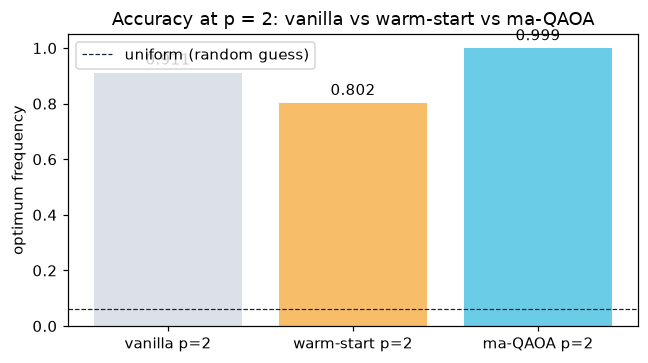

ma-QAOA keeps the same two-qubit-gate count as vanilla p=2; its extra cost is the larger classical optimisation (nfev).


In [58]:
#@title Warm-start QAOA (100x5) and ma-QAOA (500x5) vs vanilla p=2

P2 = 2  # both variants at depth p = 2

# --- shared exact-statevector training (COBYLA, several random restarts) ------
def train_ansatz(ansatz, params, maxiter, n_starts, seed=71, energy_values=None):
    target = energy_array if energy_values is None else np.asarray(energy_values, dtype=float)
    def bind_vals(values):
        return ansatz.assign_parameters(dict(zip(params, values)))
    def energy(values):
        return float(Statevector.from_instruction(bind_vals(values)).probabilities()
                     @ target)
    rng_local = np.random.default_rng(seed)
    starts = [rng_local.uniform(0, np.pi, len(params)) for _ in range(n_starts)]
    trials = [minimize(energy, s, method='COBYLA', options={'maxiter': maxiter})
              for s in starts]
    best = min(trials, key=lambda r: r.fun)
    circ = bind_vals(best.x).copy()
    circ.measure_all()
    return circ, best, int(sum(t.nfev for t in trials))

def counts_of(circ):
    return AerSimulator(max_parallel_threads=1).run(
        circ, shots=LAB_SHOTS, seed_simulator=72).result().get_counts()

# --- warm-start QAOA ----------------------------------------------------------
def warm_start_qaoa(n, J, c, p, eps):
    J = np.asarray(J, dtype=float)
    c = np.clip(c, eps, 1 - eps)
    theta = 2 * np.arcsin(np.sqrt(c))
    scale = float(max(1, np.max(np.abs(J))))
    gam = [Parameter(f'g{k}') for k in range(p)]
    bet = [Parameter(f'b{k}') for k in range(p)]
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(theta[i], i)                       # warm-start state
    for k in range(p):
        for i in range(n):
            for j in range(i + 1, n):
                if J[i, j] != 0:
                    qc.rzz(2 * gam[k] * J[i, j] / scale, i, j)
        for i in range(n):                       # warm-start mixer
            qc.ry(-theta[i], i)
            qc.rz(-2 * bet[k], i)
            qc.ry(theta[i], i)
    return qc, list(gam) + list(bet)

# ma-QAOA: every RZZ and RX gets its own angle (same gates as vanilla) ----------
def make_ma_qaoa(J, p):
    J = np.asarray(J, dtype=float); n = J.shape[0]
    scale = float(max(1, np.max(np.abs(J))))
    active = [(a, b) for a in range(n) for b in range(a + 1, n) if J[a, b] != 0]
    per_layer = len(active) + n
    theta = ParameterVector('ma', p * per_layer)
    qc = QuantumCircuit(n); qc.h(range(n))
    for layer in range(p):
        base = layer * per_layer
        for idx, (a, b) in enumerate(active):
            qc.rzz(2 * theta[base + idx] * J[a, b] / scale, a, b)
        for q in range(n):
            qc.rx(2 * theta[base + len(active) + q], q)
    return qc, list(theta)

# --- vanilla p=2 baseline (100x5), trained the same way for a fair row --------
van_ansatz, van_theta, _ = lab_make_qaoa(LAB_J, P2)
van_circ, van_best, van_nfev = train_ansatz(van_ansatz, list(van_theta), 100, 5)

# --- warm-start p=2 (100 iterations, 5 starts) --------------------------------
# Instance is complement-symmetric, so seed c from one exact minimiser's bits.
c_seed = LAB_STATES[np.isclose(LAB_COSTS, LAB_OPTIMUM)][0].astype(float)
ws_ansatz, ws_params = warm_start_qaoa(N, LAB_J, c_seed, P2, eps=0.25)
ws_circ, ws_best, ws_nfev = train_ansatz(ws_ansatz, ws_params, 100, 5)

# --- ma-QAOA p=2 (500 iterations, 5 starts) -----------------------------------
ma_ansatz, ma_params = make_ma_qaoa(LAB_J, P2)
ma_circ, ma_best, ma_nfev = train_ansatz(ma_ansatz, ma_params, 500, 5)

def two_qubit_gates(qc):
    return sum(it.operation.num_qubits == 2 for it in qc.data)

rows = []
for name, circ, best, nfev, budget in [
        ('vanilla p=2',    van_circ, van_best, van_nfev, '100 x 5'),
        ('warm-start p=2', ws_circ,  ws_best,  ws_nfev,  '100 x 5'),
        ('ma-QAOA p=2',    ma_circ,  ma_best,  ma_nfev,  '500 x 5')]:
    r = sample_summary(name, counts_of(circ), circ.depth())
    r['budget (iter x starts)'] = budget
    r['params'] = circ.num_parameters if name != 'ma-QAOA p=2' else len(ma_params)
    r['nfev'] = nfev
    r['two-qubit gates'] = two_qubit_gates(circ)
    r['final expectation'] = round(float(best.fun), 3)
    rows.append(r)

cmp = pd.DataFrame(rows)[['method', 'budget (iter x starts)', 'params', 'nfev',
                          'optimum frequency', 'mean cost', 'depth',
                          'two-qubit gates', 'final expectation']]
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
display(cmp.round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(cmp['method'], cmp['optimum frequency'], color=[GREY, GOLD, CYAN])
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.axhline(float(np.mean(np.isclose(LAB_COSTS, LAB_OPTIMUM))), color='#14243A', ls='--',
           lw=.8, label='uniform (random guess)')
ax.set_ylim(0, 1.05); ax.set_ylabel('optimum frequency'); ax.legend()
ax.set_title('Accuracy at p = 2: vanilla vs warm-start vs ma-QAOA')
fig.tight_layout(); plt.show()
print('ma-QAOA keeps the same two-qubit-gate count as vanilla p=2; its extra '
      'cost is the larger classical optimisation (nfev).')


**Saved original finding** (Carla, p = 2): optimum frequency vanilla 0.911, warm start 0.802, multi-angle 0.999; all three use
18 two-qubit gates; multi-angle needed 2,500 evaluations (28 parameters) vs 446/500.

### Local frozen training for the merged benchmark (integration)
Standard, warm-start and multi-angle circuits are trained against the same **selected native** cost. `local_frozen_fit` fits the
circuit's active parameters (arbitrary counts, not forced to 2p) and returns the full angle vector, with unused cost angles at
zero when pruning removed every coupling. Default budget = the previous merged smoke run (p = 1, one COBYLA start, 60
evaluations); `RUN_FULL_STUDIES` switches to Carla's original iteration × start budgets. Convergence is reported, not assumed.


In [59]:
def local_frozen_fit(circuit, params, energy, maxiter=60, seed=71, n_starts=1):
    if len(set(params)) != len(params) or not set(circuit.parameters).issubset(params):
        raise ValueError('Circuit parameters and ordered parameter list disagree.')
    if len(energy) != 2 ** circuit.num_qubits:
        raise ValueError('Energy array must be in Qiskit basis-index order.')
    energy = np.asarray(energy, dtype=float)
    active_indices = [i for i, param in enumerate(params) if param in circuit.parameters]
    active_params = [params[i] for i in active_indices]
    if not active_params:
        expected = float(Statevector.from_instruction(circuit).probabilities() @ energy)
        result = OptimizeResult(x=np.zeros(len(params)), fun=expected, nfev=1,
                                success=True, message='No active circuit parameters.')
        return circuit.copy(), result, 1
    measured, result, nfev = train_ansatz(
        circuit, active_params, maxiter=maxiter, n_starts=n_starts, seed=seed, energy_values=energy)
    full_angles = np.zeros(len(params))
    full_angles[active_indices] = result.x
    result.x = full_angles
    frozen = measured.remove_final_measurements(inplace=False)
    if frozen.num_parameters:
        raise ValueError('Training did not freeze every circuit parameter.')
    return frozen, result, nfev


In [60]:
standard, standard_params, _ = make_qaoa(J_NATIVE, P)
warm, warm_params = warm_start_qaoa(N, J_NATIVE, LOCAL_SEED, P, eps=0.25)
multi, multi_params = make_ma_qaoa(J_NATIVE, P)
TEMPLATES = {'standard': (standard, list(standard_params)),
             'warm-start': (warm, warm_params), 'multi-angle': (multi, multi_params)}
FROZEN, ANGLES, TRAINING_ROWS = {}, {}, []
for name, (circuit, params) in TEMPLATES.items():
    maxiter, starts = TRAINING_BUDGET[name]
    frozen, result, evaluations = local_frozen_fit(circuit, params, NATIVE, maxiter, seed=71, n_starts=starts)
    assert len(result.x) == len(params) and circuit.num_parameters <= len(params)
    assert frozen.num_parameters == 0
    FROZEN[name], ANGLES[name] = frozen, np.asarray(result.x)
    TRAINING_ROWS.append(dict(method=name, parameters=len(params), budget=f'{maxiter} x {starts}', nfev=evaluations,
        local_expected_native=float(result.fun), converged=bool(result.success),
        optimizer_message=str(result.message), frozen_angles=np.round(result.x, 6).tolist()))
display(pd.DataFrame(TRAINING_ROWS))


,method,parameters,budget,nfev,local_expected_native,converged,optimizer_message,frozen_angles
0,standard,2,60 x 1,34,5.281,True,Return from COBYLA because the trust region ra...,"[2.45261, 3.534321]"
1,warm-start,2,60 x 1,33,1.971,True,Return from COBYLA because the trust region ra...,"[0.382942, 0.444026]"
2,multi-angle,9,60 x 1,60,2.140,False,Return from COBYLA because the objective funct...,"[1.961781, 0.74207, 2.531579, 1.757296, 0.6607..."


# 7. Ideal and noisy execution

Simulator sockets (Tudor): exact numpy (baseline circuit only), Aer statevector and Aer MPS (`mps_swap_right`; beyond 63 qubits
only unroll to Aer-native gates). Alex's shared hardware setup reuses **frozen** standard-QAOA angles, measures every SNP into
its own classical bit (layout permutations cannot reorder SNPs), counts compiled resources, and scores raw counts.
FakeManilaV2 + Aer is an approximate historical noise snapshot, never a QPU result.


In [61]:
@register("backend", "numpy")
def numpy_backend(job, shots, seed):
    """Exact ideal simulation of the baseline ansatz; also returns per-state probabilities."""
    if job["builder"] != "baseline":
        raise ValueError("numpy backend simulates the baseline ansatz only; use aer_sv or aer_mps.")
    probs = np.abs(qaoa_state(job["J"], job["angles"], job.get("E"))) ** 2
    probs /= probs.sum()
    k = np.random.default_rng(seed).choice(len(probs), size=shots, p=probs)
    return bits(k, len(job["J"])), probs


AER_OPTIONS = {"matrix_product_state": {"mps_swap_direction": "mps_swap_right"}}
AER_BASIS = ["h", "x", "sx", "rx", "ry", "rz", "u", "cx", "cz", "rzz", "rxx", "ryy", "measure"]


def _aer(method):
    def run(job, shots, seed):
        from qiskit import transpile
        from qiskit_aer import AerSimulator

        qc = job["circuit"].copy()
        qc.measure_all()
        n = job["circuit"].num_qubits
        sim = AerSimulator(method=method, **AER_OPTIONS.get(method, {}))
        # the simulator's target stops at 63 qubits; beyond that only unroll to gates Aer runs natively
        tc = transpile(qc, sim) if n <= sim.target.num_qubits else transpile(qc, basis_gates=AER_BASIS, optimization_level=0)
        counts = sim.run(tc, shots=shots, seed_simulator=seed).result().get_counts()
        return np.array([decode_key(k, n) for k, c in counts.items() for _ in range(c)]), None
    run.__doc__ = f"Qiskit Aer, method={method}; works with any registered QAOA builder."
    return run


REGISTRY["backend"]["aer_sv"] = _aer("statevector")
REGISTRY["backend"]["aer_mps"] = _aer("matrix_product_state")


In [62]:
@register("postprocess", "none")
def no_postprocess(samples, J, offset):
    return samples, 0


### Alex's shared hardware setup
Pilot defaults: the team's toy reads and locally reproduced p = 1 angles (frozen, never retrained). `configure_problem` accepts
the shared reads, weighted/pruned evidence `(A, D)` and frozen angles; a backend must have enough qubits. No training or
remote jobs occur during configuration.


In [63]:
HW_PILOT_READS = np.array([
    [0, 1, 1, -1, -1], [1, 0, 0, -1, -1], [-1, 1, 1, 0, -1],
    [-1, 0, 0, 1, -1], [-1, -1, 1, 0, 1], [-1, -1, 0, 1, 0],
    [0, -1, -1, 0, 1], [1, -1, -1, 1, 0], [0, 0, -1, -1, -1],
])
HW_PILOT_GAMMAS = [2.7773446205747447]
HW_PILOT_BETAS = [2.0658685280892244]
assert np.array_equal(HW_PILOT_READS, TOY_READS)
reads, gammas, betas = HW_PILOT_READS.copy(), list(HW_PILOT_GAMMAS), list(HW_PILOT_BETAS)
backend = HARDWARE_BACKEND
shots = 2048
compile_seeds = list(range(20))
noise_seeds = compile_seeds[:3]
noise_repeats = 3


In [64]:
def configure_problem(new_reads, new_gammas, new_betas, backend_override=None, evidence=None):
    """Reuse frozen standard-QAOA angles on a shared input; never train or submit jobs."""
    global reads, gammas, betas, backend, n, agree, disagree, couplings, edges, scale, optimum
    data = np.asarray(new_reads)
    selected_backend = backend if backend_override is None else backend_override
    if data.ndim != 2 or not np.isin(data, [-1, 0, 1]).all():
        raise ValueError('Reads must contain only -1, 0 and 1.')
    size = data.shape[1]
    if size < 1 or size > selected_backend.num_qubits:
        raise ValueError('Choose a backend with enough qubits for these reads.')
    gamma, beta = list(new_gammas), list(new_betas)
    if not gamma or len(gamma) != len(beta) or not np.isfinite(gamma + beta).all():
        raise ValueError('Provide one finite gamma and beta per layer.')
    a = np.zeros((size, size), dtype=float)
    d = np.zeros_like(a)
    if evidence is None:
        for read in data:
            for i, j in itertools.combinations(np.flatnonzero(read >= 0), 2):
                (a if read[i] == read[j] else d)[i, j] += 1
    else:
        a, d = (np.asarray(matrix, dtype=float) for matrix in evidence)
        if (a.shape != (size, size) or d.shape != a.shape
                or not np.isfinite(a).all() or not np.isfinite(d).all()
                or (a < 0).any() or (d < 0).any()
                or not np.array_equal(a, np.triu(a, 1))
                or not np.array_equal(d, np.triu(d, 1))):
            raise ValueError('Evidence must be finite nonnegative upper-triangular A, D.')
    reads, gammas, betas, backend, n = data.copy(), gamma, beta, selected_backend, size
    agree, disagree = a.copy(), d.copy()
    couplings = (disagree - agree) / 2
    edges = [(i, j) for i, j in itertools.combinations(range(n), 2) if couplings[i, j] != 0]
    scale = max(1., float(np.abs(couplings).max()))
    optimum = min(cost(bits) for bits in itertools.product([0, 1], repeat=n)) if n <= 12 else None


In [65]:
def cost(bits):
    return sum(agree[i, j] if bits[i] != bits[j] else disagree[i, j]
               for i, j in itertools.combinations(range(n), 2))

configure_problem(reads, gammas, betas)
print(f'{n} SNPs, {len(edges)} active interactions, backend: {backend.name}')
print('Exact minimum:', optimum if optimum is not None else 'not computed')


5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1.0


In [66]:
def make_circuit(order=None, gate_order='original'):
    order = tuple(range(n)) if order is None else tuple(order)
    if len(order) != n or set(order) != set(range(n)):
        raise ValueError('Order must contain every SNP exactly once.')
    if gate_order not in ('original', 'reverse', 'magnitude'):
        raise ValueError('Unknown gate ordering.')
    wire = {snp: position for position, snp in enumerate(order)}
    ordered_edges = list(edges)
    if gate_order == 'reverse':
        ordered_edges.reverse()
    elif gate_order == 'magnitude':
        ordered_edges.sort(key=lambda edge: -abs(couplings[edge]))

    circuit = QuantumCircuit(n, n)
    circuit.h(range(n))
    for gamma, beta in zip(gammas, betas):
        for i, j in ordered_edges:
            circuit.rzz(2 * gamma * couplings[i, j] / scale, wire[i], wire[j])
        circuit.rx(2 * beta, range(n))
    for snp in range(n):
        circuit.measure(wire[snp], snp)
    return circuit


In [67]:
def resources(circuit):
    return {
        '2q gates': sum(item.operation.num_qubits == 2
                        and item.operation.name != 'barrier' for item in circuit.data),
        '2q depth': circuit.depth(lambda item: item.operation.num_qubits == 2
                                 and item.operation.name != 'barrier'),
        'depth': circuit.depth(),
    }


def score(counts):
    total = sum(counts.values())
    values = [(cost([int(bit) for bit in key.replace(' ', '')[::-1]]), count)
              for key, count in counts.items()]
    return {
        'mean cost': sum(value * count for value, count in values) / total,
        'optimum frequency': (sum(count for value, count in values if np.isclose(value, optimum, rtol=0, atol=1e-9)) / total
                              if optimum is not None else np.nan),
    }

def boxplot_legend(fig):
    from matplotlib.lines import Line2D
    fig.legend(handles=[
        Line2D([0], [0], color='C1', label='Median'),
        Line2D([0], [0], color='green', marker='^', linestyle='None', label='Mean'),
    ], loc='upper center', bbox_to_anchor=(0.5, 0.94), ncol=2, frameon=False)


In [68]:
def logical_probabilities(measured):
    mapping = [(measured.find_bit(item.qubits[0]).index,
                measured.find_bit(item.clbits[0]).index)
               for item in measured.data if item.operation.name == 'measure']
    probabilities = Statevector.from_instruction(
        measured.remove_final_measurements(inplace=False)).probabilities()
    result = np.zeros(2 ** n)
    for physical_state, probability in enumerate(probabilities):
        logical_state = sum(((physical_state >> q) & 1) << c for q, c in mapping)
        result[logical_state] += probability
    return result

if n <= 12:
    ideal = logical_probabilities(make_circuit())
    assert np.allclose(ideal, logical_probabilities(make_circuit(tuple(reversed(range(n))))))
    print('The reversed SNP order keeps the same ideal output distribution.')
else:
    ideal = None
    print('Exact statevector check skipped for this input size.')


The reversed SNP order keeps the same ideal output distribution.


### The lab's fixed p = 2 circuit under snapshot or IBM-calibrated noise (Carla's lab, Alex's main update)
`ORIGINAL_NOISE_SOURCE = 'fake_snapshot'` (default; uses `HARDWARE_BACKEND`) or `'ibm_noise'` (needs `RUN_IBM_NOISE_SIM`;
fetches calibration data and simulates **locally**). Both reuse the same trained angles; no QPU job is submitted.


,circuit,depth,two-qubit gates
0,logical,16,18
1,fake_manila,93,59


,method,selected candidate,best cost,mean cost,optimum frequency,shots,depth
0,ideal,10010,1,2.434,0.893,2048,16
1,FakeManila snapshot noise (local Aer),10010,1,7.875,0.409,2048,93


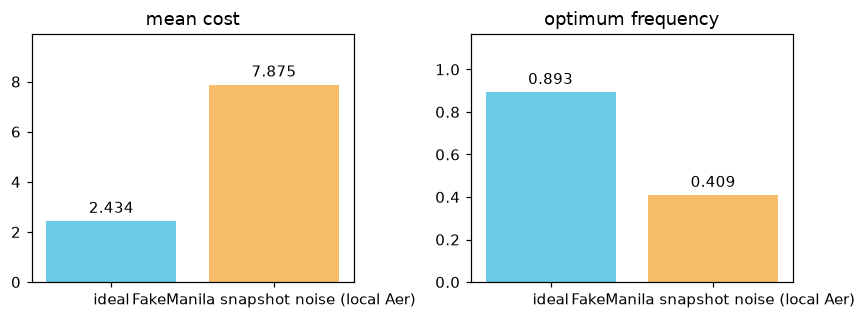

Local Aer noise simulation only; no QPU job submitted. Shots in each distribution: 2048


In [69]:
#@title Original 5-SNP circuit · local simulation with selected backend noise
ORIGINAL_NOISE_SOURCE = 'fake_snapshot'  # change to 'ibm_noise' for IBM calibration data
if ORIGINAL_NOISE_SOURCE == 'ibm_noise':
    lab_backend = get_ibm_service().backend(IBM_BACKEND_NAME)
    if N > lab_backend.num_qubits:
        raise ValueError(f'The original circuit has {N} qubits but {lab_backend.name} has {lab_backend.num_qubits}.')
    noise_simulator = AerSimulator.from_backend(
        lab_backend, method='matrix_product_state', max_parallel_threads=1)
    noise_label = f'{lab_backend.name} calibration noise (local Aer)'
elif ORIGINAL_NOISE_SOURCE == 'fake_snapshot':
    lab_backend = HARDWARE_BACKEND
    if N > lab_backend.num_qubits:
        raise ValueError(f'The lab circuit has {N} qubits but {lab_backend.name} has {lab_backend.num_qubits}.')
    noise_simulator = AerSimulator.from_backend(
        lab_backend, method='matrix_product_state', max_parallel_threads=1)
    noise_label = 'FakeManila snapshot noise (local Aer)'
else:
    raise ValueError("ORIGINAL_NOISE_SOURCE must be 'ibm_noise' or 'fake_snapshot'.")
isa=generate_preset_pass_manager(backend=lab_backend,optimization_level=2,seed_transpiler=71).run(lab_measured)
def lab_resources(qc):
    return {'depth':qc.depth(), 'two-qubit gates':sum(item.operation.num_qubits==2 for item in qc.data)}
display(pd.DataFrame([{'circuit':'logical',**lab_resources(lab_measured)},
                      {'circuit':lab_backend.name,**lab_resources(isa)}]))
noisy_counts=noise_simulator.run(isa,shots=LAB_SHOTS,seed_simulator=73).result().get_counts()
assert sum(noisy_counts.values())==LAB_SHOTS
noise_rows=[sample_summary('ideal',ideal_counts,lab_measured.depth()),
            sample_summary(noise_label,noisy_counts,isa.depth())]
display(pd.DataFrame(noise_rows).round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,metric in zip(axes,['mean cost','optimum frequency']):
    values=[row[metric] for row in noise_rows]
    bars=ax.bar(['ideal',noise_label],values,color=[CYAN,GOLD]);ax.bar_label(bars,fmt='%.3f',padding=3)
    ax.set_title(metric);ax.set_ylim(0,max(values)*1.25+.05)
fig.tight_layout();plt.show()
print('Local Aer noise simulation only; no QPU job submitted. Shots in each distribution:',LAB_SHOTS)


**Saved original finding** (FakeManila default simulator, before Alex's MPS update): ideal optimum frequency 0.893 and mean cost
2.434 vs snapshot noise 0.423 and 7.644; depth 16 → 93 and two-qubit gates 18 → 59 after compilation.

### Merged benchmark: frozen replay, ideal and noisy (integration)
The same reads, selected graph and frozen angles are used in both modes. Raw samples are decoded in logical SNP order and
rescored on the full pairwise and full-read MEC references. No readout mitigation is applied to these raw samples.


In [70]:
if N > HARDWARE_BACKEND.num_qubits:
    raise ValueError(f'{N} SNPs need at least {N} qubits; {HARDWARE_BACKEND.name} has {HARDWARE_BACKEND.num_qubits}. '
                     'Choose a larger fake backend in Setup.')
configure_problem(READS, ANGLES['standard'][:P], ANGLES['standard'][P:], backend_override=HARDWARE_BACKEND,
                  evidence=(PRUNED_A, PRUNED_D))
print(f'{n} SNPs, {len(edges)} active interactions, backend: {backend.name}')
print('Selected native optimum:', optimum)
measured_standard = make_circuit()
assert np.allclose(logical_probabilities(measured_standard),
                   Statevector.from_instruction(FROZEN['standard']).probabilities())
assert np.allclose(logical_probabilities(make_circuit(tuple(reversed(range(N))))),
                   logical_probabilities(measured_standard))
noisy_sim = AerSimulator(noise_model=NoiseModel.from_backend(backend), max_parallel_threads=1)
ideal_sim = AerSimulator(max_parallel_threads=1)


def samples_from_counts(counts, n):
    return np.asarray([decode_key(key, n) for key, count in counts.items() for _ in range(count)], dtype=np.int8)


def summarize_samples(method, mode, samples, **extra):
    full = pairwise_scores(samples, FULL_A, FULL_D)
    mec = mec_scores(samples, READS)
    native = costs(samples, J_NATIVE, OFFSET_NATIVE)
    return dict(method=method, mode=mode, samples=len(samples), native_mean=float(native.mean()),
        full_mean=float(full.mean()), full_optimum_rate=float(np.isclose(full, FULL_OPT).mean()),
        mec_mean=float(mec.mean()), mec_optimum_rate=float(np.isclose(mec, MEC_OPT).mean()), **extra)


BENCH_ROWS = [summarize_samples('greedy local search', 'local classical', LOCAL_X,
                                work_per_restart=float(LOCAL_USED.mean()))]
RAW_COUNTS = {}
for name, frozen in FROZEN.items():
    measured_frozen = frozen.copy()
    measured_frozen.measure_all()
    for mode, simulator in [('ideal simulator', ideal_sim), ('noisy simulator (not QPU)', noisy_sim)]:
        compiled = (transpile(measured_frozen, backend, optimization_level=1, seed_transpiler=7)
                    if mode.startswith('noisy') else transpile(measured_frozen, simulator))
        counts = simulator.run(compiled, shots=SHOTS, seed_simulator=72).result().get_counts()
        RAW_COUNTS[(name, mode)] = counts
        samples = samples_from_counts(counts, N)
        assert samples.shape == (SHOTS, N)
        direct_mean = sum(pairwise_scores(decode_key(key, N)[None, :], FULL_A, FULL_D)[0] * count
                          for key, count in counts.items()) / SHOTS
        assert np.isclose(direct_mean, pairwise_scores(samples, FULL_A, FULL_D).mean())
        BENCH_ROWS.append(summarize_samples(name, mode, samples, **resources(compiled)))
display(pd.DataFrame(BENCH_ROWS).round(4))
print('Raw noisy count example:', next(c for (m, mode), c in RAW_COUNTS.items() if mode.startswith('noisy')))
print('Real QPU execution: NOT EXECUTED; no credentials or jobs used.')


5 SNPs, 4 active interactions, backend: fake_manila
Selected native optimum: 0.0


,method,mode,samples,native_mean,full_mean,full_optimum_rate,mec_mean,mec_optimum_rate,work_per_restart,2q gates,2q depth,depth
0,greedy local search,local classical,16,0.000,1.000,1.000,1.000,1.000,127.25,NaN,NaN,NaN
1,standard,ideal simulator,512,5.488,11.387,0.057,5.856,0.057,NaN,4.0,4.0,7.0
2,standard,noisy simulator (not QPU),512,5.641,11.479,0.065,5.928,0.065,NaN,11.0,11.0,29.0
3,warm-start,ideal simulator,512,1.824,5.049,0.576,2.889,0.576,NaN,4.0,4.0,9.0
4,warm-start,noisy simulator (not QPU),512,3.070,6.779,0.441,3.740,0.441,NaN,11.0,11.0,30.0
5,multi-angle,ideal simulator,512,2.176,5.594,0.467,3.273,0.467,NaN,4.0,4.0,7.0
6,multi-angle,noisy simulator (not QPU),512,3.430,7.213,0.361,4.037,0.361,NaN,11.0,11.0,29.0


Raw noisy count example: {'10011': 28, '10010': 21, '01100': 33, '01010': 23, '10000': 43, '01110': 24, '01101': 12, '10111': 43, '01011': 15, '10101': 15, '11111': 6, '01000': 41, '00011': 6, '00101': 7, '11110': 10, '01001': 21, '11000': 18, '01111': 38, '10001': 14, '00111': 19, '00110': 7, '00000': 16, '10110': 12, '10100': 7, '11001': 13, '00100': 3, '00001': 6, '11010': 2, '11100': 1, '11011': 2, '00010': 4, '11101': 2}
Real QPU execution: NOT EXECUTED; no credentials or jobs used.


### Optional real IBM submission (off; Carla's lab cell with Alex's credential helper)
Set `RUN_REAL_QPU = True` only to submit **one** job with the lab's frozen circuit. Save the printed job record before waiting;
on reconnect use `service.job(saved_job_id)` instead of resubmitting. Compare only with the same reads, objective and angles.


In [71]:
#@title Optional real IBM submission
real_counts=None
if RUN_REAL_QPU:
    from qiskit_ibm_runtime import SamplerV2
    real_backend=get_ibm_service().backend(IBM_BACKEND_NAME)
    real_isa=generate_preset_pass_manager(backend=real_backend,optimization_level=2,seed_transpiler=71).run(lab_measured)
    job=SamplerV2(mode=real_backend).run([real_isa],shots=LAB_SHOTS)
    job_record={'backend':real_backend.name,'shots':LAB_SHOTS,'job_id':job.job_id(),
                'parameters':trained.x.tolist(),'reads':READS.tolist(),
                'objective':'pairwise unweighted','p':LAB_P,'transpiler_seed':71,'optimization_level':2}
    print(job_record,flush=True)  # save this before waiting; inspect platform if submission status is uncertain
    real_counts=job.result()[0].data.meas.get_counts()
else:
    print('Real IBM hardware run skipped; no QPU job submitted.')
hardware_rows=[dict(noise_rows[0],method='ideal simulation'),dict(noise_rows[1])]
if real_counts is not None:
    hardware_rows.append(sample_summary('real IBM hardware',real_counts,real_isa.depth()))
display(pd.DataFrame(hardware_rows)[
    ['method','mean cost','optimum frequency','depth','shots']].round(3))


Real IBM hardware run skipped; no QPU job submitted.


,method,mean cost,optimum frequency,depth,shots
0,ideal simulation,2.434,0.893,16,2048
1,FakeManila snapshot noise (local Aer),7.875,0.409,93,2048


# 8. Hardware experiment methods (Alex)

Eleven compilation and mitigation studies on FakeManilaV2 + Aer, each wrapped in a function so its temporaries stay local.
They are **off by default** (`RUN_HARDWARE_STUDIES`); the saved pilot findings below are from Alex's notebooks. Lower mean cost
and higher optimum frequency are better. Readout/TREX/M3/ZNE estimate a **mean cost**; they do not create corrected
bitstrings or a corrected optimum frequency. `HW_STUDY_INPUT = 'merged'` applies the same methods to the merged frozen circuit.


In [72]:
HW_STUDY_INPUT = 'pilot'   # 'pilot' = Alex's saved setting; 'merged' = shared reads, selected graph, frozen standard angles
if HW_STUDY_INPUT == 'pilot':
    configure_problem(HW_PILOT_READS, HW_PILOT_GAMMAS, HW_PILOT_BETAS, backend_override=HARDWARE_BACKEND)
elif HW_STUDY_INPUT == 'merged':
    configure_problem(READS, ANGLES['standard'][:P], ANGLES['standard'][P:], backend_override=HARDWARE_BACKEND,
                      evidence=(PRUNED_A, PRUNED_D))
else:
    raise ValueError("HW_STUDY_INPUT must be 'pilot' or 'merged'.")
ideal = logical_probabilities(make_circuit()) if n <= 12 else None
print(f'{n} SNPs, {len(edges)} active interactions, backend: {backend.name}; exact minimum: {optimum}')


5 SNPs, 9 active interactions, backend: fake_manila; exact minimum: 1.0


### 8.1 SNP ordering and layout

**Saved pilot finding:** The selected order kept the median two-qubit count at 28 and lowered two-qubit depth 23 → 21; no clear noisy gain.


In [73]:
def placement_study():
    'SNP ordering and layout (Alex, docs/hardware_experiments/hardware_placement.ipynb).'
    physical = list(range(n))
    discovery_seeds = [1001, 1002]
    assert not set(discovery_seeds) & set(compile_seeds)
    rng = np.random.default_rng(17)
    candidates = [tuple(range(n))]
    for _ in range(100):
        proposal = tuple(int(i) for i in rng.permutation(n))
        if proposal not in candidates:
            candidates.append(proposal)
        if len(candidates) == 8:
            break
    print('Candidate orders:', candidates)
    print('Discovery compilations:', len(candidates) * len(discovery_seeds))

    discovery_rows = []
    for candidate in candidates:
        for seed in discovery_seeds:
            manager = generate_preset_pass_manager(
                backend=backend, optimization_level=2, initial_layout=physical,
                routing_method='sabre', seed_transpiler=seed,
            )
            compiled_candidate = manager.run(make_circuit(candidate))
            discovery_rows.append({'order': candidate, 'seed': seed, **resources(compiled_candidate)})
    discovery = pd.DataFrame(discovery_rows)
    ranking = discovery.groupby('order', sort=False)[['2q gates', '2q depth']].median()
    ranking = ranking.sort_values(['2q gates', '2q depth'], kind='stable')
    alternatives = [candidate for candidate in ranking.index if candidate != tuple(range(n))]
    order = alternatives[0] if alternatives else tuple(range(n))
    display(ranking)
    print('Selected order:', order)

    circuits = {
        'Automatic': make_circuit(),
        'Original order': make_circuit(),
    }
    if tuple(order) != tuple(range(n)):
        circuits['Selected order'] = make_circuit(order)
    else:
        print('The selected order matches the original; no duplicate arm is added.')
    if ideal is not None:
        for circuit in circuits.values():
            assert np.allclose(logical_probabilities(circuit), ideal)
        print('Ideal distributions agree for all tested circuits.')

    compiled = {}
    rows = []
    for name, circuit in circuits.items():
        layout = None if name == 'Automatic' else physical
        for seed in compile_seeds:
            manager = generate_preset_pass_manager(
                backend=backend, optimization_level=2,
                initial_layout=layout, routing_method='sabre', seed_transpiler=seed,
            )
            compiled[name, seed] = manager.run(circuit)
            rows.append({'method': name, 'seed': seed, **resources(compiled[name, seed])})
    resource_table = pd.DataFrame(rows)
    display(resource_table.groupby('method', sort=False)[['2q gates', '2q depth', 'depth']]
            .agg(['median', 'min', 'max']))

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    for ax, metric in zip(axes, ['2q gates', '2q depth']):
        data = [resource_table.loc[resource_table.method == name, metric] for name in circuits]
        ax.boxplot(data, tick_labels=circuits.keys(), showmeans=True)
        ax.set_title(metric)
        ax.tick_params(axis='x', rotation=15)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Compilation across the same seeds')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    run_noise = True
    if run_noise:
        if backend.num_qubits > 16:
            raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')
        simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
        samples = []
        for name in circuits:
            for seed in noise_seeds:
                for repeat in range(noise_repeats):
                    counts = simulator.run(
                        compiled[name, seed], shots=shots,
                        seed_simulator=9000 + seed * 100 + repeat,
                    ).result().get_counts()
                    samples.append({'method': name, 'seed': seed, 'repeat': repeat, **score(counts)})
        noisy_results = pd.DataFrame(samples)
        display(noisy_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
                .agg(['mean', 'std']))

    if run_noise:
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
        for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
            values = [noisy_results.loc[noisy_results.method == name, metric] for name in circuits]
            ax.boxplot(values, tick_labels=circuits.keys(), showmeans=True)
            ax.set_title(metric)
            ax.tick_params(axis='x', rotation=15)
            ax.grid(axis='y', alpha=.2)
        fig.suptitle('Noisy samples across compiled circuits')
        boxplot_legend(fig)
        fig.tight_layout(rect=(0, 0, 1, 0.86))
        plt.show()


if RUN_HARDWARE_STUDIES:
    placement_study()
else:
    print('SNP ordering and layout: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


SNP ordering and layout: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.2 Calibration-aware physical layout

**Saved pilot finding:** Selected (3, 4, 2, 1, 0): two-qubit count/depth tied automatic layout (27/22), total depth 51 vs 46, error proxy 0.488 vs 0.482; noisy mean cost 9.341 vs 9.425 — no clear advantage.


In [74]:
def display_formatted(frame, formats):
    """pandas Styler needs jinja2; without it, format the columns as text instead."""
    if importlib.util.find_spec('jinja2'):
        display(frame.style.format(formats))
    else:
        display(frame.assign(**{c: frame[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else v)
                                for c, f in formats.items()}))


def calibration_layout_study():
    'Calibration-aware physical layout (Alex, docs/hardware_experiments/hardware_noise_aware_layout.ipynb).'
    physical_qubits = list(range(backend.num_qubits))
    target = backend.target

    calibration_rows = []
    for physical in physical_qubits:
        measure = target['measure'].get((physical,))
        sx = target['sx'].get((physical,)) if 'sx' in target.operation_names else None
        calibration_rows.append({
            'physical qubit': physical,
            'readout error': None if measure is None else measure.error,
            'SX error': None if sx is None else sx.error,
        })
    calibration = pd.DataFrame(calibration_rows)
    display_formatted(calibration, ({'readout error': '{:.3%}', 'SX error': '{:.3%}'}))

    edge_rows = []
    for name in target.operation_names:
        for qubits, properties in target[name].items():
            if qubits is not None and len(qubits) == 2 and properties.error is not None:
                edge_rows.append({
                    'native gate': name,
                    'physical pair': f'{qubits[0]}-{qubits[1]}',
                    'gate error': properties.error,
                })
    native_edges = pd.DataFrame(edge_rows)
    display_formatted(native_edges, ({'gate error': '{:.3%}'}))

    max_candidates = 120
    candidate_limit = min(max_candidates, math.perm(len(physical_qubits), n))
    rng = np.random.default_rng(17)
    candidates = [tuple(range(n))]
    while len(candidates) < candidate_limit:
        proposal = tuple(int(q) for q in rng.choice(physical_qubits, size=n, replace=False))
        if proposal not in candidates:
            candidates.append(proposal)

    print(f'Trying {len(candidates)} candidate layouts on {backend.num_qubits} physical qubits.')
    print('Discovery seeds:', [1001, 1002])

    def error_exposure(circuit):
        """Sum -log(1-error) for native gates and measurements in a compiled circuit."""
        total = 0.0
        unscored = 0
        for item in circuit.data:
            name = item.operation.name
            if name == 'barrier':
                continue
            qubits = tuple(circuit.find_bit(q).index for q in item.qubits)
            properties = target[name].get(qubits) if name in target.operation_names else None
            if properties is None or properties.error is None:
                unscored += 1
                continue
            error = min(max(float(properties.error), 0.0), 1.0 - 1e-12)
            total -= np.log1p(-error)
        return total, unscored


    discovery_rows = []
    for candidate_id, layout in enumerate(candidates):
        for seed in [1001, 1002]:
            manager = generate_preset_pass_manager(
                backend=backend,
                optimization_level=2,
                initial_layout=list(layout),
                routing_method='sabre',
                seed_transpiler=seed,
            )
            compiled_candidate = manager.run(make_circuit())
            exposure, unscored = error_exposure(compiled_candidate)
            discovery_rows.append({
                'candidate': candidate_id,
                'layout': layout,
                'seed': seed,
                'estimated error exposure': exposure,
                'unscored operations': unscored,
                **resources(compiled_candidate),
            })

    discovery = pd.DataFrame(discovery_rows)
    layout_scores = (discovery.groupby(['candidate', 'layout'], as_index=False)
                     .median(numeric_only=True)
                     .sort_values(['estimated error exposure', '2q gates', 'depth']))
    selected_layout = tuple(layout_scores.iloc[0]['layout'])
    print('Selected layout:', selected_layout)
    display_formatted(layout_scores.head(8), ({
        'estimated error exposure': '{:.4f}',
        '2q gates': '{:.0f}',
        '2q depth': '{:.0f}',
        'depth': '{:.0f}',
    }))

    methods = {'Automatic': None, 'Calibration selected': list(selected_layout)}
    compiled = {}
    resource_rows = []

    for method, layout in methods.items():
        for seed in compile_seeds:
            manager = generate_preset_pass_manager(
                backend=backend,
                optimization_level=2,
                initial_layout=layout,
                routing_method='sabre',
                seed_transpiler=seed,
            )
            circuit = manager.run(make_circuit())
            compiled[method, seed] = circuit
            exposure, unscored = error_exposure(circuit)
            resource_rows.append({
                'method': method,
                'seed': seed,
                'estimated error exposure': exposure,
                'unscored operations': unscored,
                **resources(circuit),
            })

    resource_table = pd.DataFrame(resource_rows)
    resource_summary = resource_table.groupby('method')[
        ['estimated error exposure', '2q gates', '2q depth', 'depth']
    ].median().round(3)
    display(resource_summary)

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    for ax, metric in zip(axes, ['2q gates', '2q depth', 'estimated error exposure']):
        data = [resource_table.loc[resource_table.method == name, metric]
                for name in methods]
        ax.boxplot(data, tick_labels=methods.keys(), showmeans=True)
        ax.set_title(metric)
        ax.tick_params(axis='x', rotation=12)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Compilation results on the same evaluation seeds')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, .84))
    plt.show()

    run_noise = True
    if run_noise:
        if backend.num_qubits > 16:
            raise ValueError('Choose a smaller simulator or turn off noisy sampling above 16 qubits.')
        simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
        sample_rows = []
        for method in methods:
            for seed in noise_seeds:
                for repeat in range(noise_repeats):
                    sample_seed = 10000 + seed * noise_repeats + repeat
                    counts = simulator.run(
                        compiled[method, seed], shots=shots, seed_simulator=sample_seed
                    ).result().get_counts()
                    metrics = score(counts)
                    sample_rows.append({
                        'method': method,
                        'seed': seed,
                        'repeat': repeat,
                        **metrics,
                    })
        noisy_results = pd.DataFrame(sample_rows)
        noise_summary = noisy_results.groupby('method')[
            ['mean cost', 'optimum frequency']
        ].median().round(4)
        display(noise_summary)

    if run_noise:
        fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
        for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
            data = [noisy_results.loc[noisy_results.method == name, metric]
                    for name in methods]
            ax.boxplot(data, tick_labels=methods.keys(), showmeans=True)
            ax.set_title(metric)
            ax.tick_params(axis='x', rotation=12)
            ax.grid(axis='y', alpha=.2)
        fig.suptitle('Noisy samples: same shots and paired evaluation seeds')
        boxplot_legend(fig)
        fig.tight_layout(rect=(0, 0, 1, .84))
        plt.show()


if RUN_HARDWARE_STUDIES:
    calibration_layout_study()
else:
    print('Calibration-aware physical layout: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Calibration-aware physical layout: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.3 SABRE vs Lookahead routing

**Saved pilot finding:** Both had median 28 two-qubit gates and two-qubit depth 23; noisy results were close.


In [75]:
def routing_study():
    'SABRE vs Lookahead routing (Alex, docs/hardware_experiments/hardware_routing.ipynb).'
    circuit = make_circuit()
    physical = list(range(n))
    routers = {'SABRE': 'sabre', 'Lookahead': 'lookahead'}
    compiled = {}
    rows = []
    for name, router in routers.items():
        for seed in compile_seeds:
            manager = generate_preset_pass_manager(
                backend=backend, optimization_level=2, initial_layout=physical,
                routing_method=router, seed_transpiler=seed,
            )
            compiled[name, seed] = manager.run(circuit)
            rows.append({'method': name, 'seed': seed, **resources(compiled[name, seed])})
    resource_table = pd.DataFrame(rows)
    display(resource_table.groupby('method', sort=False)[['2q gates', '2q depth', 'depth']]
            .agg(['median', 'min', 'max']))

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, metric in zip(axes, ['2q gates', '2q depth']):
        data = [resource_table.loc[resource_table.method == name, metric] for name in routers]
        ax.boxplot(data, tick_labels=routers.keys(), showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Routing resources across the same seeds')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    run_noise = True
    if run_noise:
        if backend.num_qubits > 16:
            raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')
        simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
        samples = []
        for name in routers:
            for seed in noise_seeds:
                for repeat in range(noise_repeats):
                    counts = simulator.run(
                        compiled[name, seed], shots=shots,
                        seed_simulator=9000 + seed * 100 + repeat,
                    ).result().get_counts()
                    samples.append({'method': name, 'seed': seed, 'repeat': repeat, **score(counts)})
        noisy_results = pd.DataFrame(samples)
        display(noisy_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
                .agg(['mean', 'std']))

    if run_noise:
        fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
        for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
            values = [noisy_results.loc[noisy_results.method == name, metric] for name in routers]
            ax.boxplot(values, tick_labels=routers.keys(), showmeans=True)
            ax.set_title(metric)
            ax.grid(axis='y', alpha=.2)
        fig.suptitle('Noisy samples across compiled circuits')
        boxplot_legend(fig)
        fig.tight_layout(rect=(0, 0, 1, 0.86))
        plt.show()


if RUN_HARDWARE_STUDIES:
    routing_study()
else:
    print('SABRE vs Lookahead routing: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


SABRE vs Lookahead routing: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.4 Ordering the commuting cost gates

**Saved pilot finding:** Original order used fewest two-qubit gates (28); magnitude-first had lower two-qubit depth (20 vs 23); no clear noisy winner.


In [76]:
def gate_order_study():
    'Ordering the commuting cost gates (Alex, docs/hardware_experiments/hardware_gate_order.ipynb).'
    orders = ['original', 'reverse', 'magnitude']
    circuits = {name: make_circuit(gate_order=name) for name in orders}
    if ideal is not None:
        for circuit in circuits.values():
            assert np.allclose(logical_probabilities(circuit), ideal)
        print('Ideal distributions agree for all gate orders.')

    physical = list(range(n))
    compiled = {}
    rows = []
    for name, circuit in circuits.items():
        for seed in compile_seeds:
            manager = generate_preset_pass_manager(
                backend=backend, optimization_level=2, initial_layout=physical,
                routing_method='sabre', seed_transpiler=seed,
            )
            compiled[name, seed] = manager.run(circuit)
            rows.append({'method': name, 'seed': seed, **resources(compiled[name, seed])})
    resource_table = pd.DataFrame(rows)
    display(resource_table.groupby('method', sort=False)[['2q gates', '2q depth', 'depth']]
            .agg(['median', 'min', 'max']))

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    for ax, metric in zip(axes, ['2q gates', '2q depth']):
        data = [resource_table.loc[resource_table.method == name, metric] for name in orders]
        ax.boxplot(data, tick_labels=orders, showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Compiled resources by gate order')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    run_noise = True
    if run_noise:
        if backend.num_qubits > 16:
            raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')
        simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
        samples = []
        for name in orders:
            for seed in noise_seeds:
                for repeat in range(noise_repeats):
                    counts = simulator.run(
                        compiled[name, seed], shots=shots,
                        seed_simulator=9000 + seed * 100 + repeat,
                    ).result().get_counts()
                    samples.append({'method': name, 'seed': seed, 'repeat': repeat, **score(counts)})
        noisy_results = pd.DataFrame(samples)
        display(noisy_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
                .agg(['mean', 'std']))

    if run_noise:
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
        for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
            values = [noisy_results.loc[noisy_results.method == name, metric] for name in orders]
            ax.boxplot(values, tick_labels=orders, showmeans=True)
            ax.set_title(metric)
            ax.grid(axis='y', alpha=.2)
        fig.suptitle('Noisy samples by gate order')
        boxplot_legend(fig)
        fig.tight_layout(rect=(0, 0, 1, 0.86))
        plt.show()


if RUN_HARDWARE_STUDIES:
    gate_order_study()
else:
    print('Ordering the commuting cost gates: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Ordering the commuting cost gates: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.5 Disjoint-pair RZZ rounds before compilation

**Saved pilot finding:** Depth 57 → 52 but two-qubit gates 28 → 36 and duration +8,864 dt; mean cost +0.058, optimum frequency −0.014.


In [77]:
def commuting_schedule_study():
    'Disjoint-pair RZZ rounds before compilation (Alex, docs/hardware_experiments/hardware_commuting_schedule.ipynb).'
    matching_rounds = []
    for edge in edges:
        for one_round in matching_rounds:
            used_snps = {snp for pair in one_round for snp in pair}
            if not used_snps.intersection(edge):
                one_round.append(edge)
                break
        else:
            matching_rounds.append([edge])

    round_edges = [edge for one_round in matching_rounds for edge in one_round]
    assert sorted(round_edges) == sorted(edges)

    round_table = pd.DataFrame([
        {'round': index, 'pairs': ', '.join(f'SNP{i + 1}–SNP{j + 1}' for i, j in one_round)}
        for index, one_round in enumerate(matching_rounds, start=1)
    ])
    display(round_table)

    def make_circuit_with_edges(edge_order):
        circuit = QuantumCircuit(n, n)
        circuit.h(range(n))
        for gamma, beta in zip(gammas, betas):
            for i, j in edge_order:
                angle = 2 * gamma * couplings[i, j] / scale
                circuit.rzz(angle, i, j)
            circuit.rx(2 * beta, range(n))
        for snp in range(n):
            circuit.measure(snp, snp)
        return circuit

    circuits = {
        'Original edge order': make_circuit(),
        'Greedy disjoint rounds': make_circuit_with_edges(round_edges),
    }

    if ideal is not None:
        for circuit in circuits.values():
            assert np.allclose(logical_probabilities(circuit), ideal)
        print('Both orders have the same ideal output probabilities.')
    else:
        print('Exact probability check skipped above 12 SNPs.')

    physical = list(range(n))
    compiled = {}
    resource_rows = []
    for method, circuit in circuits.items():
        for seed in compile_seeds:
            manager = generate_preset_pass_manager(
                backend=backend,
                optimization_level=2,
                initial_layout=physical,
                routing_method='sabre',
                seed_transpiler=seed,
            )
            routed = manager.run(circuit)
            compiled[method, seed] = routed
            scheduled = PassManager([
                ALAPScheduleAnalysis(target=backend.target),
                PadDelay(target=backend.target),
            ]).run(routed)
            resource_rows.append({
                'method': method,
                'seed': seed,
                'duration (dt)': scheduled.estimate_duration(backend.target, unit='dt'),
                **resources(routed),
            })

    resource_table = pd.DataFrame(resource_rows)
    display(resource_table.groupby('method', sort=False)[
        ['2q gates', '2q depth', 'depth', 'duration (dt)']
    ].agg(['median', 'min', 'max']))

    method_order = list(circuits)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    for ax, metric in zip(axes, ['2q gates', 'depth', 'duration (dt)']):
        data = [resource_table.loc[resource_table.method == name, metric]
                for name in method_order]
        ax.boxplot(data, tick_labels=['Original', 'Disjoint rounds'], showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Compiled resources across the same 20 seeds')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    if backend.num_qubits > 16:
        raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')

    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    noisy_rows = []
    for seed in noise_seeds:
        for repeat in range(noise_repeats):
            simulator_seed = 90_000 + seed * 100 + repeat
            for method in method_order:
                counts = simulator.run(
                    compiled[method, seed],
                    shots=shots,
                    seed_simulator=simulator_seed,
                ).result().get_counts()
                noisy_rows.append({
                    'method': method,
                    'seed': seed,
                    'repeat': repeat,
                    'shots': sum(counts.values()),
                    **score(counts),
                })

    noisy_results = pd.DataFrame(noisy_rows)
    display(noisy_results.groupby('method', sort=False)[
        ['shots', 'mean cost', 'optimum frequency']
    ].agg(['mean', 'std']))

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        data = [noisy_results.loc[noisy_results.method == name, metric]
                for name in method_order]
        ax.boxplot(data, tick_labels=['Original', 'Disjoint rounds'], showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy results across matched seeds and repeats')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    summary = noisy_results.groupby('method')[['mean cost', 'optimum frequency']].mean()
    resource_medians = resource_table.groupby('method')[['2q gates', 'depth', 'duration (dt)']].median()
    base_name, round_name = method_order
    print('Median resource change (disjoint rounds − original):')
    for metric in ['2q gates', 'depth', 'duration (dt)']:
        print(f'  {metric}: {resource_medians.loc[round_name, metric] - resource_medians.loc[base_name, metric]:+.0f}')
    print('Mean-cost change (disjoint rounds − original):',
          f"{summary.loc[round_name, 'mean cost'] - summary.loc[base_name, 'mean cost']:+.3f}")
    print('Optimum-frequency change (disjoint rounds − original):',
          f"{summary.loc[round_name, 'optimum frequency'] - summary.loc[base_name, 'optimum frequency']:+.3f}")


if RUN_HARDWARE_STUDIES:
    commuting_schedule_study()
else:
    print('Disjoint-pair RZZ rounds before compilation: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Disjoint-pair RZZ rounds before compilation: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.6 Local readout correction

**Saved pilot finding:** Corrected mean cost was closer to the pre-readout reference (8.854) in all five repeats, also at equal total shots.


In [78]:
def readout_study():
    'Local readout correction (Alex, docs/hardware_experiments/hardware_readout.ipynb).'
    if backend.num_qubits > 16:
        raise ValueError('Choose a smaller simulated backend for this study.')
    manager = generate_preset_pass_manager(
        backend=backend, optimization_level=2, seed_transpiler=71,
    )
    compiled = manager.run(make_circuit())
    measurement_map = {
        compiled.find_bit(item.clbits[0]).index: compiled.find_bit(item.qubits[0]).index
        for item in compiled.data if item.operation.name == 'measure'
    }
    if set(measurement_map) != set(range(n)):
        raise ValueError('Expected one final measurement for each SNP.')
    print('Classical SNP bit → measured physical qubit:', measurement_map)
    print('Compiled resources:', resources(compiled))

    calibrations = []
    for prepared in [0, 1]:
        circuit = QuantumCircuit(backend.num_qubits, n)
        if prepared:
            for qubit in measurement_map.values():
                circuit.x(qubit)
        for bit, qubit in measurement_map.items():
            circuit.measure(qubit, bit)
        calibrations.append(circuit)

    calibration_manager = generate_preset_pass_manager(
        backend=backend, optimization_level=0,
        initial_layout=list(range(backend.num_qubits)), seed_transpiler=71,
    )
    calibrations = [calibration_manager.run(circuit) for circuit in calibrations]
    for circuit in calibrations:
        actual = {circuit.find_bit(item.clbits[0]).index: circuit.find_bit(item.qubits[0]).index
                  for item in circuit.data if item.operation.name == 'measure'}
        assert actual == measurement_map
    print('Both calibrations use the target measurement map.')

    def local_matrices(zero_counts, one_counts):
        response = np.zeros((n, 2, 2))
        for prepared, counts in enumerate([zero_counts, one_counts]):
            total = sum(counts.values())
            for key, count in counts.items():
                for bit, observed in enumerate(key.replace(' ', '')[::-1]):
                    response[bit, int(observed), prepared] += count / total
        if max(np.linalg.cond(response)) > 1e6:
            raise ValueError('Calibration is too unstable to invert.')
        return response


    def corrected_cost(counts, response):
        # Estimate each pair's Z_i Z_j value from the observed bits.
        z = np.array([1., -1.]) @ np.linalg.inv(response)
        total = sum(counts.values())
        estimate = 0.
        for key, count in counts.items():
            bits = [int(bit) for bit in key.replace(' ', '')[::-1]]
            for i, j in itertools.combinations(range(n), 2):
                offset = (agree[i, j] + disagree[i, j]) / 2
                weight = (disagree[i, j] - agree[i, j]) / 2
                estimate += count * (offset + weight * z[i, bits[i]] * z[j, bits[j]])
        return estimate / total

    reference_cost = None
    if backend.num_qubits <= 10:
        before_readout = compiled.remove_final_measurements(inplace=False)
        before_readout.save_probabilities_dict()
        reference_sim = AerSimulator.from_backend(
            backend, method='density_matrix', max_parallel_threads=1,
        )
        probabilities = reference_sim.run(before_readout).result().data(0)['probabilities']
        reference_cost = sum(
            probability * cost([(state >> measurement_map[bit]) & 1 for bit in range(n)])
            for state, probability in probabilities.items()
        )
        print('Exact simulated pre-readout mean cost:', round(reference_cost, 4))
    else:
        print('Exact pre-readout reference skipped: density-matrix simulation grows as 4^n.')

    calibration_shots = 1024
    repeats = 5
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    results = []
    for repeat in range(repeats):
        calibration_result = simulator.run(
            calibrations, shots=calibration_shots, seed_simulator=7000 + repeat,
        ).result()
        response = local_matrices(calibration_result.get_counts(0), calibration_result.get_counts(1))
        target = simulator.run(compiled, shots=shots,
                               seed_simulator=8000 + repeat).result().get_counts()
        equal_shots = shots + 2 * calibration_shots
        raw_equal = simulator.run(compiled, shots=equal_shots,
                                  seed_simulator=9000 + repeat).result().get_counts()
        results.append({'repeat': repeat, 'raw': score(target)['mean cost'],
                        'local corrected': corrected_cost(target, response),
                        'raw equal budget': score(raw_equal)['mean cost']})
    readout_results = pd.DataFrame(results)
    display(readout_results.round(4))
    print('Shots per corrected arm:', equal_shots,
          '| shots per equal-budget raw arm:', equal_shots,
          '| pre-readout reference: density-matrix simulation (no shots)')

    methods = ['raw', 'local corrected', 'raw equal budget']
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for index, name in enumerate(methods):
        axes[0].scatter([index] * repeats, readout_results[name], label=name)
        if reference_cost is not None:
            axes[1].scatter([index] * repeats, abs(readout_results[name] - reference_cost))
    if reference_cost is not None:
        axes[0].axhline(reference_cost, color='black', linestyle='--', label='pre-readout reference')
    else:
        axes[1].text(.5, .5, 'Reference skipped', ha='center', transform=axes[1].transAxes)
    for ax in axes:
        ax.set_xticks(range(len(methods)), methods, rotation=15)
        ax.grid(axis='y', alpha=.2)
    axes[0].set_title('Estimated mean cost')
    axes[1].set_title('Distance from pre-readout reference')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=4, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    plt.show()


if RUN_HARDWARE_STUDIES:
    readout_study()
else:
    print('Local readout correction: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Local readout correction: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.7 TREX-style readout twirling

**Saved pilot finding:** TREX-style 8.889 ± 0.144 and local 8.815 ± 0.184 vs raw 9.318 ± 0.152 (reference 8.854); no TREX advantage.


In [79]:
def trex_study():
    'TREX-style readout twirling (Alex, docs/hardware_experiments/hardware_trex.ipynb).'
    manager = generate_preset_pass_manager(
        backend=backend, optimization_level=2, seed_transpiler=71,
    )
    compiled = manager.run(make_circuit())
    measurement_map = {
        compiled.find_bit(item.clbits[0]).index: compiled.find_bit(item.qubits[0]).index
        for item in compiled.data if item.operation.name == 'measure'
    }
    assert set(measurement_map) == set(range(n))
    print('Classical SNP bit to physical qubit:', measurement_map)
    print('Compiled resources:', resources(compiled))

    reference_cost = None
    if backend.num_qubits <= 10:
        before_readout = compiled.remove_final_measurements(inplace=False)
        before_readout.save_probabilities_dict()
        reference_sim = AerSimulator.from_backend(
            backend, method='density_matrix', max_parallel_threads=1,
        )
        probabilities = reference_sim.run(before_readout).result().data(0)['probabilities']
        reference_cost = sum(
            probability * cost([(state >> measurement_map[bit]) & 1 for bit in range(n)])
            for state, probability in probabilities.items()
        )
        print(f'Exact simulated pre-readout mean cost: {reference_cost:.4f}')
    else:
        print('Skipped exact reference: density-matrix simulation grows quickly.')

    shots_per_arm = 2048
    mask_count = min(16, 2 ** n)
    if shots_per_arm % mask_count:
        raise ValueError('Choose a mask count that divides shots_per_arm.')
    calibration_shots = shots_per_arm // mask_count
    mask_rng = np.random.default_rng(91)
    masks = []
    while len(masks) < mask_count:
        mask = tuple(int(bit) for bit in mask_rng.integers(0, 2, size=n))
        inverse = tuple(1 - bit for bit in mask)
        if mask not in masks and inverse not in masks:
            masks.extend([mask, inverse])

    calibration_circuits = []
    for mask in masks:
        circuit = QuantumCircuit(backend.num_qubits, n)
        for bit, prepared in enumerate(mask):
            if prepared:
                circuit.x(measurement_map[bit])
            circuit.measure(measurement_map[bit], bit)
        calibration_circuits.append(circuit)
    print(f'{mask_count} calibration patterns x {calibration_shots} shots = {shots_per_arm} shots.')

    def twirl_measurements(circuit, mask):
        twirled = QuantumCircuit(circuit.num_qubits, circuit.num_clbits)
        twirled.global_phase = circuit.global_phase
        for item in circuit.data:
            qubits = [circuit.find_bit(q).index for q in item.qubits]
            clbits = [circuit.find_bit(c).index for c in item.clbits]
            if item.operation.name == 'measure':
                bit = clbits[0]
                if mask[bit]:
                    twirled.x(qubits[0])
                twirled.measure(qubits[0], bit)
            else:
                twirled.append(item.operation, qubits, clbits)
        return twirled

    twirled_circuits = [twirl_measurements(compiled, mask) for mask in masks]
    if ideal is not None:
        for mask, circuit in zip(masks, twirled_circuits):
            measured = logical_probabilities(circuit)
            mask_value = sum(bit << index for index, bit in enumerate(mask))
            untwirled = np.array([measured[state ^ mask_value] for state in range(2 ** n)])
            assert np.allclose(untwirled, ideal)
        print('After undoing the X masks, all randomized circuits keep the ideal distribution.')

    def response_from_calibration(calibration_counts):
        response = np.zeros((n, 2, 2))
        for mask, counts in zip(masks, calibration_counts):
            for key, count in counts.items():
                observed = [int(bit) for bit in key.replace(' ', '')[::-1]]
                for bit in range(n):
                    response[bit, observed[bit], mask[bit]] += count
        for bit in range(n):
            for prepared in (0, 1):
                total = response[bit, :, prepared].sum()
                response[bit, :, prepared] /= total
        if max(np.linalg.cond(matrix) for matrix in response) > 1e6:
            raise ValueError('Calibration is too unstable to invert.')
        return response

    def trex_scales(response):
        return np.array([matrix[0, 0] + matrix[1, 1] - 1 for matrix in response])


    def local_corrected_mean(counts, response):
        z = np.array([1., -1.]) @ np.linalg.inv(response)
        total = sum(counts.values())
        estimate = 0.
        for key, count in counts.items():
            bits = [int(bit) for bit in key.replace(' ', '')[::-1]]
            for i, j in itertools.combinations(range(n), 2):
                offset = (agree[i, j] + disagree[i, j]) / 2
                weight = (disagree[i, j] - agree[i, j]) / 2
                estimate += count * (offset + weight * z[i, bits[i]] * z[j, bits[j]])
        return estimate / total


    def trex_corrected_mean(mask_counts, response):
        scales = trex_scales(response)
        if np.min(np.abs(scales)) < 0.1:
            raise ValueError('Readout is too noisy for a stable TREX rescaling.')
        pair_sums = {(i, j): 0 for i, j in itertools.combinations(range(n), 2)}
        total = 0
        for mask, counts in zip(masks, mask_counts):
            for key, count in counts.items():
                observed = [int(bit) for bit in key.replace(' ', '')[::-1]]
                bits = [observed[bit] ^ mask[bit] for bit in range(n)]
                z_values = [1 - 2 * bit for bit in bits]
                for i, j in pair_sums:
                    pair_sums[i, j] += count * z_values[i] * z_values[j]
                total += count
        estimate = 0.
        for (i, j), pair_sum in pair_sums.items():
            offset = (agree[i, j] + disagree[i, j]) / 2
            weight = (disagree[i, j] - agree[i, j]) / 2
            correlation = pair_sum / total / (scales[i] * scales[j])
            estimate += offset + weight * correlation
        return estimate

    repeats = 5
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    rows = []
    for repeat in range(repeats):
        calibration = simulator.run(
            calibration_circuits, shots=calibration_shots,
            seed_simulator=1000 + repeat,
        ).result()
        response = response_from_calibration(
            [calibration.get_counts(index) for index in range(mask_count)]
        )
        raw = simulator.run(
            compiled, shots=shots_per_arm, seed_simulator=2000 + repeat,
        ).result().get_counts()
        twirled = simulator.run(
            twirled_circuits, shots=calibration_shots,
            seed_simulator=3000 + repeat,
        ).result()
        twirled_counts = [twirled.get_counts(index) for index in range(mask_count)]
        raw_equal = simulator.run(
            compiled, shots=2 * shots_per_arm, seed_simulator=4000 + repeat,
        ).result().get_counts()
        rows.extend([
            {'repeat': repeat, 'method': 'raw', 'mean cost': score(raw)['mean cost']},
            {'repeat': repeat, 'method': 'local corrected',
             'mean cost': local_corrected_mean(raw, response)},
            {'repeat': repeat, 'method': 'TREX-style',
             'mean cost': trex_corrected_mean(twirled_counts, response)},
            {'repeat': repeat, 'method': 'raw equal budget',
             'mean cost': score(raw_equal)['mean cost']},
        ])
    results = pd.DataFrame(rows)
    display(results.pivot(index='repeat', columns='method', values='mean cost').round(3))
    display(results.groupby('method')['mean cost'].agg(['mean', 'std']).round(3))
    print('Corrected arms: 4,096 shots each, including calibration.')
    print('Raw equal-budget arm: 4,096 target shots.')

    methods = ['raw', 'local corrected', 'TREX-style', 'raw equal budget']
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for index, method in enumerate(methods):
        values = results.loc[results.method == method, 'mean cost']
        axes[0].scatter([index] * len(values), values, label=method)
        if reference_cost is not None:
            axes[1].scatter([index] * len(values), abs(values - reference_cost))
    if reference_cost is not None:
        axes[0].axhline(reference_cost, color='black', linestyle='--', label='pre-readout reference')
    else:
        axes[1].text(.5, .5, 'Reference skipped', ha='center', transform=axes[1].transAxes)
    axes[0].set_title('Estimated mean cost')
    axes[1].set_title('Distance from pre-readout reference')
    axes[1].set_ylabel('Absolute error')
    for ax in axes:
        ax.set_xticks(range(len(methods)), methods, rotation=15)
        ax.grid(axis='y', alpha=.2)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, .86))
    plt.show()


if RUN_HARDWARE_STUDIES:
    trex_study()
else:
    print('TREX-style readout twirling: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


TREX-style readout twirling: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.8 Matrix-free readout mitigation (M3)

**Saved pilot finding:** M3 and local correction both 8.761 ± 0.111 vs raw 9.381 ± 0.093; M3 did not beat local correction on 5 qubits.


In [80]:
def m3_study():
    'Matrix-free readout mitigation (M3) (Alex, docs/hardware_experiments/hardware_m3_readout.ipynb).'
    try:
        from mthree import M3Mitigation   # optional add-on: pip install mthree
    except ImportError:
        print('M3 skipped: the optional mthree package is not installed.')
        return
    manager = generate_preset_pass_manager(
        backend=backend, optimization_level=2, seed_transpiler=71,
    )
    compiled = manager.run(make_circuit())
    measurement_map = {
        compiled.find_bit(item.clbits[0]).index: compiled.find_bit(item.qubits[0]).index
        for item in compiled.data if item.operation.name == 'measure'
    }
    physical_qubits = [measurement_map[bit] for bit in range(n)]
    assert len(set(physical_qubits)) == n
    print('Classical SNP bit to physical qubit:', measurement_map)
    print('Compiled resources:', resources(compiled))

    reference_cost = None
    if backend.num_qubits <= 10:
        before_readout = compiled.remove_final_measurements(inplace=False)
        before_readout.save_probabilities_dict()
        reference_sim = AerSimulator.from_backend(
            backend, method='density_matrix', max_parallel_threads=1,
        )
        probabilities = reference_sim.run(before_readout).result().data(0)['probabilities']
        reference_cost = sum(
            probability * cost([(state >> measurement_map[bit]) & 1 for bit in range(n)])
            for state, probability in probabilities.items()
        )
        print(f'Exact simulated pre-readout mean cost: {reference_cost:.4f}')
    else:
        print('Skipped exact reference: density-matrix simulation grows quickly.')

    cal_shots_per_state = 205
    mitigator = M3Mitigation(backend)
    calibration_jobs = mitigator.cals_from_system(
        qubits=physical_qubits, shots=cal_shots_per_state,
        method='independent', async_cal=False,
    )
    calibration_shots = sum(
        result.shots for job in calibration_jobs for result in job.result().results
    )
    response = [mitigator.single_qubit_cals[qubit] for qubit in physical_qubits]
    expected_calibration_shots = 2 * n * cal_shots_per_state
    assert calibration_shots == expected_calibration_shots
    print(f'Calibration shots: {calibration_shots} ({2 * n} circuits x {cal_shots_per_state})')

    def local_corrected_mean(counts, matrices):
        z = [np.array([1., -1.]) @ np.linalg.inv(matrix) for matrix in matrices]
        total = sum(counts.values())
        estimate = 0.
        for key, count in counts.items():
            bits = [int(bit) for bit in key.replace(' ', '')[::-1]]
            for i, j in itertools.combinations(range(n), 2):
                offset = (agree[i, j] + disagree[i, j]) / 2
                weight = (disagree[i, j] - agree[i, j]) / 2
                estimate += count * (offset + weight * z[i][bits[i]] * z[j][bits[j]])
        return estimate / total


    def m3_mean_cost(counts, mitigator):
        quasi = mitigator.apply_correction(counts, physical_qubits)
        total_weight = sum(quasi.values())
        estimate = sum(
            weight * cost([int(bit) for bit in key.replace(' ', '')[::-1]])
            for key, weight in quasi.items()
        )
        return estimate / total_weight, quasi

    print('M3 calibration is ready; apply it to the target sample below.')

    target_shots = 2048
    raw_equal_shots = target_shots + calibration_shots
    repeats = 5
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    rows = []
    for repeat in range(repeats):
        raw = simulator.run(
            compiled, shots=target_shots, seed_simulator=5000 + repeat,
        ).result().get_counts()
        raw_equal = simulator.run(
            compiled, shots=raw_equal_shots, seed_simulator=6000 + repeat,
        ).result().get_counts()
        corrected_mean, quasi = m3_mean_cost(raw, mitigator)
        rows.extend([
            {'repeat': repeat, 'method': 'raw', 'mean cost': score(raw)['mean cost']},
            {'repeat': repeat, 'method': 'local corrected',
             'mean cost': local_corrected_mean(raw, response)},
            {'repeat': repeat, 'method': 'M3', 'mean cost': corrected_mean},
            {'repeat': repeat, 'method': 'raw equal budget',
             'mean cost': score(raw_equal)['mean cost']},
        ])
    results = pd.DataFrame(rows)
    display(results.pivot(index='repeat', columns='method', values='mean cost').round(3))
    display(results.groupby('method')['mean cost'].agg(['mean', 'std']).round(3))
    print(f'Corrected arms: {target_shots + calibration_shots} shots each.')
    print(f'Raw equal-budget arm: {raw_equal_shots} target shots.')
    print('M3 returns quasi-probabilities; optimum frequency is not reported.')

    methods = ['raw', 'local corrected', 'M3', 'raw equal budget']
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for index, method in enumerate(methods):
        values = results.loc[results.method == method, 'mean cost']
        axes[0].scatter([index] * len(values), values, label=method)
        if reference_cost is not None:
            axes[1].scatter([index] * len(values), abs(values - reference_cost))
    if reference_cost is not None:
        axes[0].axhline(reference_cost, color='black', linestyle='--', label='pre-readout reference')
    else:
        axes[1].text(.5, .5, 'Reference skipped', ha='center', transform=axes[1].transAxes)
    axes[0].set_title('Estimated mean cost')
    axes[1].set_title('Distance from pre-readout reference')
    axes[1].set_ylabel('Absolute error')
    for ax in axes:
        ax.set_xticks(range(len(methods)), methods, rotation=15)
        ax.grid(axis='y', alpha=.2)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, .86))
    plt.show()


if RUN_HARDWARE_STUDIES:
    m3_study()
else:
    print('Matrix-free readout mitigation (M3): skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Matrix-free readout mitigation (M3): skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.9 X–X dynamical decoupling

**Saved pilot finding:** Same duration and two-qubit count; mean cost 9.666 vs 9.676 and optimum frequency 0.256 vs 0.256 — no clear change.


In [81]:
def dynamical_decoupling_study():
    'X–X dynamical decoupling (Alex, docs/hardware_experiments/hardware_dynamical_decoupling.ipynb).'
    if backend.num_qubits > 12:
        raise ValueError('Choose a smaller simulated backend for this study.')
    manager = generate_preset_pass_manager(backend=backend, optimization_level=2,
                                           seed_transpiler=71)
    compiled = manager.run(make_circuit())
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)

    noise_passes = getattr(simulator.options.noise_model, '_custom_noise_passes', [])
    has_delay_noise = any(
        isinstance(noise_pass, RelaxationNoisePass)
        and Delay in (getattr(noise_pass, '_ops', ()) or ())
        for noise_pass in noise_passes
    )
    if not has_delay_noise:
        raise ValueError('This noise model does not provide a verified delay-relaxation pass.')
    print('Delay relaxation is present in this Aer noise model.')

    target = backend.target
    baseline = PassManager([
        ALAPScheduleAnalysis(target=target), PadDelay(target=target),
    ]).run(compiled)
    with_dd = PassManager([
        ALAPScheduleAnalysis(target=target),
        PadDynamicalDecoupling(dd_sequence=[XGate(), XGate()], target=target),
    ]).run(compiled)

    duration = [circuit.estimate_duration(target, unit='dt') for circuit in [baseline, with_dd]]
    assert duration[0] == duration[1]
    if ideal is not None and compiled.num_qubits <= 12:
        assert np.allclose(logical_probabilities(baseline), ideal)
        assert np.allclose(logical_probabilities(with_dd), ideal)
    summary = pd.DataFrame([
        {'method': name, 'duration (dt)': d, 'X gates': circuit.count_ops().get('x', 0),
         **resources(circuit)}
        for name, circuit, d in zip(['Baseline', 'X–X DD'], [baseline, with_dd], duration)
    ])
    display(summary)

    repeats = 10
    circuits = {'Baseline': baseline, 'X-X DD': with_dd}
    results = []
    for repeat in range(repeats):
        for name, circuit in circuits.items():
            counts = simulator.run(circuit, shots=shots,
                                   seed_simulator=9000 + repeat).result().get_counts()
            results.append({'method': name, 'repeat': repeat, **score(counts)})
    dd_results = pd.DataFrame(results)
    display(dd_results.groupby('method', sort=False)[['mean cost', 'optimum frequency']]
            .agg(['mean', 'std']))
    print('Shots per method:', repeats * shots)

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        data = [dd_results.loc[dd_results.method == name, metric] for name in circuits]
        ax.boxplot(data, tick_labels=circuits.keys(), showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy results with and without X-X pulses')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()


if RUN_HARDWARE_STUDIES:
    dynamical_decoupling_study()
else:
    print('X–X dynamical decoupling: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


X–X dynamical decoupling: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.10 Pauli twirling (equal shots)

**Saved pilot finding:** Mean cost 9.43 → 9.48 and optimum frequency 0.285 → 0.283; median depth 57 → 71 with 31 extra one-qubit gates.


In [82]:
def pauli_twirling_study():
    'Pauli twirling (equal shots) (Alex, docs/hardware_experiments/hardware_pauli_twirling.ipynb).'
    print('Qiskit version:', qiskit.__version__)
    print('Backend:', backend.name)
    print('Shots per comparison:', shots)

    num_randomizations = 16
    if shots % num_randomizations:
        raise ValueError('Choose a shot budget divisible by the randomization count.')
    shots_per_randomization = shots // num_randomizations
    physical = list(range(n))

    circuit = make_circuit()
    compiled = {}
    for seed in compile_seeds:
        manager = generate_preset_pass_manager(
            backend=backend,
            optimization_level=2,
            initial_layout=physical,
            routing_method='sabre',
            seed_transpiler=seed,
        )
        compiled[seed] = manager.run(circuit)

    print(f'{num_randomizations} twirled circuits × {shots_per_randomization} shots '
          f'= {shots} shots per comparison.')

    twirled_for_resources = {}
    resource_rows = []
    for seed, base in compiled.items():
        variants = pauli_twirl_2q_gates(
            base,
            seed=70_000 + seed,
            num_twirls=num_randomizations,
            target=backend.target,
        )
        twirled_for_resources[seed] = variants

        base_resources = resources(base)
        resource_rows.append({
            'method': 'Baseline', 'seed': seed,
            **base_resources, 'added 1q gates': 0,
        })
        base_1q = sum(item.operation.num_qubits == 1 for item in base.data)
        for variant in variants:
            variant_1q = sum(item.operation.num_qubits == 1 for item in variant.data)
            resource_rows.append({
                'method': 'Pauli twirled', 'seed': seed,
                **resources(variant), 'added 1q gates': variant_1q - base_1q,
            })

    if n <= 12:
        baseline_ideal = logical_probabilities(compiled[compile_seeds[0]])
        for variant in twirled_for_resources[compile_seeds[0]]:
            assert np.allclose(logical_probabilities(variant), baseline_ideal)
        print('Ideal probabilities match for all checked twirls.')
    else:
        print('Exact probability check skipped above 12 SNPs.')

    resource_table = pd.DataFrame(resource_rows)
    display(resource_table.groupby('method', sort=False)[
        ['2q gates', '2q depth', 'added 1q gates', 'depth']
    ].agg(['median', 'min', 'max']))

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    for ax, metric in zip(axes, ['2q gates', 'added 1q gates', 'depth']):
        data = [resource_table.loc[resource_table.method == name, metric]
                for name in ['Baseline', 'Pauli twirled']]
        ax.boxplot(data, tick_labels=['Baseline', 'Pauli twirled'], showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Compiled resources across shared transpiler seeds')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    if backend.num_qubits > 16:
        raise ValueError('For a larger backend, turn off noise or choose a smaller simulator.')

    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    noisy_rows = []
    for seed in noise_seeds:
        for repeat in range(noise_repeats):
            base_counts = simulator.run(
                compiled[seed],
                shots=shots,
                seed_simulator=90_000 + seed * 100 + repeat,
            ).result().get_counts()
            noisy_rows.append({
                'method': 'Baseline', 'seed': seed, 'repeat': repeat,
                'shots': shots, **score(base_counts),
            })

            variants = pauli_twirl_2q_gates(
                compiled[seed],
                seed=80_000 + seed * 100 + repeat,
                num_twirls=num_randomizations,
                target=backend.target,
            )
            results = simulator.run(
                variants,
                shots=shots_per_randomization,
                seed_simulator=91_000 + seed * 100 + repeat,
            ).result()
            pooled_counts = {}
            for counts in results.get_counts():
                for bitstring, count in counts.items():
                    pooled_counts[bitstring] = pooled_counts.get(bitstring, 0) + count
            noisy_rows.append({
                'method': 'Pauli twirled', 'seed': seed, 'repeat': repeat,
                'shots': sum(pooled_counts.values()), **score(pooled_counts),
            })

    noisy_results = pd.DataFrame(noisy_rows)
    display(noisy_results.groupby('method', sort=False)[
        ['shots', 'mean cost', 'optimum frequency']
    ].agg(['mean', 'std']))

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, metric in zip(axes, ['mean cost', 'optimum frequency']):
        data = [noisy_results.loc[noisy_results.method == name, metric]
                for name in ['Baseline', 'Pauli twirled']]
        ax.boxplot(data, tick_labels=['Baseline', 'Pauli twirled'], showmeans=True)
        ax.set_title(metric)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Noisy results across matched seeds and repeats')
    boxplot_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

    summary = noisy_results.groupby('method')[['mean cost', 'optimum frequency']].mean()
    cost_change = summary.loc['Pauli twirled', 'mean cost'] - summary.loc['Baseline', 'mean cost']
    frequency_change = (summary.loc['Pauli twirled', 'optimum frequency']
                        - summary.loc['Baseline', 'optimum frequency'])
    print(f'Mean-cost change (twirled − baseline): {cost_change:+.3f}')
    print(f'Optimum-frequency change (twirled − baseline): {frequency_change:+.3f}')
    print('Positive mean-cost change is worse; positive optimum-frequency change is better.')


if RUN_HARDWARE_STUDIES:
    pauli_twirling_study()
else:
    print('Pauli twirling (equal shots): skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Pauli twirling (equal shots): skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


### 8.11 Zero-noise extrapolation of the mean cost

**Saved pilot finding:** Equal-budget mean cost 9.63 raw → 9.15 extrapolated (ideal 7.80); three repeats and two noise factors only.


In [83]:
def zne_study():
    'Zero-noise extrapolation of the mean cost (Alex, docs/hardware_experiments/hardware_zne.ipynb).'
    physical = list(range(n))
    compile_seed = 0
    pass_manager = generate_preset_pass_manager(
        backend=backend,
        optimization_level=2,
        initial_layout=physical,
        routing_method='sabre',
        seed_transpiler=compile_seed,
    )
    compiled = pass_manager.run(make_circuit())

    if compiled.num_qubits > 16:
        raise ValueError('This Aer noise simulation is limited to 16 physical qubits.')

    compiled_ideal = logical_probabilities(compiled)
    assert ideal is None or np.allclose(compiled_ideal, ideal)
    ideal_mean_cost = sum(
        probability * cost([(state >> bit) & 1 for bit in range(n)])
        for state, probability in enumerate(compiled_ideal)
    )
    print(f'Backend: {backend.name}; compiled with seed {compile_seed}')
    print(f'Ideal mean cost: {ideal_mean_cost:.3f}')

    def fold_two_qubit_gates(circuit, factor):
        if factor < 1 or factor % 2 == 0:
            raise ValueError('Use a positive odd noise factor, such as 1 or 3.')

        folded = circuit.copy_empty_like()
        for instruction in circuit.data:
            gate = instruction.operation
            if gate.num_qubits == 2 and gate.name != 'barrier':
                for _ in range((factor - 1) // 2):
                    folded.append(gate, instruction.qubits, instruction.clbits)
                    folded.append(gate.inverse(), instruction.qubits, instruction.clbits)
            folded.append(gate, instruction.qubits, instruction.clbits)
        return folded

    factors = [1, 3]
    folded = {factor: fold_two_qubit_gates(compiled, factor) for factor in factors}

    for factor, circuit in folded.items():
        assert np.allclose(logical_probabilities(circuit), compiled_ideal)

    resource_table = pd.DataFrame([
        {'noise factor': factor, **resources(circuit)}
        for factor, circuit in folded.items()
    ])
    display(resource_table)
    print('The folded circuits have the same ideal output probabilities as the baseline.')

    if shots % len(factors):
        raise ValueError('Choose a total shot budget divisible by the number of noise factors.')

    shots_per_factor = shots // len(factors)
    repeats = noise_repeats
    simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
    records = []

    for repeat in range(repeats):
        raw_counts = simulator.run(
            compiled,
            shots=shots,
            seed_simulator=7000 + repeat,
        ).result().get_counts()
        records.append({
            'repeat': repeat,
            'method': 'Raw baseline',
            'noise factor': 1,
            'shots': shots,
            'mean cost': score(raw_counts)['mean cost'],
        })

        factor_costs = {}
        for factor in factors:
            counts = simulator.run(
                folded[factor],
                shots=shots_per_factor,
                seed_simulator=8000 + 100 * factor + repeat,
            ).result().get_counts()
            mean_cost = score(counts)['mean cost']
            factor_costs[factor] = mean_cost
            records.append({
                'repeat': repeat,
                'method': 'ZNE data',
                'noise factor': factor,
                'shots': shots_per_factor,
                'mean cost': mean_cost,
            })

        zne_cost = (3 * factor_costs[1] - factor_costs[3]) / 2
        records.append({
            'repeat': repeat,
            'method': 'ZNE estimate',
            'noise factor': 0,
            'shots': shots,
            'mean cost': zne_cost,
        })

    results = pd.DataFrame(records)
    summary = (results[results.method.isin(['Raw baseline', 'ZNE estimate'])]
               .groupby('method')['mean cost']
               .agg(['mean', 'std']))
    summary['standard error'] = summary['std'] / np.sqrt(repeats)
    comparison = results[results.method.isin(['Raw baseline', 'ZNE estimate'])]
    display(comparison.pivot(index='repeat', columns='method', values='mean cost'))
    display(summary)
    print(f'Per repeat: raw = {shots} shots; ZNE = {shots_per_factor} + {shots_per_factor} = {shots} shots.')

    zne_data = results[results.method == 'ZNE data']
    factor_summary = zne_data.groupby('noise factor')['mean cost'].agg(['mean', 'std'])

    x = np.array(factor_summary.index, dtype=float)
    y = factor_summary['mean'].to_numpy()
    line = np.polyfit(x, y, 1)
    fit_x = np.linspace(0, 3, 60)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.errorbar(x, y, yerr=factor_summary['std'], fmt='o', capsize=4,
                label='Folded circuit mean cost (mean ± SD)')
    ax.plot(fit_x, np.polyval(line, fit_x), label='Linear extrapolation')
    ax.scatter([0], [np.polyval(line, 0)], marker='D', label='ZNE estimate at factor 0')
    ax.axhline(ideal_mean_cost, color='black', linestyle='--', label='Ideal reference')
    ax.set(xticks=[0, 1, 3], xlabel='Two-qubit gate noise factor', ylabel='Mean cost',
           title='Extrapolating mean cost toward zero noise')
    ax.grid(axis='y', alpha=.25)
    ax.legend(loc='best')
    fig.tight_layout()
    plt.show()

    comparison = results[results.method.isin(['Raw baseline', 'ZNE estimate'])]
    fig, ax = plt.subplots(figsize=(6, 4))
    for position, method in enumerate(['Raw baseline', 'ZNE estimate']):
        values = comparison.loc[comparison.method == method, 'mean cost'].to_numpy()
        ax.scatter(np.full(len(values), position), values, label=method)
        ax.plot([position - .12, position + .12], [values.mean(), values.mean()], color='black')
    ax.axhline(ideal_mean_cost, color='gray', linestyle='--', label='Ideal reference')
    ax.set(xticks=[0, 1], xticklabels=['Raw (2048 shots)', 'ZNE (same budget)'],
           ylabel='Mean cost', title='Raw and extrapolated estimates')
    ax.grid(axis='y', alpha=.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


if RUN_HARDWARE_STUDIES:
    zne_study()
else:
    print('Zero-noise extrapolation of the mean cost: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.')


Zero-noise extrapolation of the mean cost: skipped (RUN_HARDWARE_STUDIES = False); saved pilot finding above.


# 9. Metrics, races and plug-ins (Tudor)

`P_budget` (optimum within B tries), `tts99` (tries for 99% confidence; training shots added), `score` (1 = optimum,
0 = random guess), switch errors (one swapped block counts once; unlinked boundaries skipped). `run_instance`/`run_bench` race
every method on identical puzzles; failures are recorded in a `fail` column instead of stopping the race.


In [84]:
def tts99(p, unit):
    """Expected cost (in `unit`s) to reach the optimum with 99% confidence, given success prob p."""
    if p <= 0:
        return math.inf
    if p >= 0.99:
        return float(unit)
    return unit * math.log(0.01) / math.log(1 - p)


def tts99_runs(hit):
    """Best TTS99 over stopping points b: runs stopped after b evaluations succeed with s(b) = P(hit <= b)."""
    h = np.sort(np.asarray(hit, float))
    best = math.inf
    for k, b in enumerate(h[np.isfinite(h)]):
        best = min(best, tts99((k + 1) / len(h), b))
    return best


def truth_distance(x, truth):
    if truth is None:
        return np.nan
    d = int(np.sum(np.asarray(x) != truth))
    return min(d, len(truth) - d)


def linked_boundaries(A, D):
    """Boundary i sits between SNP i+1 and i+2; it is phased only if some read links SNPs across it."""
    n = len(A)
    a, b = np.nonzero(np.triu(np.asarray(A) + np.asarray(D), 1))
    diff = np.zeros(n + 1, dtype=np.int64)
    np.add.at(diff, a, 1)
    np.add.at(diff, b, -1)
    return np.cumsum(diff)[: n - 1] > 0


def switch_errors(x, truth, linked):
    """Places where x switches between truth and its complement; unlinked boundaries are skipped."""
    if truth is None:
        return np.nan
    h = np.asarray(x, dtype=np.int64) ^ np.asarray(truth, dtype=np.int64)
    return int(np.sum((h[1:] != h[:-1]) & linked))


if not QGD_QUIET:
    truth = np.array([0, 1, 1, 0, 1, 0, 0, 1])
    answer = np.r_[truth[:4], 1 - truth[4:]]        # second half phased the other way round
    print("truth ", truth, "\nanswer", answer)
    print("wrong letters:", truth_distance(answer, truth), "| switch errors:", switch_errors(answer, truth, np.ones(7, bool)))
    print("TTS99 at p = 1% per shot:", round(tts99(0.01, 1)), "shots")


truth  [0 1 1 0 1 0 0 1] 
answer [0 1 1 0 0 1 1 0]
wrong letters: 4 | switch errors: 1
TTS99 at p = 1% per shot: 458 shots


In [85]:
@dataclass
class Config:
    methods: tuple = ("brute", "random", "local", "sa", "qaoa")
    shots: int = 2048            # budget per method: samples (random, QAOA) or evaluations (local, SA)
    runs: int = 64               # independent runs used to estimate success for local search / SA
    ps: tuple = (1,)
    backend: str = "numpy"
    evidence: str = "pairwise"
    qaoa: str = "baseline"
    postprocess: str = "none"
    brute_max: int = 24          # exact enumeration limit for the "brute" row (2^24 costs)
    sv_max: int = 26             # numpy statevector limit (16 * 2^26 B = 1.07 GB)
    seed: int = 0
    trainer: str = "auto"        # auto = "baseline" for the baseline circuit, "cobyla" for any other
    train_shots: int = 256       # shots per training evaluation (shot-based trainers)
    train_iters: int = 0         # optimiser iterations for shot-based trainers; 0 = 30 * p
    gen: dict = field(default_factory=dict)   # make_instance settings; trainers may pre-train on similar puzzles

    def trainer_for(self):
        return self.trainer if self.trainer != "auto" else ("baseline" if self.qaoa == "baseline" else "cobyla")


In [86]:
def run_instance(inst, cfg, cache=None, log=print):
    rng = np.random.default_rng(cfg.seed + 7919 * inst.n + zlib.crc32(inst.name.encode()) % 1000)
    A, D = REGISTRY["evidence"][cfg.evidence](inst.reads)
    J, offset = ising(A, D)
    n, B = inst.n, cfg.shots
    linked = linked_boundaries(A, D)
    base = dict(instance=inst.name, n=n, pairs=int(np.count_nonzero(J)), band=bandwidth(J), offset=offset,
                linked=int(linked.sum()), evidence=cfg.evidence, postprocess=cfg.postprocess, **inst.params)
    rows = []

    # -- referee: the exact optimum (or the best known one)
    t = time.time()
    numpy_qaoa = "qaoa" in cfg.methods and cfg.backend == "numpy" and cfg.qaoa == "baseline" and n <= cfg.sv_max
    E = diag_energies(J) if (n <= cfg.brute_max or numpy_qaoa) else None
    n_opt = None
    if E is not None:
        opt, opt_exact, ref = offset + float(E.min()), True, "enumeration"
        n_opt = int(np.isclose(E, E.min()).sum())
    else:
        opt = banded_exact(J, offset)
        opt_exact, ref = opt is not None, "band-dp"
        if opt is None:
            b, _, _, _ = simulated_annealing(J, offset, 200 * B, 16, rng)
            truth_cost = costs(inst.truth[None], J, offset)[0] if inst.truth is not None else math.inf
            opt, ref = float(min(b.min(), truth_cost)), "best-known"
    t_ref = time.time() - t
    gap = max(offset - opt, 1e-12)   # offset = average cost of a uniformly random answer
    is_opt = lambda c: np.asarray(c) <= opt + 1e-9

    def vs_truth(x):
        sw = switch_errors(x, inst.truth, linked)
        return dict(truth_dist=truth_distance(x, inst.truth), switch_err=sw, switch_rate=sw / max(int(linked.sum()), 1))

    def row(method, **kw):
        r = dict(base, method=method, opt=opt, opt_exact=opt_exact, ref=ref, n_opt=n_opt, budget=B, **kw)
        if "best" in r:
            r["score"] = (offset - r["best"]) / gap
        rows.append(r)

    if "brute" in cfg.methods and n <= cfg.brute_max:
        x = bits([int(np.argmin(E))], n)[0]
        row("brute", p_success=1.0, P_budget=1.0, tts99=float(2 ** n), evals=2 ** n, best=opt,
            wall_s=t_ref, **vs_truth(x))

    # -- samplers (random, QAOA): post-process, then grade the B rows
    def sampler_row(method, X, p_exact, wall, train_shots=0, **kw):
        X, pp_evals = REGISTRY["postprocess"][cfg.postprocess](X, J, offset)
        c = costs(X, J, offset)
        p = p_exact if (p_exact is not None and cfg.postprocess == "none") else float(is_opt(c).mean())
        x = X[int(np.argmin(c))]
        row(method, p_success=p, P_budget=1 - (1 - p) ** B, tts99=tts99(p, 1 + pp_evals / B) + train_shots,
            evals=B + pp_evals, best=float(c.min()), mean=float(c.mean()), found=bool(is_opt(c).any()),
            wall_s=wall, train_shots=train_shots, **vs_truth(x), **kw)

    if "random" in cfg.methods:
        t = time.time()
        X = rng.integers(0, 2, size=(B, n), dtype=np.int8)
        sampler_row("random", X, n_opt / 2 ** n if n_opt else None, time.time() - t)

    # -- local search and annealing: 64 chains each
    for name, solver in (("local", greedy_local_search), ("sa", simulated_annealing)):
        if name in cfg.methods:
            t = time.time()
            best, X, used, hit = solver(J, offset, B, cfg.runs, rng, target=opt)
            s = float(is_opt(best).mean())
            row(name, p_success=s, P_budget=s, tts99=tts99_runs(hit), evals=int(used.mean()), best=float(best.min()),
                mean=float(best.mean()), found=bool(s > 0),
                wall_s=time.time() - t, **vs_truth(X[int(np.argmin(best))]))

    # -- QAOA at each depth p
    if "qaoa" in cfg.methods:
        backend = cfg.backend
        if backend == "numpy" and (cfg.qaoa != "baseline" or n > cfg.sv_max):
            backend = "aer_sv" if n <= cfg.sv_max else "aer_mps"
        trainer = cfg.trainer_for()
        for p in cfg.ps:
            job = dict(J=J, E=E, builder=cfg.qaoa)
            if backend != "numpy":
                job["template"] = REGISTRY["qaoa"][cfg.qaoa](J, p)

            def run_job(angles, shots, seed, job=job):
                j = dict(job, angles=np.asarray(angles, float))
                if "template" in job:
                    qc, theta, _ = job["template"]
                    if len(j["angles"]) != len(theta):
                        raise ValueError("Trainer returned the wrong number of angles.")
                    j["circuit"] = qc.assign_parameters(dict(zip(theta, j["angles"])))
                return REGISTRY["backend"][backend](j, shots, seed)

            ctx = dict(sample=lambda a, s, run_job=run_job: run_job(a, s, int(rng.integers(2 ** 31)))[0],
                       E=E, gen=cfg.gen, cache=cache if cache is not None else {}, log=log,
                       train_shots=cfg.train_shots, train_iters=cfg.train_iters,
                       parameter_count=len(job["template"][1]) if "template" in job else 2 * p,
                       seed=cfg.seed)
            t = time.time()
            try:
                angles, train_shots, *extra = REGISTRY["trainer"][trainer](J, offset, p, cfg.qaoa, ctx)
                t_train = time.time() - t
                t = time.time()
                X, probs = run_job(angles, B, cfg.seed + n)
            except Exception as exc:   # out of memory, simulator limits or a plug-in failure: record and continue
                row(f"qaoa-p{p}", backend=backend, trainer=trainer, fail=repr(exc)[:200], wall_s=time.time() - t)
                log(f"  qaoa p={p} on {backend} failed: {exc!r}"[:200])
                continue
            p_exact = float(probs[np.isclose(E, opt - offset)].sum()) if probs is not None else None
            info = {"train_evals": 0, "e_pred": np.nan, **(extra[0] if extra else {})}
            info.setdefault("train", trainer)
            sampler_row(f"qaoa-p{p}", X, p_exact, time.time() - t, train_shots=int(train_shots), backend=backend,
                        builder=cfg.qaoa, trainer=trainer, train_s=t_train,
                        angles=" ".join(f"{a:.4f}" for a in angles),
                        mem_mb=16 * 2 ** n / 1e6 if backend in ("numpy", "aer_sv") else np.nan, **info)
    return rows


In [87]:
def run_bench(ns, instances=3, cfg=None, gen=None, log=print):
    cfg = cfg or Config()
    if gen is not None:
        cfg = replace(cfg, gen=gen)
    cache = {}   # shared by trainers across instances, e.g. the baseline trainer's transferred angles
    rows = []
    for n in ns:
        t, start = time.time(), len(rows)
        for k in range(1 if n == "toy" else instances):
            inst = toy_instance() if n == "toy" else make_instance(int(n), seed=cfg.seed + k, **cfg.gen)
            rows += run_instance(inst, cfg, cache, log)
        mean = {}
        for r in rows[start:]:
            if "P_budget" in r:
                mean.setdefault(r["method"], []).append(r["P_budget"])
        log(f"N={n}: {time.time() - t:.1f}s  P(optimum within budget): "
            + ", ".join(f"{m}={np.mean(v):.2f}" for m, v in mean.items()))
    return rows


def summarize(df):
    cols = [c for c in ("P_budget", "tts99", "score", "switch_err", "wall_s") if c in df]
    return df.groupby(["n", "method"])[cols].median().round(4)


def plot(df, out=None):
    import matplotlib.pyplot as plt

    # median over instances *including* failures (inf), so a lone lucky instance does not make a point
    g = df.groupby(["method", "n"]).median(numeric_only=True).reset_index().replace([np.inf], np.nan)
    fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
    axes, legend_ax = axes.ravel()[:5], axes.ravel()[5]
    colors = dict(zip(sorted(g["method"].unique()), plt.rcParams["axes.prop_cycle"].by_key()["color"] * 3))
    panels = [("P_budget", "P(find the optimum within the budget)", dict(ylim=(-0.03, 1.03))),
              ("score", "Solution quality: 1 = optimum, 0 = random guess", dict(ylim=(None, 1.02))),
              ("switch_rate", "Switch-error rate vs the truth (0 = perfect)", {}),
              ("tts99", "Shots / evaluations to reach the optimum with 99%", dict(yscale="log")),
              ("wall_s", "Wall time on this machine (s; QAOA = classical simulation)", dict(yscale="log"))]
    for m, d in g.groupby("method"):
        for ax, (col, _, _) in zip(axes, panels):
            if col in d:
                ax.plot(d["n"], d[col], marker="o", label=m, color=colors[m])
    for ax, (_, title, kw) in zip(axes, panels):
        ax.set(title=title, xlabel="N SNPs", **kw)
        ax.grid(alpha=0.3)
    legend_ax.axis("off")
    legend_ax.legend(*axes[0].get_legend_handles_labels(), loc="center", fontsize=12, title="method")
    fig.tight_layout()
    if out:
        os.makedirs(out, exist_ok=True)
        fig.savefig(os.path.join(out, "scaling.png"), dpi=120)
    plt.close(fig)
    return fig


**The toy race** (p = 1, 2, 3; reproduces the lab's optimum):


In [88]:
toy = pd.DataFrame(run_bench(["toy"], 1, Config(ps=(1, 2, 3), gen=REAL), log=quiet))
toy[["method", "p_success", "P_budget", "tts99", "train", "e_pred"]]


,method,p_success,P_budget,tts99,train,e_pred
0,brute,1.000,1.0,32.000,NaN,NaN
1,random,0.062,1.0,71.355,NaN,NaN
2,local,1.000,1.0,13.288,NaN,NaN
3,sa,1.000,1.0,39.000,NaN,NaN
4,qaoa-p1,0.527,1.0,6.157,closed-form,5.833
5,qaoa-p2,0.757,1.0,3.252,transfer,NaN
6,qaoa-p3,0.706,1.0,3.757,transfer,NaN


**Laptop race up to 20 SNPs** (off by default; ~25 s). **Saved finding:** from 8 SNPs on QAOA p = 3 needs the fewest tries
(median tts99 at 20 SNPs: p = 3 218, p = 2 379, local 1,541, annealing 5,156); random guessing collapses after 12 SNPs.
One QAOA try is a shot and one local-search try is a cost evaluation: equal counts, very different prices.


In [89]:
if RUN_FULL_STUDIES:
    race = pd.DataFrame(run_bench(["toy", 8, 12, 16, 20], 3, Config(ps=(1, 2, 3), gen=REAL)))
    display(race.groupby(["n", "method"])["P_budget"].median().unstack().round(3))

    display(race.groupby(["n", "method"])["tts99"].median().unstack().round(0))

    display(plot(race))
else:
    print('Laptop race skipped (RUN_FULL_STUDIES = False); saved finding above.')


Laptop race skipped (RUN_FULL_STUDIES = False); saved finding above.


### Plug-in sockets (Tudor's template)
Five sockets — `evidence`, `qaoa`, `trainer`, `postprocess`, `backend` — take any function with the documented inputs and
outputs. Rules: return every training shot (A), keep one row per shot (B), judge evidence ideas by `switch_err` (C), compare
inside one `run_bench` call (D).


In [90]:
PLUGINS_ONLY = False   # Tudor's flag: True keeps only the @register cells
print("sockets:", {kind: sorted(entries) for kind, entries in REGISTRY.items()})


sockets: {'evidence': ['pairwise'], 'qaoa': ['baseline'], 'trainer': ['baseline', 'cobyla'], 'postprocess': ['none'], 'backend': ['aer_mps', 'aer_sv', 'numpy']}


In [91]:
@register("evidence", "template_pairwise")
def template_evidence(reads):
    A, D = pairwise_evidence(reads)
    return A, D   # change the weights here (e.g. per-read quality); keep the upper-triangular shape


In [92]:
@register("qaoa", "template_ry")
def template_circuit(J, p=1):
    n, scale = len(J), qaoa_scale(J)
    theta = ParameterVector("theta", 2 * p)          # [gamma_1 .. gamma_p, beta_1 .. beta_p]
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        for a, b in zip(*np.nonzero(np.triu(J, 1))):
            qc.rzz(2 * theta[layer] * J[a, b] / scale, int(a), int(b))
        qc.ry(2 * theta[p + layer], range(n))         # baseline: qc.rx(...)
    return qc, theta, scale


if not PLUGINS_ONLY:
    display(template_circuit(ising(*pairwise_evidence(TOY_READS))[0], p=1)[0].draw())   # the toy puzzle, p = 1


┌───┐                                                        »
q_0: ┤ H ├─■──────────────────■────────────────■──────────────────»
     ├───┤ │ZZ(0.5*theta[0])  │                │                  »
q_1: ┤ H ├─■──────────────────┼────────────────┼──────────────────»
     ├───┤                    │ZZ(1*theta[0])  │                  »
q_2: ┤ H ├────────────────────■────────────────┼──────────────────»
     ├───┤                                     │ZZ((-1)*theta[0]) »
q_3: ┤ H ├─────────────────────────────────────■──────────────────»
     ├───┤                                                        »
q_4: ┤ H ├────────────────────────────────────────────────────────»
     └───┘                                                        »
«                                          ┌────────────────┐                  »
«q_0: ─────────────────────■───────────────┤ Ry(2*theta[1]) ├──────────────────»
«                          │               └────────────────┘┌────────────────┐»
«q_1: ─■───────────────────┼────────────────■────────────────┤ Ry(2*theta[1]) ├»
«      │ZZ((-2)*theta[0])  │                │                └────────────────┘»
«q_2: ─■───────────────────┼────────────────┼─────────────────■────────────────»
«                          │                │ZZ(1*theta[0])   │ZZ(2*theta[0])  »
«q_3: ─────────────────────┼────────────────■─────────────────■────────────────»
«                          │ZZ(1*theta[0])                                     »
«q_4: ─────────────────────■───────────────────────────────────────────────────»
«                                                                              »
«                                                             
«q_0: ────────────────────────────────────────────────────────
«                                                             
«q_1: ────────────────────────────────────────────────────────
«                         ┌────────────────┐                  
«q_2: ─■──────────────────┤ Ry(2*theta[1]) ├──────────────────
«      │                  └────────────────┘┌────────────────┐
«q_3: ─┼───────────────────■────────────────┤ Ry(2*theta[1]) ├
«      │ZZ((-1)*theta[0])  │ZZ(2*theta[0])  ├────────────────┤
«q_4: ─■───────────────────■────────────────┤ Ry(2*theta[1]) ├
«                                           └────────────────┘

In [93]:
@register("trainer", "template_grid")
def template_trainer(J, offset, p, builder, ctx):
    best, used = (np.inf, None), 0
    for g in np.linspace(0.2, 1.0, 4):
        for b in np.linspace(-0.6, 0.6, 4):
            angles = np.r_[[g] * p, [b] * p]
            energy = costs(ctx["sample"](angles, 64), J, offset).mean()
            used += 64
            if energy < best[0]:
                best = (energy, angles)
    return best[1], used, {"train_note": "4x4 grid"}


In [94]:
@register("postprocess", "template_identity")
def template_postprocess(samples, J, offset):
    return samples, 0


In [95]:
@register("backend", "template_sv")
def template_backend(job, shots, seed):
    return REGISTRY["backend"]["aer_sv"](job, shots, seed)


In [96]:
if not PLUGINS_ONLY:
    cfg = Config(methods=("qaoa",), shots=128, ps=(1,), evidence="template_pairwise", qaoa="template_ry",
                 trainer="template_grid", postprocess="template_identity", backend="template_sv")
    mine = pd.DataFrame(run_bench([6], 1, cfg))
    display(mine[["n", "method", "evidence", "builder", "trainer", "backend", "train_shots", "train_note",
                  "P_budget", "tts99", "score"]])


N=6: 1.6s  P(optimum within budget): qaoa-p1=0.00


,n,method,evidence,builder,trainer,backend,train_shots,train_note,P_budget,tts99,score
0,6,qaoa-p1,template_pairwise,template_ry,template_grid,template_sv,1024,4x4 grid,0.0,inf,0.674


In [97]:
if not PLUGINS_ONLY:
    r = mine.iloc[0]
    assert "fail" not in mine or mine["fail"].isna().all(), mine.get("fail")
    assert (r.method, r.evidence, r.builder, r.trainer, r.backend) == \
        ("qaoa-p1", "template_pairwise", "template_ry", "template_grid", "template_sv")
    assert r.train_shots == 16 * 64 and r.train_note == "4x4 grid"
    assert r.tts99 >= r.train_shots
    print("all five sockets plugged in; training shots counted in tts99")


all five sockets plugged in; training shots counted in tts99


In [98]:
if not PLUGINS_ONLY:
    cfg = Config(methods=("qaoa",), shots=128, qaoa="template_ry", train_shots=32, train_iters=8)
    (r,) = run_instance(make_instance(6, seed=3), cfg, log=lambda *_: None)
    assert "fail" not in r
    assert (r["trainer"], r["backend"], r["train"]) == ("cobyla", "aer_sv", "cobyla")
    assert r["train_shots"] == 32 * r["train_evals"] > 0
    print(f"auto trainer = {r['trainer']} on {r['backend']}: {r['train_evals']} evaluations x 32 shots = {r['train_shots']} training shots")


auto trainer = cobyla on aer_sv: 8 evaluations x 32 shots = 256 training shots


Comparison with the baseline on 8- and 10-SNP puzzles (off by default; the RY example is expected to lose):


In [99]:
if RUN_FULL_STUDIES:
    if not PLUGINS_ONLY:
        gen = dict(error=0.05, missing=0.1)
        base = run_bench([8, 10], 3, Config(methods=("random", "local", "qaoa"), gen=gen), log=lambda *_: None)
        mine = run_bench([8, 10], 3, Config(methods=("qaoa",), qaoa="template_ry", gen=gen), log=lambda *_: None)
        df = pd.concat([pd.DataFrame(base), pd.DataFrame(mine).assign(method="template_ry-p1")])
        display(summarize(df))
else:
    print('Plug-in comparison race skipped (RUN_FULL_STUDIES = False).')


Plug-in comparison race skipped (RUN_FULL_STUDIES = False).


**Carla's multi-angle circuit as a race plug-in** (integration). It runs through the engine's sampled COBYLA trainer on local Aer
(16 training shots × 5 evaluations): a smoke test of arbitrary parameter counts, not a QPU loop.


In [100]:
def multi_plugin(j, p):
    qc, params = make_ma_qaoa(j, p)
    return qc, params, qaoa_scale(j)


REGISTRY['qaoa']['multi-angle'] = multi_plugin
PLUGIN_ROWS = run_instance(toy_instance(), Config(
    methods=('qaoa',), qaoa='multi-angle', backend='aer_sv', trainer='cobyla',
    shots=16, train_shots=16, train_iters=5, ps=(1,), seed=4), log=lambda *_: None)
assert PLUGIN_ROWS and all('fail' not in row for row in PLUGIN_ROWS), PLUGIN_ROWS
assert len(PLUGIN_ROWS[0]['angles'].split()) == len(multi_plugin(J_FULL, 1)[1])
display(pd.DataFrame(PLUGIN_ROWS)[['method', 'builder', 'trainer', 'backend', 'train_shots', 'P_budget']])


C:\Users\tpricop\.copilot\session-state\33083fc8-7f0c-4721-a824-fe2f9bb1a902\files\venv\Lib\site-packages\scipy\_external\pyprima\common\preproc.py:68: UserWarning: COBYLA: Invalid MAXFUN; it should be at least num_vars + 2; it is set to 16
  warn(f'{solver}: Invalid MAXFUN; it should be at least {min_maxfun_str}; it is set to {maxfun}')


,method,builder,trainer,backend,train_shots,P_budget
0,qaoa-p1,multi-angle,cobyla,aer_sv,256,0.644


### Merged benchmark: common-reference comparison
Compare `full_optimum_rate` and `mec_optimum_rate`, not differently scaled native costs. Local restarts and quantum shots are
different work units; one noise seed and small budgets do not establish superiority or speedup.


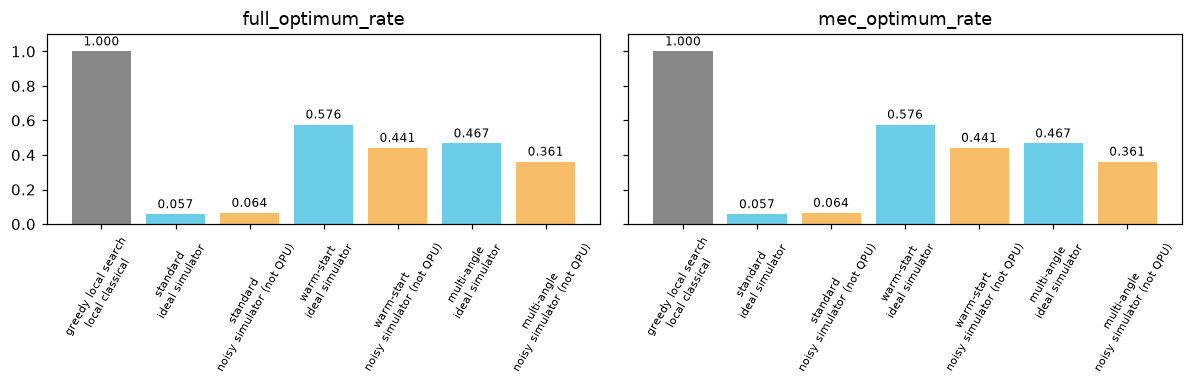

In [101]:
bench = pd.DataFrame(BENCH_ROWS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, metric in zip(axes, ['full_optimum_rate', 'mec_optimum_rate']):
    labels = [f"{r.method}\n{r.mode}" for r in bench.itertuples()]
    bars = ax.bar(range(len(bench)), bench[metric], color=['#888'] + ['#6ACCE6', '#F7BD69'] * 3)
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=8)
    ax.set_xticks(range(len(bench)), labels, rotation=60, fontsize=7)
    ax.set_title(metric)
    ax.set_ylim(0, 1.1)
fig.tight_layout()
plt.show()


### Shared 8-/12-SNP comparison (Tudor, agreed team plan)

Three fixed seeds per size; read spans 2–4 SNPs, coverage 6, 5% call errors and 10% missing calls. **Unweighted, unpruned evidence** is the clean control. Local search and all three QAOA variants see exactly the same reads. Quantum depth 1, one local training start, 60 evaluations, 512 shots per mode. Iteration-limit fits are shown explicitly.

The noisy backend is a **seeded synthetic 12-qubit line**, not IBM calibration data or a QPU. Angles are fitted once, then reused unchanged for ideal/noisy replay. Warm-start uses a classical seed; its classical preparation work is recorded.

In [102]:
def shared_size_metrics(samples, dataset, a, d, j, offset, full_opt, mec_opt):
    full = pairwise_scores(samples, a, d)
    mec = mec_scores(samples, dataset.reads)
    linked = linked_boundaries(a, d)
    return dict(
        sample_count=len(samples), best_full_cost=float(full.min()),
        full_mean=float(full.mean()),
        optimum_rate=float(np.isclose(full, full_opt, rtol=0, atol=1e-9).mean()),
        mec_mean=float(mec.mean()),
        mec_optimum_rate=float(np.isclose(mec, mec_opt, rtol=0, atol=1e-9).mean()),
        mean_switch_errors=float(np.mean([
            switch_errors(answer, dataset.truth, linked) for answer in samples])),
    )


def run_shared_size_study(sizes, seeds, read_settings, p=1, shots=512,
                          train_evals=60, local_budget=128, local_restarts=16):
    from qiskit.providers.fake_provider import GenericBackendV2

    if (not sizes or not seeds or len(set(sizes)) != len(sizes)
            or len(set(seeds)) != len(seeds)
            or any(not isinstance(size, int) or not 2 <= size <= 12 for size in sizes)
            or any(not isinstance(seed, int) or seed < 0 for seed in seeds)
            or any(not isinstance(value, int) or value < 1
                   for value in (p, shots, train_evals, local_budget, local_restarts))):
        raise ValueError('Use unique 2–12-SNP sizes, nonnegative integer seeds and positive budgets.')
    capacity = max(sizes)
    line = [(i, i + 1) for i in range(capacity - 1)]
    study_backend = GenericBackendV2(
        num_qubits=capacity, coupling_map=line + [(j, i) for i, j in line], seed=7)
    simulators = {
        'ideal simulator': AerSimulator(max_parallel_threads=1),
        'synthetic noisy simulator (not QPU)': AerSimulator(
            noise_model=NoiseModel.from_backend(study_backend), max_parallel_threads=1),
    }
    rows, artifacts, raw_counts = [], {}, {}
    for size in sizes:
        for seed in seeds:
            dataset = make_instance(size, seed=seed, **read_settings)
            a, d = pairwise_evidence(dataset.reads)
            j, offset = ising(a, d)
            states = bits(np.arange(2 ** size), size)
            energy = costs(states, j, offset)
            full_opt, mec_opt = float(energy.min()), float(mec_scores(states, dataset.reads).min())
            common = dict(n=size, dataset_seed=seed, p=p, evidence='A baseline',
                          pruning='none', exact_optimum=full_opt, tied_labels=int(
                              np.isclose(energy, full_opt, rtol=0, atol=1e-9).sum()))
            started = time.perf_counter()
            _, local_samples, used, _ = greedy_local_search(
                j, offset, local_budget, local_restarts,
                np.random.default_rng(17000 + 100 * size + seed), target=full_opt)
            local_seconds = time.perf_counter() - started
            rows.append(dict(
                common, method='local search', mode='classical', unit='restart',
                **shared_size_metrics(local_samples, dataset, a, d, j, offset, full_opt, mec_opt),
                classical_seconds=local_seconds, cost_checks=int(used.sum()),
                training_evals=0, training_seconds=0.0,
                warm_seed_checks=0, warm_seed_seconds=0.0))
            classical_seed = local_samples[0].astype(float)
            standard, params, _ = make_qaoa(j, p)
            warm, warm_params = warm_start_qaoa(size, j, classical_seed, p, eps=0.25)
            multi, multi_params = make_ma_qaoa(j, p)
            templates = {'standard': (standard, list(params)),
                         'warm-start': (warm, warm_params),
                         'multi-angle': (multi, multi_params)}
            entry = dict(reads=dataset.reads.copy(), truth_for_grading=dataset.truth.copy(),
                         J=j.copy(), offset=offset, p=p, full_optimum=full_opt,
                         frozen={}, angles={}, parameters={}, training={})
            artifacts[(size, seed)] = entry
            for method, (circuit, params) in templates.items():
                if train_evals < circuit.num_parameters + 2:
                    raise ValueError(f'{method} needs at least parameter_count + 2 training evaluations.')
                started = time.perf_counter()
                frozen, fitted, evaluations = local_frozen_fit(
                    circuit, params, energy, maxiter=train_evals, seed=71 + seed, n_starts=1)
                training_seconds = time.perf_counter() - started
                assert frozen.num_parameters == 0 and len(fitted.x) == len(params)
                entry['frozen'][method] = frozen
                entry['angles'][method] = fitted.x.copy()
                entry['parameters'][method] = [str(param) for param in params]
                fit_info = dict(training_evals=evaluations, training_seconds=training_seconds,
                                parameters=len(params), converged=bool(fitted.success),
                                optimizer_message=str(fitted.message),
                                warm_seed_checks=int(used.sum()) if method == 'warm-start' else 0,
                                warm_seed_seconds=local_seconds if method == 'warm-start' else 0.0)
                entry['training'][method] = fit_info
                for mode, simulator in simulators.items():
                    measured = frozen.copy()
                    measured.measure_all()
                    compiled = transpile(
                        measured, study_backend if mode.startswith('synthetic') else simulator,
                        optimization_level=1, seed_transpiler=7 + seed)
                    started = time.perf_counter()
                    counts = simulator.run(compiled, shots=shots, seed_simulator=72 + seed).result().get_counts()
                    sample_seconds = time.perf_counter() - started
                    samples = samples_from_counts(counts, size)
                    assert samples.shape == (shots, size), (size, seed, method, mode)
                    raw_counts[(size, seed, method, mode)] = counts
                    rows.append(dict(
                        common, method=method, mode=mode, unit='shot',
                        **shared_size_metrics(samples, dataset, a, d, j, offset, full_opt, mec_opt),
                        **fit_info, sampling_seconds=sample_seconds, **resources(compiled)))
            print(f'Completed shared {size}-SNP instance, seed {seed}: local search + 3 circuits in 2 modes.',
                  flush=True)
    return pd.DataFrame(rows), artifacts, raw_counts


def summarize_shared_size_study(frame):
    keys = ['n', 'method', 'mode', 'unit']
    result = frame.groupby(keys, sort=False).agg(
        datasets=('dataset_seed', 'nunique'), trials_per_dataset=('sample_count', 'first'),
        optimum_rate=('optimum_rate', 'mean'), seed_rate_std=('optimum_rate', 'std'),
        mean_best_cost=('best_full_cost', 'mean'), full_mean=('full_mean', 'mean'),
        mec_mean=('mec_mean', 'mean'), mean_switch_errors=('mean_switch_errors', 'mean'),
        mean_training_evals=('training_evals', 'mean'), mean_training_seconds=('training_seconds', 'mean'),
        mean_2q_gates=('2q gates', 'mean'), mean_depth=('depth', 'mean'),
    ).reset_index()
    return result

In [103]:
if RUN_SHARED_SIZE_STUDY:
    SHARED_SIZE_RESULTS, SHARED_SIZE_ARTIFACTS, SHARED_SIZE_COUNTS = run_shared_size_study(
        SHARED_STUDY_SIZES, SHARED_STUDY_SEEDS, SHARED_STUDY_READS,
        p=SHARED_STUDY_DEPTH, shots=SHARED_STUDY_SHOTS,
        train_evals=SHARED_STUDY_TRAIN_EVALS, local_budget=SHARED_STUDY_LOCAL_BUDGET,
        local_restarts=SHARED_STUDY_LOCAL_RESTARTS)
    SHARED_SIZE_SUMMARY = summarize_shared_size_study(SHARED_SIZE_RESULTS)
    display(SHARED_SIZE_SUMMARY.round(4))
    fits = SHARED_SIZE_RESULTS[SHARED_SIZE_RESULTS['mode'] == 'ideal simulator']
    display(fits[['n', 'dataset_seed', 'method', 'parameters', 'training_evals',
                  'converged', 'optimizer_message', 'warm_seed_checks']])
    assert len(SHARED_SIZE_RESULTS) == len(SHARED_STUDY_SIZES) * len(SHARED_STUDY_SEEDS) * 7
    assert set(SHARED_SIZE_RESULTS['pruning']) == {'none'}
    assert set(SHARED_SIZE_RESULTS['evidence']) == {'A baseline'}
    for key, artifact in SHARED_SIZE_ARTIFACTS.items():
        assert np.isclose(artifact['full_optimum'],
                          banded_exact(artifact['J'], artifact['offset']))
        assert set(artifact['frozen']) == {'standard', 'warm-start', 'multi-angle'}
        assert all(circuit.num_parameters == 0 for circuit in artifact['frozen'].values())
    print('PASS: shared inputs, exact references, frozen replay, complete 8/12-SNP comparison.')
else:
    print('Shared size study skipped: set RUN_SHARED_SIZE_STUDY = True in section 1.')

Completed shared 8-SNP instance, seed 0: local search + 3 circuits in 2 modes.


Completed shared 8-SNP instance, seed 1: local search + 3 circuits in 2 modes.


Completed shared 8-SNP instance, seed 2: local search + 3 circuits in 2 modes.


Completed shared 12-SNP instance, seed 0: local search + 3 circuits in 2 modes.


Completed shared 12-SNP instance, seed 1: local search + 3 circuits in 2 modes.


Completed shared 12-SNP instance, seed 2: local search + 3 circuits in 2 modes.


,n,method,mode,unit,datasets,trials_per_dataset,optimum_rate,seed_rate_std,mean_best_cost,full_mean,mec_mean,mean_switch_errors,mean_training_evals,mean_training_seconds,mean_2q_gates,mean_depth
0,8,local search,classical,restart,3,16,1.000,0.000,3.667,3.667,2.000,0.000,0.000,0.000,NaN,NaN
1,8,standard,ideal simulator,shot,3,512,0.036,0.034,3.667,17.814,9.503,2.820,35.333,0.055,14.000,14.333
2,8,standard,synthetic noisy simulator (not QPU),shot,3,512,0.036,0.030,3.667,17.803,9.574,2.872,35.333,0.055,56.667,84.000
3,8,warm-start,ideal simulator,shot,3,512,0.301,0.188,3.667,10.503,5.893,1.670,47.333,0.091,14.000,14.333
4,8,warm-start,synthetic noisy simulator (not QPU),shot,3,512,0.247,0.131,3.667,11.964,6.629,1.900,47.333,0.091,56.667,85.000
5,8,multi-angle,ideal simulator,shot,3,512,0.081,0.065,3.667,14.455,7.782,2.523,60.000,0.096,14.000,14.333
6,8,multi-angle,synthetic noisy simulator (not QPU),shot,3,512,0.083,0.071,3.667,15.370,8.221,2.645,60.000,0.096,56.667,84.000
7,12,local search,classical,restart,3,16,0.875,0.062,5.667,6.125,2.917,0.125,0.000,0.000,NaN,NaN
8,12,standard,ideal simulator,shot,3,512,0.017,0.021,6.333,25.524,13.061,3.885,41.333,0.114,24.333,21.667
9,12,standard,synthetic noisy simulator (not QPU),shot,3,512,0.010,0.011,8.333,26.938,13.827,4.137,41.333,0.114,135.000,148.667


,n,dataset_seed,method,parameters,training_evals,converged,optimizer_message,warm_seed_checks
1,8,0,standard,2.0,35,True,Return from COBYLA because the trust region ra...,0
3,8,0,warm-start,2.0,39,True,Return from COBYLA because the trust region ra...,2048
5,8,0,multi-angle,23.0,60,False,Return from COBYLA because the objective funct...,0
8,8,1,standard,2.0,35,True,Return from COBYLA because the trust region ra...,0
10,8,1,warm-start,2.0,60,False,Return from COBYLA because the objective funct...,2048
12,8,1,multi-angle,20.0,60,False,Return from COBYLA because the objective funct...,0
15,8,2,standard,2.0,36,True,Return from COBYLA because the trust region ra...,0
17,8,2,warm-start,2.0,43,True,Return from COBYLA because the trust region ra...,2048
19,8,2,multi-angle,23.0,60,False,Return from COBYLA because the objective funct...,0
22,12,0,standard,2.0,39,True,Return from COBYLA because the trust region ra...,0


PASS: shared inputs, exact references, frozen replay, complete 8/12-SNP comparison.


**Read the table carefully:** rates average across independent dataset seeds. `seed_rate_std` shows between-dataset variation, not a confidence interval. Classical rates are per restart; quantum rates are per shot. Training is reused across modes, so do not double-count it by summing both mode rows. These measurements do not establish a quantum speedup.

### Handoff to Alex

`SHARED_SIZE_ARTIFACTS[(size, seed)]` retains exact reads, J, frozen circuits, ordered parameters and angles. The first configured size/seed is the predetermined pilot. Truth is retained only for grading, not exported as an execution input. Set `SAVE_OUTPUTS = True` to save all datasets and portable QPY circuits. **Real hardware submission is still pending.**

In [104]:
if RUN_SHARED_SIZE_STUDY:
    import json
    pilot_key = (SHARED_STUDY_SIZES[0], SHARED_STUDY_SEEDS[0])
    pilot = SHARED_SIZE_ARTIFACTS[pilot_key]
    print('Predetermined hardware pilot (not selected by its measured performance):', pilot_key)
    print('Reads:', pilot['reads'].tolist())
    print('Frozen angles:', {name: values.tolist() for name, values in pilot['angles'].items()})
    print('Ordered parameter names:', pilot['parameters'])
    if SAVE_OUTPUTS:
        from qiskit import qpy
        folder = OUTPUT_DIR / 'shared_size_study'
        folder.mkdir(parents=True, exist_ok=True)
        SHARED_SIZE_RESULTS.to_csv(folder / 'per_dataset.csv', index=False)
        SHARED_SIZE_SUMMARY.to_csv(folder / 'summary.csv', index=False)
        for (size, seed), artifact in SHARED_SIZE_ARTIFACTS.items():
            record = dict(n=size, seed=seed, reads=artifact['reads'].tolist(),
                          J=artifact['J'].tolist(), offset=artifact['offset'], p=artifact['p'],
                          angles={name: values.tolist() for name, values in artifact['angles'].items()},
                          parameters=artifact['parameters'])
            (folder / f'instance_{size}_seed_{seed}.json').write_text(json.dumps(record, indent=2))
            with (folder / f'circuits_{size}_seed_{seed}.qpy').open('wb') as stream:
                qpy.dump(list(artifact['frozen'].values()), stream)
        print('Saved all shared datasets and frozen circuits for Alex:', folder)

Predetermined hardware pilot (not selected by its measured performance): (8, 0)
Reads: [[-1, -1, -1, -1, -1, 1, 1, -1], [-1, -1, -1, -1, -1, 0, 1, -1], [-1, -1, -1, -1, -1, -1, -1, 1], [-1, -1, -1, -1, 1, 1, -1, -1], [-1, -1, -1, -1, 1, 1, 1, -1], [-1, -1, 0, 1, 1, -1, -1, -1], [-1, 0, 0, 1, -1, -1, -1, -1], [-1, 1, 1, -1, 0, -1, -1, -1], [-1, 0, 0, 1, 1, -1, -1, -1], [-1, -1, -1, 0, 0, -1, -1, -1], [-1, -1, -1, 0, 0, 0, 0, -1], [-1, -1, -1, -1, 0, 1, 1, 1], [-1, -1, -1, 0, 0, -1, -1, -1], [-1, -1, -1, 1, -1, -1, -1, -1], [-1, -1, -1, -1, -1, 1, -1, -1], [-1, -1, 1, 0, 0, -1, -1, -1], [1, 1, -1, -1, -1, -1, -1, -1]]
Frozen angles: {'standard': [1.8180668854514346, 2.601014672787241], 'warm-start': [0.42146653409990065, 0.5209481629254332], 'multi-angle': [0.5002558146327332, 1.0844179462248476, 1.7195616994729606, 1.2793319010470088, 1.0032799190306476, 1.2446194972027407, 1.5951848684272687, 1.682986208108365, 2.9963228412744907, 1.123330916968305, 2.0244957692195404, 0.63207940660892

# 10. Optional deeper research and scaling

Every QAOA number here is a classical simulation. Short-read phasing is easy for exact classical DP; quantum value would need
long-range links. Tudor's MPS timings and 28–100 SNP race are off by default (`RUN_SCALING`); his 43-minute Kaggle run is off
(`RUN_KAGGLE_RACE`). Alex's larger-instance runner (merged to `main` in `9771f67`) runs at its small 12-SNP default.


In [105]:
mem = pd.DataFrame({"N qubits": [20, 24, 26, 30, 34, 40, 50, 100]})
mem["statevector memory"] = [f"{16 * 2 ** n / 1e9:,.3g} GB" for n in mem["N qubits"]]
mem["fits in"] = ["laptop", "laptop", "laptop (1 GB, our limit)", "big server", "supercomputer node", "no", "no", "no"]
mem


,N qubits,statevector memory,fits in
0,20,0.0168 GB,laptop
1,24,0.268 GB,laptop
2,26,1.07 GB,"laptop (1 GB, our limit)"
3,30,17.2 GB,big server
4,34,275 GB,supercomputer node
5,40,1.76e+04 GB,no
6,50,1.8e+07 GB,no
7,100,2.03e+22 GB,no


In [106]:
if RUN_SCALING:
    def time_mps(n, p=1, direction="mps_swap_right"):
        inst = make_instance(n, seed=0, **REAL)
        Jn, _ = ising(*pairwise_evidence(inst.reads))
        qc, theta, _ = make_qaoa(Jn, p)
        angles = np.r_[[0.5] * p, [-0.3] * p]
        job = dict(J=Jn, E=None, builder="baseline", angles=angles, circuit=qc.assign_parameters(dict(zip(theta, angles))))
        AER_OPTIONS["matrix_product_state"]["mps_swap_direction"] = direction
        try:
            t = time.time()
            REGISTRY["backend"]["aer_mps"](job, 2048, 1)
            return time.time() - t
        finally:
            AER_OPTIONS["matrix_product_state"]["mps_swap_direction"] = "mps_swap_right"


    time_mps(8)   # warm-up: the first Aer call loads the library
    sizes = [16, 18] + ([20, 24] if SLOW_DEMOS else [])
    swap = pd.DataFrame([dict(N=n, swap_right_s=time_mps(n), swap_left_s=time_mps(n, direction="mps_swap_left")) for n in sizes])
    swap["slower by"] = (swap.swap_left_s / swap.swap_right_s).round(0)
    display(swap)

    display(pd.DataFrame([dict(N=n, p=p, seconds=round(time_mps(n, p), 2)) for n in (24, 48, 100) for p in (1, 3)]))
else:
    print('MPS timings skipped (RUN_SCALING = False). Saved: 0.62 s at 100 SNPs (p = 1), 5.5 s (p = 3); swap-left was 7-13x slower at 16-18 SNPs.')


MPS timings skipped (RUN_SCALING = False). Saved: 0.62 s at 100 SNPs (p = 1), 5.5 s (p = 3); swap-left was 7-13x slower at 16-18 SNPs.


**Race beyond statevector sizes (28–100 SNPs, Aer MPS).** **Saved Kaggle medians** (5 puzzles per size): P_budget at 32 SNPs —
QAOA p = 3 1.00, p = 2 0.87, local 0.55, annealing 0.19; at 48+ SNPs QAOA had zero observed successes on the median puzzle while
local search kept small rates (0.09 at 48, 0.02 at 64). Median switch errors at 100 SNPs: annealing 4, local 7, QAOA p = 3 9.


In [107]:
if RUN_SCALING:
    big = pd.DataFrame(run_bench([28, 32, 48, 64, 100], 2, Config(methods=("random", "local", "sa", "qaoa"), ps=(1, 2, 3), gen=REAL)))
    display(pd.concat({"P_budget": big.groupby(["n", "method"])["P_budget"].median().unstack().round(2),
               "switch_err": big.groupby(["n", "method"])["switch_err"].median().unstack()}, axis=1))
else:
    print('28-100 SNP race skipped (RUN_SCALING = False); saved medians above.')


28-100 SNP race skipped (RUN_SCALING = False); saved medians above.


In [108]:
KAGGLE_RUNS = {
    "sv_realistic": (["toy", 8, 12, 16, 20, 22, 24, 26], Config(ps=(1, 2, 3), gen=REAL)),
    "mps_realistic": ([28, 32, 48, 64, 100], Config(methods=("random", "local", "sa", "qaoa"), ps=(1, 2, 3), gen=REAL)),
    "sv_noiseless": ([8, 12, 16, 20, 24], Config(ps=(1, 2, 3))),
}
if RUN_KAGGLE_RACE:
    for name, (sizes, cfg) in KAGGLE_RUNS.items():
        t = time.time()
        df = pd.DataFrame(run_bench(sizes, 5, cfg))
        out = str(OUTPUT_DIR / "results" / name) if SAVE_OUTPUTS else None
        if out:
            os.makedirs(out, exist_ok=True)
            df.to_csv(os.path.join(out, "results.csv"), index=False)
        plot(df, out)
        print(f"{name}: {len(df)} rows in {time.time() - t:.0f} s -> {out}")
        display(summarize(df))
else:
    print("RUN_KAGGLE_RACE = False: showing the stored Kaggle medians above.")


RUN_KAGGLE_RACE = False: showing the stored Kaggle medians above.


### Larger-instance experiments (Alex, `main` @ `9771f67`)
Synthetic reads with a fixed read length (or `SCALE_INPUT_MODE = 'custom'` with your own matrix), QAOA trained from
**finite-shot** Aer MPS samples (no statevector), exact search only up to `SCALE_EXACT_LIMIT`; above it only best sampled and
mean cost are reported, never an optimum claim. The optional IBM-calibrated noise run is local Aer (no QPU job) and needs
`RUN_IBM_NOISE_SIM`. **Saved original run:** 12 SNPs, 30 reads, 45 observed pairs; ideal Aer mean cost 133.8 (uniform 225),
optimum frequency 0.053, best sampled 15 = exact minimum 15.


In [109]:
#@title Select or generate a larger read matrix

def make_synthetic_reads(n_snps, n_reads, read_length, error_rate=0.0, seed=2026):
    if n_snps < 2 or n_reads < 1 or not 2 <= read_length <= n_snps:
        raise ValueError('Require n_snps >= read_length >= 2 and n_reads >= 1.')
    if not 0 <= error_rate <= 1:
        raise ValueError('error_rate must be between 0 and 1.')
    rng = np.random.default_rng(seed)
    hidden = rng.integers(0, 2, n_snps)
    reads = np.full((n_reads, n_snps), -1, dtype=np.int8)
    for row in reads:
        start = int(rng.integers(0, n_snps - read_length + 1))
        haplotype = hidden if rng.integers(2) == 0 else 1 - hidden
        calls = haplotype[start:start + read_length].copy()
        calls ^= (rng.random(read_length) < error_rate).astype(np.int8)
        row[start:start + read_length] = calls
    return reads

# Use custom mode and replace CUSTOM_READS with a matrix or np.loadtxt('reads.csv', delimiter=',', dtype=int).
SCALE_INPUT_MODE = 'synthetic'  # 'synthetic' or 'custom'
SCALE_N_SNPS = 12
SCALE_N_READS = 30
SCALE_READ_LENGTH = 6
SCALE_ERROR_RATE = 0.02
SCALE_SEED = 2026
CUSTOM_READS = READS

if SCALE_INPUT_MODE == 'synthetic':
    SCALE_READS = make_synthetic_reads(SCALE_N_SNPS, SCALE_N_READS, SCALE_READ_LENGTH,
                                       SCALE_ERROR_RATE, SCALE_SEED)
elif SCALE_INPUT_MODE == 'custom':
    SCALE_READS = np.asarray(CUSTOM_READS, dtype=int)
else:
    raise ValueError("SCALE_INPUT_MODE must be 'synthetic' or 'custom'.")

if SCALE_READS.ndim != 2 or SCALE_READS.shape[0] == 0 or SCALE_READS.shape[1] < 2:
    raise ValueError('Reads must be a non-empty 2D matrix with at least two SNP columns.')
if not np.isin(SCALE_READS, [-1, 0, 1]).all():
    raise ValueError('Read entries must be -1 (missing), 0, or 1.')
if not (SCALE_READS >= 0).any(axis=1).all():
    raise ValueError('Every read must cover at least one SNP.')
SCALE_N = SCALE_READS.shape[1]
SCALE_A, SCALE_D = build_evidence(SCALE_READS)
SCALE_J, SCALE_OFFSET = ising_from_evidence(SCALE_A, SCALE_D)
SCALE_EXACT_LIMIT = 14
if SCALE_N <= SCALE_EXACT_LIMIT:
    SCALE_EXACT_STATES, SCALE_EXACT_COSTS = exact_reference(SCALE_A, SCALE_D)
    SCALE_OPTIMUM = float(SCALE_EXACT_COSTS.min())
else:
    SCALE_EXACT_STATES = SCALE_EXACT_COSTS = SCALE_OPTIMUM = None

print(f'{SCALE_N} SNPs, {len(SCALE_READS)} reads, '
      f'{np.count_nonzero(SCALE_A + SCALE_D)} observed pairs; '
      f'exact reference: {"yes" if SCALE_OPTIMUM is not None else "skipped (above limit)"}.')


12 SNPs, 30 reads, 45 observed pairs; exact reference: yes.


In [110]:
#@title Train and sample shot-based QAOA on local Aer
SCALE_P = 1
SCALE_TRAIN_SHOTS = 512
SCALE_FINAL_SHOTS = 2048
SCALE_MAXITER = 40
SCALE_STARTS = 1

SCALE_ANSATZ, SCALE_THETA, SCALE_ANGLE_SCALE = lab_make_qaoa(SCALE_J, SCALE_P)
SCALE_MEASURED = SCALE_ANSATZ.copy()
SCALE_MEASURED.measure_all()
SCALE_SIM = AerSimulator(method='matrix_product_state', max_parallel_threads=1)
SCALE_RNG = np.random.default_rng(SCALE_SEED + 1)

def scale_mean_cost(counts):
    total = sum(counts.values())
    return sum(pairwise_cost(decode_key(key, SCALE_N), SCALE_A, SCALE_D) * count
               for key, count in counts.items()) / total

def scale_objective(values):
    bound = SCALE_MEASURED.assign_parameters(dict(zip(SCALE_THETA, values)))
    counts = SCALE_SIM.run(bound, shots=SCALE_TRAIN_SHOTS,
                           seed_simulator=int(SCALE_RNG.integers(1, 2**31 - 1))).result().get_counts()
    return scale_mean_cost(counts)

SCALE_TRIALS = [minimize(scale_objective, SCALE_RNG.uniform(0, np.pi, 2 * SCALE_P),
                         method='COBYLA', options={'maxiter': SCALE_MAXITER})
                for _ in range(SCALE_STARTS)]
SCALE_TRAINED = min(SCALE_TRIALS, key=lambda result: result.fun)
SCALE_FIXED = SCALE_MEASURED.assign_parameters(dict(zip(SCALE_THETA, SCALE_TRAINED.x)))
SCALE_IDEAL_COUNTS = SCALE_SIM.run(SCALE_FIXED, shots=SCALE_FINAL_SHOTS,
                                   seed_simulator=SCALE_SEED + 2).result().get_counts()

def scale_summary(name, counts, depth):
    scored = [(pairwise_cost(decode_key(key, SCALE_N), SCALE_A, SCALE_D), count)
              for key, count in counts.items()]
    total = sum(count for _, count in scored)
    return {'method': name, 'best sampled cost': min(cost for cost, _ in scored),
            'mean cost': sum(cost * count for cost, count in scored) / total,
            'uniform mean cost': SCALE_OFFSET,
            'optimum frequency': (sum(count for cost, count in scored
                                       if np.isclose(cost, SCALE_OPTIMUM)) / total
                                  if SCALE_OPTIMUM is not None else np.nan),
            'shots': total, 'depth': depth}

SCALE_RESULTS = [scale_summary('ideal Aer', SCALE_IDEAL_COUNTS, SCALE_MEASURED.depth())]
display(pd.DataFrame(SCALE_RESULTS).round(3))
print(f'Optimizer evaluations: {sum(result.nfev for result in SCALE_TRIALS)}; '
      f'best trained estimate: {SCALE_TRAINED.fun:.3f}; '
      f'exact model minimum: {SCALE_OPTIMUM if SCALE_OPTIMUM is not None else "not computed"}.')


,method,best sampled cost,mean cost,uniform mean cost,optimum frequency,shots,depth
0,ideal Aer,15,133.825,225.0,0.053,2048,24


Optimizer evaluations: 29; best trained estimate: 132.230; exact model minimum: 15.0.


In [111]:
#@title Connect to an IBM backend for local noise data (no QPU submission)
SCALE_NOISE_BACKEND_NAME = IBM_BACKEND_NAME
SCALE_NOISE_SIM = SCALE_NOISE_BACKEND = SCALE_NOISE_CIRCUIT = None

if RUN_IBM_NOISE_SIM:
    SCALE_NOISE_BACKEND = get_ibm_service().backend(SCALE_NOISE_BACKEND_NAME)
    if SCALE_N > SCALE_NOISE_BACKEND.num_qubits:
        raise ValueError(f'Instance has {SCALE_N} SNPs but backend has only '
                         f'{SCALE_NOISE_BACKEND.num_qubits} qubits.')
    SCALE_NOISE_SIM = AerSimulator.from_backend(
        SCALE_NOISE_BACKEND, method='matrix_product_state', max_parallel_threads=1)
    SCALE_NOISE_CIRCUIT = generate_preset_pass_manager(
        backend=SCALE_NOISE_BACKEND, optimization_level=1, seed_transpiler=SCALE_SEED).run(SCALE_MEASURED)
    print(f'Logical qubits: {SCALE_N}; transpiled circuit width: {SCALE_NOISE_CIRCUIT.num_qubits}; '
          f'depth: {SCALE_NOISE_CIRCUIT.depth()}; '
          f'two-qubit gates: {sum(item.operation.num_qubits == 2 for item in SCALE_NOISE_CIRCUIT.data)}.')
else:
    print('IBM-calibrated noise simulation is off; no credentials requested.')


IBM-calibrated noise simulation is off; no credentials requested.


In [112]:
#@title Run the optional local IBM-noise simulation
if SCALE_NOISE_SIM is None:
    print('Enable RUN_IBM_NOISE_SIM in the preceding cell, then run this cell.')
else:
    SCALE_NOISE_BOUND = SCALE_NOISE_CIRCUIT.assign_parameters(
        dict(zip(SCALE_THETA, SCALE_TRAINED.x)))
    SCALE_NOISE_COUNTS = SCALE_NOISE_SIM.run(
        SCALE_NOISE_BOUND, shots=SCALE_FINAL_SHOTS,
        seed_simulator=SCALE_SEED + 3).result().get_counts()
    SCALE_RESULTS.append(scale_summary('IBM calibration noise (local Aer)',
                                       SCALE_NOISE_COUNTS, SCALE_NOISE_CIRCUIT.depth()))
    display(pd.DataFrame(SCALE_RESULTS).round(3))
    print('Local Aer simulation only; no IBM QPU job was submitted.')


Enable RUN_IBM_NOISE_SIM in the preceding cell, then run this cell.


# 11. Checks, inventory and conclusions

Tudor's engine checks, organizer fallback equivalence, and the integration invariants: baseline labels, objective
disagreement with common rescoring, fractional evidence through pruning, little-endian decoding, arbitrary parameter binding,
fully pruned and single-SNP training, and preserved default distributions.


In [113]:
def check_all():
    # 9.1 toy = baseline notebook
    A, D = pairwise_evidence(TOY_READS)
    assert (A[0, 1], D[0, 1], A[1, 2], D[2, 3], A[1, 4] + D[1, 4]) == (1, 2, 4, 4, 0)
    J, off = ising(A, D)
    E = diag_energies(J)
    best = np.flatnonzero(np.isclose(E, E.min()))
    assert off + E.min() == 1
    assert sorted("".join(map(str, x)) for x in bits(best, 5)) == ["01101", "10010"]
    print("9.1 toy matches the notebook: optimum cost 1 at 01101 and its mirror 10010")

    # 9.2 doubling trick and band DP = enumeration
    for seed, gaps in [(1, 0), (2, 1), (3, 2)]:
        inst = make_instance(11, error=0.1, missing=0.1, gaps=gaps, read_len=(2, 5), seed=seed)
        J, off = ising(*pairwise_evidence(inst.reads))
        c = costs(bits(np.arange(2 ** 11), 11), J, off)
        assert np.allclose(off + diag_energies(J), c)
        assert np.isclose(banded_exact(J, off), c.min())
    print("9.2 diag_energies and banded_exact agree with enumeration (errors, missing letters, gaps)")

    # 9.3 numpy simulator = Qiskit; p = 1 formula = simulator
    from qiskit.quantum_info import Statevector
    inst = make_instance(7, error=0.15, read_len=(2, 5), seed=5)
    J, off = ising(*pairwise_evidence(inst.reads))
    E = diag_energies(J)
    for angles in ([0.7, 0.3], [2.1, 1.2], [0.4, 1.1, 0.9, 0.2]):
        qc, theta, _ = make_qaoa(J, len(angles) // 2)
        ref = Statevector(qc.assign_parameters(dict(zip(theta, angles)))).probabilities()
        probs = np.abs(qaoa_state(J, np.array(angles), E)) ** 2
        assert np.allclose(probs, ref, atol=1e-10)
        if len(angles) == 2:
            assert np.isclose(p1_energy(J, off, angles[0], angles[1])[0], off + probs @ E)
    print("9.3 qaoa_state matches Qiskit Statevector; the p = 1 formula matches the simulated energy")

    # 9.4 formula >= notebook COBYLA on the toy
    J, off = ising(*pairwise_evidence(TOY_READS))
    angles, e_pred, _ = train_p1(J, off)
    assert np.isclose(e_pred, off + np.abs(qaoa_state(J, angles)) ** 2 @ diag_energies(J))
    assert e_pred <= 7.798 + 1e-6
    print(f"9.4 toy p = 1: formula expected cost {e_pred:.3f} <= notebook COBYLA 7.798, zero shots")

    # 9.5 transferred p = 2 beats p = 1 on an unseen puzzle
    angles2, _ = train_transfer(2, pre_ns=(8, 10), per_n=2)
    inst = make_instance(13, seed=123)
    J, off = ising(*pairwise_evidence(inst.reads))
    E = diag_energies(J)
    _, e1, _ = train_p1(J, off)
    e2 = off + np.abs(qaoa_state(J, angles2, E)) ** 2 @ E
    assert e2 < e1
    print(f"9.5 unseen 13-SNP puzzle: transferred p = 2 expected cost {e2:.3f} < p = 1 {e1:.3f}")

    # 9.6 Aer MPS: right distribution, and past 63 qubits
    for n, shots in ((9, 4000), (70, 16)):
        inst = make_instance(n, error=0.05, seed=6)
        J, off = ising(*pairwise_evidence(inst.reads))
        angles = np.array([0.4, 0.5, -0.6, -0.3])
        qc, theta, _ = make_qaoa(J, 2)
        job = dict(J=J, angles=angles, builder="baseline", circuit=qc.assign_parameters(dict(zip(theta, angles))))
        X, _ = REGISTRY["backend"]["aer_mps"](job, shots, 1)
        assert X.shape == (shots, n)
        if n <= 12:
            probs = np.abs(qaoa_state(J, angles)) ** 2
            seen = np.bincount(X @ (1 << np.arange(n)), minlength=2 ** n) / shots
            assert 0.5 * np.abs(seen - probs).sum() < 0.1
    print("9.6 Aer MPS samples match the exact distribution (9 qubits) and it runs at 70 qubits")

    # 9.7 switch errors
    truth = np.array([0, 1, 1, 0, 1, 0, 0, 1])
    flipped = truth.copy()
    flipped[4:] ^= 1
    linked = np.ones(7, dtype=bool)
    assert truth_distance(flipped, truth) == 4 and switch_errors(flipped, truth, linked) == 1
    assert switch_errors(1 - truth, truth, linked) == 0
    linked[3] = False
    assert switch_errors(flipped, truth, linked) == 0
    A, D = pairwise_evidence(make_instance(12, gaps=1, seed=2).reads)
    assert linked_boundaries(A, D).sum() == 10
    print("9.7 one swapped block = 1 switch error; unlinked boundaries are skipped")

    # 9.8 error-free reads: the truth is optimal with cost 0
    inst = make_instance(12, seed=4)
    J, off = ising(*pairwise_evidence(inst.reads))
    assert costs(inst.truth[None], J, off)[0] == 0 == banded_exact(J, off)
    print("9.8 error-free reads: the hidden truth has cost 0 and is optimal")


if not QGD_QUIET:
    t = time.time()
    check_all()
    print(f"all checks passed in {time.time() - t:.1f} s")


9.1 toy matches the notebook: optimum cost 1 at 01101 and its mirror 10010
9.2 diag_energies and banded_exact agree with enumeration (errors, missing letters, gaps)
9.3 qaoa_state matches Qiskit Statevector; the p = 1 formula matches the simulated energy
9.4 toy p = 1: formula expected cost 5.833 <= notebook COBYLA 7.798, zero shots


9.5 unseen 13-SNP puzzle: transferred p = 2 expected cost 9.416 < p = 1 14.617


9.6 Aer MPS samples match the exact distribution (9 qubits) and it runs at 70 qubits
9.7 one swapped block = 1 switch error; unlinked boundaries are skipped
9.8 error-free reads: the hidden truth has cost 0 and is optimal
all checks passed in 0.6 s


### Organizer fallback definitions (lab appendix) vs the team's implementations
Renamed with a `fallback_` prefix so they never overwrite the team's code; equivalence is checked on the shared input.


In [114]:
#@title Full fallback definitions · expand after trying { display-mode: "form" }

def fallback_build_evidence(reads):
    n=reads.shape[1];a=np.zeros((n,n));d=np.zeros((n,n))
    for row in reads:
        for i,j in itertools.combinations(np.flatnonzero(row>=0),2):
            if row[i]==row[j]: a[i,j]+=1
            else: d[i,j]+=1
    return a,d

def fallback_pairwise_cost(x,a,d):
    return float(sum(a[i,j] if x[i]!=x[j] else d[i,j]
                     for i,j in itertools.combinations(range(len(x)),2)))

def fallback_exact_reference(a,d):
    states=np.array(list(itertools.product([0,1],repeat=len(a))))
    costs=np.array([fallback_pairwise_cost(x,a,d) for x in states])
    return states,costs

def fallback_ising_from_evidence(a,d):
    return (d-a)/2, float((a+d).sum()/2)
def fallback_ising_energy(x,j,offset):
    z=1-2*np.asarray(x)
    return float(offset+sum(j[i,k]*z[i]*z[k]
                           for i,k in itertools.combinations(range(len(x)),2)))

def fallback_make_qaoa(j,p=1):
    n=len(j);scale=max(1.,float(np.abs(j).max()))
    theta=ParameterVector('theta',2*p);qc=QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        for i,k in itertools.combinations(range(n),2):
            if j[i,k]!=0: qc.rzz(2*theta[layer]*j[i,k]/scale,i,k)
        qc.rx(2*theta[p+layer],range(n))
    return qc,theta,scale

def fallback_expected_energy(values):
    return float(np.dot(probabilities(values),energy_array))


fa, fd = fallback_build_evidence(READS)
assert np.allclose((fa, fd), build_evidence(READS))
f_states, f_costs = fallback_exact_reference(fa, fd)
assert np.array_equal(f_states, LAB_STATES) and np.allclose(f_costs, LAB_COSTS)
fj, f_offset = fallback_ising_from_evidence(fa, fd)
assert np.allclose(fj, LAB_J) and np.isclose(f_offset, LAB_OFFSET)
assert all(np.isclose(fallback_ising_energy(x, fj, f_offset), c) for x, c in zip(f_states, f_costs))
probe = np.linspace(0.2, 1.0, 2 * LAB_P)
f_qc, f_theta, _ = fallback_make_qaoa(LAB_J, LAB_P)
assert np.allclose(Statevector(f_qc.assign_parameters(dict(zip(f_theta, probe)))).probabilities(), probabilities(probe))
assert np.isclose(fallback_expected_energy(probe), expected_energy(probe))
print('Team implementations match the organizer fallbacks on the shared input.')


Team implementations match the organizer fallbacks on the shared input.


### Integration invariants


In [115]:
# Fully pruned graphs and a single SNP keep complete angle vectors (unused cost angles = 0).
zero_j = np.zeros((3, 3))
zero_standard, zero_params, _ = make_qaoa(zero_j, 2)
zero_warm, zero_warm_params = warm_start_qaoa(3, zero_j, np.zeros(3), 2, eps=0.25)
for circuit, params in [(zero_standard, list(zero_params)), (zero_warm, zero_warm_params)]:
    frozen, fitted, _ = local_frozen_fit(circuit, params, np.zeros(8), maxiter=10)
    assert frozen.num_parameters == 0 and len(fitted.x) == len(params)
    assert np.allclose(fitted.x[:2], 0) and np.isclose(fitted.fun, 0)
one_j = np.zeros((1, 1))
one_standard, one_params, _ = make_qaoa(one_j, 1)
for circuit, params in [(one_standard, list(one_params)), warm_start_qaoa(1, one_j, np.zeros(1), 1, eps=0.25),
                        make_ma_qaoa(one_j, 1)]:
    frozen, fitted, _ = local_frozen_fit(circuit, list(params), np.array([0.0, 1.0]), maxiter=20)
    assert frozen.num_parameters == 0 and len(fitted.x) == len(params) and np.isfinite(fitted.fun)
print('PASS: fully pruned and single-SNP circuits retain full angle vectors.')

# Objective disagreement survives common rescoring (mixed-length counterexample).
counterexample = np.array([[0, 0, 0, 0], [0, 0, 0, 0], [0, 1, -1, -1], [0, 1, -1, -1], [0, 1, -1, -1]])
counter_states = bits(np.arange(16), 4)
cs, _ = objective_scores(counterexample, counter_states)
wa, wb = optimal_mask(cs['A baseline']), optimal_mask(cs['B1 per-read'])
assert not np.array_equal(wa, wb)
assert cs['A baseline'][wb].mean() > cs['A baseline'][wa].mean()

# Fractional evidence survives Carla's pruning adapter and exact referee.
fa, fd, _, _ = build_graph(np.array([[0, 1, 1]]), per_read_weight)
fk, _ = prune(fa, fd, 'none')
fpa, fpd = matrices_from_edges(3, fk)
assert np.allclose(fpa, fa) and np.allclose(fpd, fd)
_, fc = exact_reference(fpa, fpd)
assert np.allclose(fc, pairwise_scores(all_states(3), fa, fd))

# Arbitrary multi-angle parameter counts bind and start uniform.
for n_test, n_edges_test in [(3, 0), (3, 1), (5, 4)]:
    test_j = np.zeros((n_test, n_test))
    for i, j in list(itertools.combinations(range(n_test), 2))[:n_edges_test]:
        test_j[i, j] = -0.5
    qc, params = make_ma_qaoa(test_j, 2)
    assert len(params) == 2 * (n_edges_test + n_test)
    bound = qc.assign_parameters(dict(zip(params, np.zeros(len(params)))))
    assert bound.num_parameters == 0
    assert np.allclose(Statevector.from_instruction(bound).probabilities(), 1 / 2 ** n_test)

# Raw counts decode little-endian: qubit 0 (rightmost key character) is SNP 1.
deterministic = QuantumCircuit(N)
pattern = np.arange(N) % 2
for q in np.flatnonzero(pattern):
    deterministic.x(int(q))
deterministic.measure_all()
dc = ideal_sim.run(transpile(deterministic, ideal_sim), shots=16).result().get_counts()
assert np.array_equal(samples_from_counts(dc, N), np.tile(pattern, (16, 1)))
print('PASS: baseline/bit order, objective disagreement/common scoring, fractional evidence,')
print('arbitrary parameter binding, sampled plug-in trainer, raw-count decoding.')


PASS: fully pruned and single-SNP circuits retain full angle vectors.
PASS: baseline/bit order, objective disagreement/common scoring, fractional evidence,
arbitrary parameter binding, sampled plug-in trainer, raw-count decoding.


**Preserved default distributions.** With default settings this notebook should reproduce the previous merged run (validated
with Qiskit 2.5.0 / Aer 0.17.2); other library versions may sample differently.


In [116]:
SAVED_SUCCESSES = {('standard', 'ideal simulator'): 29, ('warm-start', 'ideal simulator'): 295,
                   ('multi-angle', 'ideal simulator'): 239, ('standard', 'noisy simulator (not QPU)'): 33,
                   ('warm-start', 'noisy simulator (not QPU)'): 226, ('multi-angle', 'noisy simulator (not QPU)'): 185}
defaults = (READS_OVERRIDE is None and OBJECTIVE == 'A baseline' and PRUNE_RULE == 'mstforest'
            and (P, SHOTS, MAXITER) == (1, 512, 60) and not RUN_FULL_STUDIES)
current = {(r['method'], r['mode']): round(r['full_optimum_rate'] * r['samples']) for r in BENCH_ROWS[1:]}
display(pd.DataFrame([dict(method=k[0], mode=k[1], saved=v, current=current.get(k)) for k, v in SAVED_SUCCESSES.items()]))
print('Default settings:', defaults, '| matches the saved merged run:', defaults and current == SAVED_SUCCESSES)


,method,mode,saved,current
0,standard,ideal simulator,29,29
1,warm-start,ideal simulator,295,295
2,multi-angle,ideal simulator,239,239
3,standard,noisy simulator (not QPU),33,33
4,warm-start,noisy simulator (not QPU),226,226
5,multi-angle,noisy simulator (not QPU),185,185


Default settings: True | matches the saved merged run: True


## Method inventory (generated at build time from the committed sources)

Every function and class defined in the contributors' sources is defined in this notebook (renamed only where two contributors used the same name).

| Source | Definitions | Names (original→notebook) | Section | Note |
|---|---:|---|---|---|
| `bench/qgd_bench.ipynb` | 42 | `register`, `Instance`, `toy_instance`, `show_reads`, `make_instance`, `pairwise_evidence`, `ising`, `costs`, `bits`, `decode_key`, `diag_energies`, `bandwidth`, `banded_exact`, `_sym`, `simulated_annealing`, `_greedy`, `greedy_local_search`, `qaoa_scale`, `make_qaoa`, `qaoa_state`, `p1_terms`, `p1_energy`, `canonical_beta`, `train_p1`, `interp`, `train_transfer`, `baseline_trainer`, `cobyla_trainer`, `numpy_backend`, `_aer`, `no_postprocess`, `tts99`, `tts99_runs`, `truth_distance`, `linked_boundaries`, `switch_errors`, `Config`, `run_instance`, `run_bench`, `summarize`, `plot`, `check_all` | 11, 2, 5, 6, 7, 9 |  |
| `bench/tudor_classical_vs_quantum.ipynb` | 1 | `time_mps` | 10 |  |
| `bench/plugin_template.ipynb` | 5 | `template_evidence`, `template_circuit`, `template_trainer`, `template_postprocess`, `template_backend` | 9 |  |
| `bench/shared_adapters.ipynb` | 1 | `local_frozen_fit` | 6 | loaders notebook_cells/load_definitions/load_quiet_engine/load_hardware replaced by direct definitions |
| `docs/Quantum_Genome_Detective_Lab.ipynb` | 37 | `show_reads→show_reads_figure`, `show_graph`, `text`, `build_evidence`, `pairwise_cost`, `exact_reference`, `ising_from_evidence`, `ising_energy`, `make_qaoa→lab_make_qaoa`, `bind`, `probabilities`, `expected_energy`, `sample_summary`, `show_comparison`, `train_ansatz`, `counts_of`, `warm_start_qaoa`, `make_ma_qaoa`, `two_qubit_gates`, `resources→lab_resources`, `edge_table`, `active_edges`, `components`, `n_blocks`, `prune`, `matrices_from_edges`, `hamming_phased`, `minima_reps`, `random_pick_accuracy`, `pruned_min_is_full_min`, `make_dataset`, `evaluate→evaluate_pruning`, `seed_avg`, `make_synthetic_reads`, `scale_mean_cost`, `scale_objective`, `scale_summary` | 10, 2, 4, 6, 7 | decode_key identical to the engine's (assert kept); Colab pip pins reported, not installed |
| `Lab setup (Alex, main)` | 2 | `read_local_env`, `get_ibm_service` | 1 | credential lookup made lazy |
| `Lab fallback appendix` | 7 | `build_evidence→fallback_build_evidence`, `pairwise_cost→fallback_pairwise_cost`, `exact_reference→fallback_exact_reference`, `ising_from_evidence→fallback_ising_from_evidence`, `ising_energy→fallback_ising_energy`, `make_qaoa→fallback_make_qaoa`, `expected_energy→fallback_expected_energy` | 11 |  |
| `docs/objective_study.py` | 18 | `baseline_weight`, `per_read_weight`, `per_site_weight`, `build_graph`, `all_states`, `pairwise_scores`, `mec_scores`, `objective_scores`, `evaluate`, `optimal_mask`, `score_metrics`, `generate_reads`, `make_manifest`, `run_study`, `mean_ci`, `summarize→summarize_objectives`, `write_csv`, `plot_results` | 3 |  |
| `docs/fixed_length_experiment.py` | 4 | `generate_fixed`, `run→run_fixed_length`, `plot→plot_fixed_length`, `report→report_fixed_length` | 3 | CLI __main__ replaced by toggle |
| `docs/length_error_experiment.py` | 7 | `error_probability`, `latent_dataset`, `observed_reads`, `validate→validate_length_error`, `run→run_length_error`, `plot→plot_length_error`, `report→report_length_error` | 3 | CLI __main__ replaced by toggle |
| `docs/hardware_experiments/hardware_setup.ipynb` | 7 | `configure_problem`, `cost`, `make_circuit`, `resources`, `score`, `boxplot_legend`, `logical_probabilities` | 7 |  |
| `docs/hardware_experiments/hardware_placement.ipynb` | 1 | `placement_study` | 8 | inside placement_study() |
| `docs/hardware_experiments/hardware_noise_aware_layout.ipynb` | 2 | `calibration_layout_study`, `error_exposure` | 8 | inside calibration_layout_study() |
| `docs/hardware_experiments/hardware_routing.ipynb` | 1 | `routing_study` | 8 | inside routing_study() |
| `docs/hardware_experiments/hardware_gate_order.ipynb` | 1 | `gate_order_study` | 8 | inside gate_order_study() |
| `docs/hardware_experiments/hardware_commuting_schedule.ipynb` | 2 | `commuting_schedule_study`, `make_circuit_with_edges` | 8 | inside commuting_schedule_study() |
| `docs/hardware_experiments/hardware_readout.ipynb` | 3 | `readout_study`, `local_matrices`, `corrected_cost` | 8 | inside readout_study() |
| `docs/hardware_experiments/hardware_trex.ipynb` | 6 | `trex_study`, `twirl_measurements`, `response_from_calibration`, `trex_scales`, `local_corrected_mean`, `trex_corrected_mean` | 8 | inside trex_study() |
| `docs/hardware_experiments/hardware_m3_readout.ipynb` | 3 | `m3_study`, `local_corrected_mean`, `m3_mean_cost` | 8 | inside m3_study() |
| `docs/hardware_experiments/hardware_dynamical_decoupling.ipynb` | 1 | `dynamical_decoupling_study` | 8 | inside dynamical_decoupling_study() |
| `docs/hardware_experiments/hardware_pauli_twirling.ipynb` | 1 | `pauli_twirling_study` | 8 | inside pauli_twirling_study() |
| `docs/hardware_experiments/hardware_zne.ipynb` | 2 | `zne_study`, `fold_two_qubit_gates` | 8 | inside zne_study() |

Not copied by design: `%run`/AST loaders, the Colab `pip install` cell, script `argparse` entry points and `matplotlib.use('Agg')`, the `hardware_inputs` injection, and template prompts without code. Generated result archives are not read; their key numbers are quoted as saved findings.


**New agreed Tudor study (§9):** `shared_size_metrics`, `run_shared_size_study`, `summarize_shared_size_study`. Existing contributor methods above remain unchanged.

## Conclusions and boundaries

* **Objectives (Alexandra):** weighting changes optima but normalization is not universally better; B1 helps only when long
  reads are systematically less reliable in simulation. MEC is an exact classical reference, not a circuit Hamiltonian.
* **Pruning (Carla):** removing weak edges destroys relationships once the active graph disconnects; `mstforest` shrinks
  circuits while keeping connectivity. Warm start and multi-angle change optimization cost, not two-qubit gate counts.
* **Classical vs quantum (Tudor):** zero-shot p = 1 training and transferred p = 2/3 angles work in ideal simulation;
  short-read phasing is solved exactly by band DP for thousands of SNPs, so no quantum need or time speedup is claimed.
* **Hardware (Alex):** on the FakeManila pilot, layout/routing/gate-order changes traded depth against two-qubit count without a
  clear noisy gain; readout corrections and ZNE moved mean-cost estimates toward references; DD and twirling showed no clear
  change. All are simulator snapshots.
* **Merged run:** one input, explicit objective and pruning choice, local frozen training, ideal and noisy replay rescored on
  common references. Small budgets and one noise seed do not establish statistical superiority. **Real QPU: not executed.**
  Recursive QAOA is not implemented. Real-hardware claims would need backend, shots and job IDs.
